# Notebook 01 — Análisis exploratorio y preparación de datos

**Proyecto:** Optimización de calendario y maximización de puntos ATP para tenistas profesionales argentinos
**Autor:** Sebastian Losinno · Licenciatura en Ciencia de Datos · Universidad CAECE
**Repositorio:** https://github.com/sebadenos/proyecto-final-tenis · **Corte de datos:** 19/10/2026

**Objetivo.** Evaluar si los datos disponibles permiten responder la pregunta del proyecto (qué combinación de variables del tenista y del torneo maximiza los puntos ATP esperados por gira) y decidir si el proyecto es viable antes del modelado. La notebook también construye las tablas externas (torneos, puntos, países y calendario 2026) y exporta los insumos de la notebook 02 (modelado y simulación).

**Reproducibilidad.** Todos los insumos se descargan del repositorio del proyecto: una copia de TennisMyLife al 19/10/2026, el calendario ATP 2026 y las tablas de torneos, puntos y países. La notebook corre de principio a fin sin pasos manuales.

**Ajustes de alcance respecto del planteo inicial**

| Aspecto | Planteo inicial | Versión final | Motivo |
|---|---|---|---|
| Población objetivo | Ranking 80–300 | **Ranking 100–300** | Cerca del top 100 el jugador ya entra directo a los Grand Slams. Por debajo de ~300 gana peso el circuito ITF, que no está en la base. |
| Fuente | Jeff Sackmann (*tennis_atp*) | **TennisMyLife**: ATP, Challenger y Qualy ATP | IDs oficiales de la ATP, actualización diaria y archivos de qualys. |
| Período | 2010–2025 | **2000–2026** | 2000–2006 funciona como calentamiento: el Elo converge y las qualys ATP recién existen desde 2007. |
| Validación | Validación cruzada temporal | **Train 2007–2021 · Validación 2022–2023 · Test 2024–2026** | Partición temporal estricta, sin fuga de información futura. |
| Objetivos de desempeño | AUC-ROC > 0.72 y Log-Loss < 0.60 | **Mejora sobre el baseline Elo recalibrado** | Los umbrales absolutos dependen de la mezcla de partidos; la simulación exige probabilidades calibradas (sección 9.1). |

El rango 100–300 define **a quién se le hace la recomendación**, no qué partidos se usan para aprender: el modelo se entrena con todos los partidos, porque un jugador de la población enfrenta rivales de cualquier ranking.

**Estructura:** 0 Configuración · 1 Presentación del conjunto de datos · 2 Descripción de variables · 3 Valores faltantes · 4 Outliers · 5 Construcción de atributos · 6 Análisis univariado · 7 Análisis bivariado · 8 Correlaciones y colinealidad · 9 Señal predictiva, viabilidad y objetivos · 10 Conclusiones · 11 Diccionario de datos · 12 Exportación · 13 Tablas de torneos, puntos y países, y calendario 2026

## 0. Configuración


In [1]:

# 0.1 Parámetros del proyecto

import time, warnings, zipfile, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import requests
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)

# Repositorio del proyecto: copia de TennisMyLife al corte de datos, tablas externas y salidas procesadas
REPO = 'sebadenos/proyecto-final-tenis'
URL_REPO = f'https://raw.githubusercontent.com/{REPO}/main'
FECHA_CORTE = '2026-10-19'
FUENTE_PARTIDOS = 'repositorio'         # 'tennismylife': versión vigente de la fuente (las cifras pueden variar)

BASE_DIR = Path('proyecto_final_tenis')
DATA_DIR = BASE_DIR / 'data_raw'        # partidos de TennisMyLife
EXT_DIR = BASE_DIR / 'data_externos'    # calendario ATP 2026 y tablas de torneos, puntos y países
OUT_DIR = BASE_DIR / 'outputs'
FIG_DIR = OUT_DIR / 'figuras'
for carpeta in (DATA_DIR, EXT_DIR, OUT_DIR, FIG_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)

def descargar_del_repo(ruta, destino):
    """Descarga un archivo del repositorio del proyecto, salvo que ya esté en disco."""
    destino = Path(destino)
    if destino.exists() and destino.stat().st_size > 0:
        return destino
    destino.parent.mkdir(parents=True, exist_ok=True)
    if URL_REPO.startswith('http'):
        r = requests.get(f'{URL_REPO}/{ruta}', timeout=120)
        r.raise_for_status()
        destino.write_bytes(r.content)
    else:                                   # ejecución desde una copia local del repositorio
        shutil.copy(Path(URL_REPO) / ruta, destino)
    return destino

# Alcance del proyecto
ANIO_INICIO, ANIO_FIN = 2000, 2026
ANIO_BURNIN_FIN = 2006                  # 2000-2006: calentamiento del Elo + período sin qualys ATP (existen desde 2007)
TRAIN, VALID, TEST = (2007, 2021), (2022, 2023), (2024, 2026)
RANK_MIN, RANK_MAX = 100, 300           # población objetivo
PAIS_FOCO = 'ARG'
RANK_CENTINELA = 3000                   # sin ranking: valor peor que el máximo observado (~2.300)
SEED = 42
np.random.seed(SEED)
print(f'Entorno listo. Pandas {pd.__version__} | Partidos: {FUENTE_PARTIDOS} (corte {FECHA_CORTE})')

Entorno listo. Pandas 2.2.3 | Partidos: repositorio (corte 2026-10-19)


In [2]:

# 0.2 Estilo gráfico y funciones auxiliares

C_PRINCIPAL, C_SECUNDARIO, C_FOCO, C_GRIS = '#1f5f7a', '#a9c9d6', '#d9822b', '#8c8c8c'
CIRCUITOS = ['ATP cuadro principal', 'Challenger', 'Qualy ATP']
PALETA_CIRCUITO = dict(zip(CIRCUITOS, ['#1f5f7a', '#5fa8a0', '#c9a227']))
SUPERFICIES = ['Clay', 'Hard', 'Grass', 'Carpet']
PALETA_SUP = {'Clay': '#c0603a', 'Hard': '#3b6fa0', 'Grass': '#5b9a4b', 'Carpet': '#8c7aa9'}
NOMBRE_SUP = {'Clay': 'Polvo de ladrillo', 'Hard': 'Cemento', 'Grass': 'Césped', 'Carpet': 'Carpeta'}
STATS = ['ace', 'df', 'svpt', '1stIn', '1stWon', '2ndWon', 'SvGms', 'bpSaved', 'bpFaced']
TRAMOS = [0, 100, 300, 600, np.inf]
ETIQ_TRAMOS = ['1–100', '101–300', '301–600', '>600']

sns.set_theme(style='white', context='notebook')
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlelocation': 'left',
    'axes.labelcolor': '#333333', 'xtick.color': '#555555', 'ytick.color': '#555555',
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.alpha': 0.25,
    'figure.dpi': 110, 'savefig.dpi': 150, 'legend.frameon': False,
})

def cerrar(nombre, fuente='Fuente: TennisMyLife (ATP, Challenger y Qualy ATP).'):
    fig = plt.gcf()
    plt.tight_layout()
    fig.text(0.01, -0.01, fuente, fontsize=8, color=C_GRIS, ha='left', va='top')
    fig.savefig(FIG_DIR / f'{nombre}.png', bbox_inches='tight')
    plt.show()

def pct_axis(ax, axis='y', decimales=0):
    fmt = mtick.PercentFormatter(1.0, decimals=decimales)
    (ax.yaxis if axis == 'y' else ax.xaxis).set_major_formatter(fmt)

def ic95(s):
    """Semiancho del intervalo de confianza del 95% para una media."""
    s = pd.Series(s).dropna()
    return 1.96 * s.std(ddof=1) / np.sqrt(len(s)) if len(s) > 1 else np.nan

def barras_apiladas(ax, ct, colores, etiquetas=None, umbral=.06):
    """Barras horizontales 100% apiladas con etiquetas directas."""
    izq = np.zeros(len(ct))
    for c in ct.columns:
        vals = ct[c].fillna(0).values
        ax.barh([str(i) for i in ct.index], vals, left=izq, color=colores[c],
                label=(etiquetas or {}).get(c, c), height=.62)
        for y, (l, v) in enumerate(zip(izq, vals)):
            if v > umbral:
                ax.text(l + v / 2, y, f'{v:.0%}', ha='center', va='center', color='white', fontsize=9, fontweight='bold')
        izq += vals
    ax.set_xlim(0, 1); pct_axis(ax, 'x'); ax.grid(False)
    ax.legend(ncol=min(4, len(ct.columns)), loc='upper center', bbox_to_anchor=(.5, -.12), fontsize=8)

def apilar(d, variables):
    """Pasa variables winner_*/loser_* a una única columna (una fila por jugador-partido)."""
    partes = []
    for p in ('winner', 'loser'):
        x = d[['circuito', 'anio'] + [f'{p}_{v}' for v in variables]].copy()
        x.columns = ['circuito', 'anio'] + variables
        partes.append(x)
    return pd.concat(partes, ignore_index=True)

def limites_iqr(s, k=1.5):
    q1, q3 = s.quantile([.25, .75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

## 1. Presentación del conjunto de datos

### 1.1 Fuente e ingesta

Los datos provienen de **TennisMyLife** (stats.tennismylife.org): partidos del circuito masculino profesional con los IDs oficiales de la ATP, licencia MIT y acceso libre. Se descarga un archivo por temporada de tres fuentes:

- **ATP:** cuadros principales (Grand Slams, Masters 1000, ATP 500/250, Finals, Copa Davis).
- **Challenger:** el circuito donde compite la mayor parte de la población objetivo.
- **Qualy ATP:** clasificaciones de torneos ATP, una parte central del calendario de un jugador 100–300.

La fuente se actualiza a diario y corrige datos históricos (por ejemplo, unifica identificadores de jugadores duplicados), así que dos descargas en fechas distintas pueden dar cifras levemente distintas. Para que los resultados sean reproducibles, el análisis usa una copia descargada el **19/10/2026** y versionada en el repositorio del proyecto (`data/raw`). Con `FUENTE_PARTIDOS = 'tennismylife'` se trabaja con la versión vigente.

In [3]:

# 1.1 Descarga de los partidos

URL_TML = 'https://stats.tennismylife.org/data'
FUENTES = {
    'ATP':        lambda a: f'{URL_TML}/{a}.csv',
    'Challenger': lambda a: f'{URL_TML}/{a}_challenger.csv',
    'Qualy ATP':  lambda a: f'{URL_TML}/atp_quali/{a}_atp_quali.csv',
}
HEADERS = {'User-Agent': 'Mozilla/5.0 (proyecto academico - Licenciatura en Ciencia de Datos)'}

if FUENTE_PARTIDOS == 'repositorio':
    copia = descargar_del_repo(f'data/raw/tennismylife_{FECHA_CORTE}.zip', BASE_DIR / f'tennismylife_{FECHA_CORTE}.zip')
    with zipfile.ZipFile(copia) as z:
        z.extractall(DATA_DIR)

def descargar(fuente, anio):
    """CSV de una fuente y temporada: usa la copia local y, en modo 'tennismylife', descarga los que falten."""
    destino = DATA_DIR / fuente.replace(' ', '_') / f'{anio}.csv'
    if destino.exists() and destino.stat().st_size > 0:
        return destino, 'copia local'
    if FUENTE_PARTIDOS != 'tennismylife':
        return None, 'no disponible en la fuente'
    destino.parent.mkdir(parents=True, exist_ok=True)
    try:
        r = requests.get(FUENTES[fuente](anio), headers=HEADERS, timeout=60)
    except requests.RequestException as e:
        return None, f'error de conexión ({e.__class__.__name__})'
    if r.status_code != 200:
        return None, f'no disponible (HTTP {r.status_code})'
    if b'tourney_id' not in r.content[:3000]:
        return None, 'la respuesta no es un CSV de partidos'
    destino.write_bytes(r.content)
    time.sleep(0.3)
    return destino, 'descargado'

def leer_csv(path):
    for enc in ('utf-8', 'latin-1'):
        try:
            return pd.read_csv(path, low_memory=False, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError(f'No se pudo leer {path}')

registros, partes = [], []
for fuente in FUENTES:
    for anio in range(ANIO_INICIO, ANIO_FIN + 1):
        path, estado = descargar(fuente, anio)
        n = 0
        if path is not None:
            parte = leer_csv(path)
            parte['fuente'] = fuente
            parte['anio_archivo'] = anio
            n = len(parte)
            partes.append(parte)
        registros.append({'fuente': fuente, 'anio': anio, 'estado': estado, 'partidos': n})
    print(f'{fuente}: listo')

inventario = pd.DataFrame(registros)
raw = pd.concat(partes, ignore_index=True, sort=False)
print(f'\nRegistros crudos: {len(raw):,} | Columnas: {raw.shape[1]}')

ATP: listo


Challenger: listo
Qualy ATP: listo



Registros crudos: 232,807 | Columnas: 52


Archivos no disponibles:


fuente     estado                    
Qualy ATP  no disponible en la fuente    2000–2006 (7 temporadas)
Name: anio, dtype: object

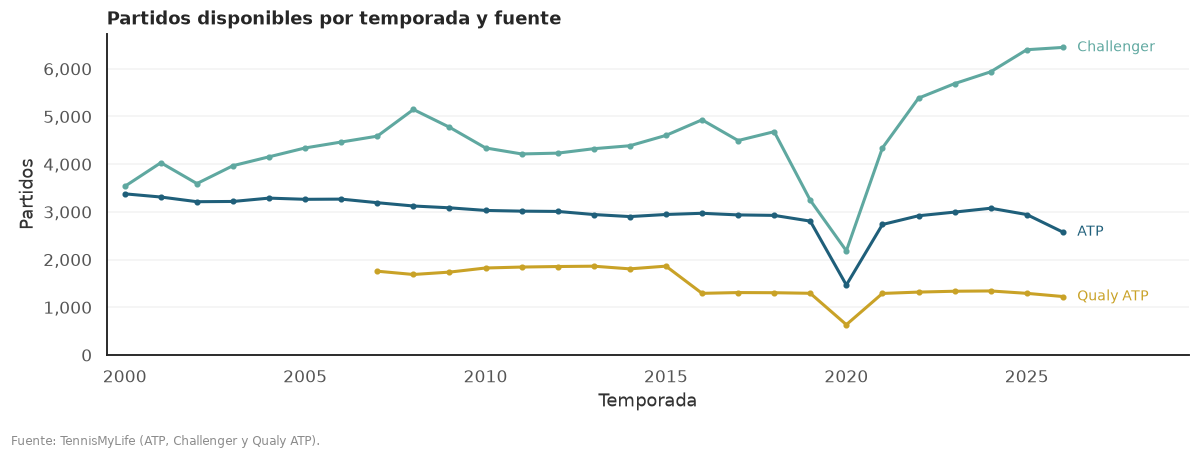

Nota: la temporada 2026 está en curso, por eso tiene menos partidos.


anio,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
fuente,,,,,,,,,,,,,,,,,,,,,,,,,,,
ATP,3378,3311,3213,3218,3288,3263,3267,3192,3123,3085,3030,3015,3009,2944,2901,2945,2970,2936,2926,2806,1466,2735,2918,2995,3076,2944,2576
Challenger,3534,4030,3593,3968,4154,4340,4464,4587,5146,4774,4340,4214,4231,4324,4386,4603,4929,4495,4681,3243,2183,4340,5384,5688,5936,6399,6447
Qualy ATP,0,0,0,0,0,0,0,1756,1687,1737,1823,1843,1854,1861,1805,1862,1292,1308,1305,1293,635,1290,1318,1336,1342,1292,1225


In [4]:

# 1.2 Inventario: qué temporadas están disponibles en cada fuente

tabla_inv = inventario.pivot(index='anio', columns='fuente', values='partidos')[list(FUENTES)]
no_disp = inventario[inventario.partidos == 0]
if len(no_disp):
    print('Archivos no disponibles:')
    display(no_disp.groupby(['fuente', 'estado']).anio.agg(lambda s: f'{s.min()}–{s.max()} ({len(s)} temporadas)'))

fig, ax = plt.subplots(figsize=(11, 4))
for fuente, color in zip(FUENTES, PALETA_CIRCUITO.values()):
    serie = tabla_inv[fuente].replace(0, np.nan).dropna()
    if len(serie):
        ax.plot(serie.index, serie.values, marker='o', ms=3, color=color, lw=2)
        ax.text(serie.index[-1] + 0.4, serie.iloc[-1], fuente, color=color, va='center', fontsize=9)
ax.set_title('Partidos disponibles por temporada y fuente')
ax.set_xlabel('Temporada'); ax.set_ylabel('Partidos')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
ax.set_xlim(ANIO_INICIO - 0.5, ANIO_FIN + 3.5); ax.set_ylim(0, None)
cerrar('01_inventario_fuentes')
print(f'Nota: la temporada {ANIO_FIN} está en curso, por eso tiene menos partidos.')
display(tabla_inv.T)

In [5]:

# 1.3 Homogeneización de columnas y tipos

ESPERADAS = ['tourney_id', 'tourney_name', 'surface', 'draw_size', 'tourney_level', 'indoor', 'tourney_date', 'match_num',
             'winner_id', 'winner_seed', 'winner_entry', 'winner_name', 'winner_hand', 'winner_ht', 'winner_ioc', 'winner_age',
             'winner_rank', 'winner_rank_points', 'loser_id', 'loser_seed', 'loser_entry', 'loser_name', 'loser_hand',
             'loser_ht', 'loser_ioc', 'loser_age', 'loser_rank', 'loser_rank_points', 'score', 'best_of', 'round', 'minutes'] \
            + [f'{s}_{v}' for s in ('w', 'l') for v in STATS]
faltan_cols = [c for c in ESPERADAS if c not in raw.columns]
extra_cols = [c for c in raw.columns if c not in ESPERADAS + ['fuente', 'anio_archivo']]
print('Columnas esperadas ausentes:', faltan_cols or 'ninguna')
print('Columnas adicionales:', extra_cols or 'ninguna')
for c in faltan_cols:
    raw[c] = np.nan

NUMERICAS = ['draw_size', 'match_num', 'best_of', 'minutes'] \
    + [f'{p}_{v}' for p in ('winner', 'loser') for v in ('seed', 'ht', 'age', 'rank', 'rank_points')] \
    + [f'{s}_{v}' for s in ('w', 'l') for v in STATS]
for c in NUMERICAS:
    raw[c] = pd.to_numeric(raw[c], errors='coerce')
for c in ['tourney_id', 'winner_id', 'loser_id', 'tourney_level', 'round', 'surface']:
    raw[c] = raw[c].astype('string').str.strip()
fecha_txt = raw['tourney_date'].astype('string').str.replace(r'\.0$', '', regex=True).str[:8]
raw['tourney_date'] = pd.to_datetime(fecha_txt, format='%Y%m%d', errors='coerce')
print(f'Fechas no interpretables: {raw.tourney_date.isna().sum():,}')

Columnas esperadas ausentes: ninguna
Columnas adicionales: ninguna


Fechas no interpretables: 0


### 1.2 Estructura general

Cada registro es un partido, con ganador y perdedor en columnas separadas (`winner_*`, `loser_*`, `w_*`, `l_*`). Modelado así, el resultado quedaría codificado en el nombre de las columnas. Por eso en la sección 5 se reorganiza en formato **jugador-partido** y en la sección 8 en formato **jugador A vs. jugador B**, con A asignado al azar.

In [6]:
jugadores_unicos = pd.unique(pd.concat([raw.winner_id, raw.loser_id]).dropna())
print(f'Período: {raw.tourney_date.min():%d/%m/%Y} a {raw.tourney_date.max():%d/%m/%Y}')
print(f'Partidos: {len(raw):,} | Torneos (id): {raw.tourney_id.nunique():,} | Jugadores distintos: {len(jugadores_unicos):,}')
display(raw.head(3))
print('\nNivel de torneo (tourney_level) según fuente:')
display(pd.crosstab(raw.tourney_level.fillna('(vacío)'), raw.fuente, margins=True, margins_name='Total'))
print('\nRondas según fuente:')
display(pd.crosstab(raw['round'].fillna('(vacío)'), raw.fuente))

Período: 03/01/2000 a 19/10/2026
Partidos: 232,807 | Torneos (id): 7,778 | Jugadores distintos: 6,551


,tourney_id,tourney_name,surface,draw_size,tourney_level,indoor,tourney_date,match_num,winner_id,winner_seed,winner_entry,winner_name,winner_hand,winner_ht,winner_ioc,winner_age,winner_rank,winner_rank_points,loser_id,loser_seed,loser_entry,loser_name,loser_hand,loser_ht,loser_ioc,loser_age,loser_rank,loser_rank_points,score,best_of,round,minutes,w_ace,w_df,w_svpt,w_1stIn,w_1stWon,w_2ndWon,w_SvGms,w_bpSaved,w_bpFaced,l_ace,l_df,l_svpt,l_1stIn,l_1stWon,l_2ndWon,l_SvGms,l_bpSaved,l_bpFaced,fuente,anio_archivo
0,2000-7308,Adelaide,Hard,32.0,250,O,2000-01-03,1.0,E113,1.0,NaN,Thomas Enqvist,R,191.0,SWE,25.810,4.0,2606.0,C487,NaN,NaN,Arnaud Clement,R,173.0,FRA,22.045,56.0,805.0,6-3 6-4,3,R32,76.0,6.0,0.0,66.0,29.0,23.0,23.0,10.0,2.0,2.0,1.0,3.0,59.0,37.0,25.0,13.0,9.0,2.0,4.0,ATP,2000
1,2000-7308,Adelaide,Hard,32.0,250,O,2000-01-03,2.0,F324,NaN,NaN,Roger Federer,R,185.0,SUI,18.404,64.0,749.0,K260,NaN,NaN,Jens Knippschild,R,191.0,GER,24.882,91.0,525.0,6-1 6-4,3,R32,45.0,6.0,3.0,46.0,28.0,24.0,12.0,9.0,0.0,0.0,3.0,5.0,42.0,15.0,13.0,12.0,8.0,0.0,3.0,ATP,2000
2,2000-7308,Adelaide,Hard,32.0,250,O,2000-01-03,3.0,G352,NaN,NaN,Jan-Michael Gambill,R,191.0,USA,22.585,58.0,803.0,A202,NaN,NaN,Wayne Arthurs,L,185.0,AUS,28.797,105.0,449.0,3-6 7-6(5) 6-4,3,R32,115.0,8.0,3.0,81.0,40.0,35.0,28.0,15.0,0.0,1.0,26.0,2.0,103.0,59.0,49.0,22.0,16.0,4.0,5.0,ATP,2000



Nivel de torneo (tourney_level) según fuente:


fuente,ATP,Challenger,Qualy ATP,Total
tourney_level,,,,
(vacío),0,0,374,374
250,31474,0,13439,44913
500,10697,0,3055,13752
A,877,0,24,901
C,0,122413,0,122413
D,7514,0,0,7514
F,390,0,0,390
G,13589,0,8624,22213
M,15541,0,4348,19889



Rondas según fuente:


fuente,ATP,Challenger,Qualy ATP
round,,,
(vacío),1,0,0
3rd/4th,2,0,0
BR,7,0,0
F,1776,3900,0
Q1,0,0,17921
Q2,0,0,9321
Q3,0,0,2620
QF,6836,15586,0
R128,8968,0,2


### 1.3 Tipo de resultado, duplicados y base analítica

Filtros aplicados:

- **Duplicados:** un mismo partido puede figurar en dos archivos.
- **Copa Davis:** se excluye; su formato por equipos no depende de una decisión de calendario individual.
- **Walkovers:** se excluyen porque el partido no se disputó.
- **Retiros:** se conservan con un indicador, porque el partido empezó y el resultado cuenta para el ranking.

In [7]:
sc = raw['score'].astype('string').fillna('').str.upper().str.strip()
raw['resultado_tipo'] = np.select(
    [c.to_numpy(dtype=bool) for c in (
        sc.eq(''),
        sc.str.contains(r'W/O|WALKOVER|\bWO\b', regex=True),
        sc.str.contains(r'RET|ABN|ABD|UNF', regex=True),
        sc.str.contains(r'DEF|\bDQ\b', regex=True))],
    ['Sin score', 'Walkover', 'Retiro', 'Descalificación'], default='Completo')
display(pd.crosstab(raw.resultado_tipo, raw.fuente, margins=True, margins_name='Total'))

CLAVE = ['tourney_id', 'tourney_date', 'round', 'winner_id', 'loser_id']
es_dup = raw.duplicated(CLAVE, keep='first')
print(f'Duplicados por clave de partido: {es_dup.sum():,}')
if es_dup.any():
    display(raw.loc[es_dup, 'fuente'].value_counts().rename('duplicados'))

pasos = [('Registros descargados', len(raw))]
df = raw[~es_dup].copy();                                          pasos.append(('Sin duplicados', len(df)))
df = df[df.tourney_date.dt.year.between(ANIO_INICIO, ANIO_FIN)];   pasos.append((f'Fecha válida {ANIO_INICIO}–{ANIO_FIN}', len(df)))
df = df[df.tourney_level.fillna('') != 'D'];                       pasos.append(('Sin Copa Davis (formato por equipos)', len(df)))
df = df[df.resultado_tipo != 'Walkover'];                          pasos.append(('Sin walkovers (partido no disputado)', len(df)))
df = df[df.winner_id.notna() & df.loser_id.notna() & df.surface.notna()]
pasos.append(('Con jugadores y superficie identificados', len(df)))
df = df.reset_index(drop=True)

embudo = pd.DataFrame(pasos, columns=['paso', 'partidos'])
embudo['% del total'] = (embudo.partidos / embudo.partidos.iloc[0]).map('{:.1%}'.format)
display(embudo)

fuente,ATP,Challenger,Qualy ATP,Total
resultado_tipo,,,,
Completo,77667,117604,28984,224255
Descalificación,18,0,0,18
Retiro,2416,4314,789,7519
Sin score,2,0,0,2
Walkover,427,495,91,1013
Total,80530,122413,29864,232807


Duplicados por clave de partido: 36


fuente
Qualy ATP    25
ATP          11
Name: duplicados, dtype: int64

,paso,partidos,% del total
0,Registros descargados,232807,100.0%
1,Sin duplicados,232771,100.0%
2,Fecha válida 2000–2026,232771,100.0%
3,Sin Copa Davis (formato por equipos),225263,96.8%
4,Sin walkovers (partido no disputado),224275,96.3%
5,Con jugadores y superficie identificados,223190,95.9%


In [8]:
# Variables de contexto derivadas
df['anio'] = df.tourney_date.dt.year
df['es_qualy'] = (df.fuente.eq('Qualy ATP') | df['round'].fillna('').str.upper().str.match(r'^Q\d')).astype(bool)
df['circuito'] = np.where(df.fuente.eq('Challenger'), 'Challenger',
                          np.where(df.es_qualy, 'Qualy ATP', 'ATP cuadro principal'))
# TennisMyLife codifica ATP 250 y ATP 500 como '250' y '500' (no como 'A', como el repositorio de Sackmann)
MAPA_NIVEL = {'G': 'Grand Slam', 'M': 'Masters 1000', '1000': 'Masters 1000', '500': 'ATP 500', '250': 'ATP 250',
              'A': 'Otros ATP (nivel A)', 'F': 'ATP Finals', 'O': 'Juegos Olímpicos', 'C': 'Challenger', 'CH': 'Challenger'}
df['categoria'] = np.where(df.fuente.eq('Challenger'), 'Challenger',
                           df.tourney_level.map(MAPA_NIVEL).fillna('Otro').astype(str))
print('Codificación de niveles de torneo (fuera de Challenger), con torneos de ejemplo:')
display(df[df.fuente != 'Challenger'].groupby('tourney_level').agg(
    partidos=('tourney_name', 'size'), categoria=('categoria', 'first'),
    ejemplos=('tourney_name', lambda s: ', '.join(s.value_counts().index[:4].astype(str)))))
df['surface'] = df.surface.str.title()
df['surface_elo'] = df.surface.replace({'Carpet': 'Hard'})   # la carpeta es superficie rápida bajo techo
MAPA_INDOOR = {'I': 'Indoor', 'INDOOR': 'Indoor', 'YES': 'Indoor', 'Y': 'Indoor', 'TRUE': 'Indoor', '1': 'Indoor', '1.0': 'Indoor',
               'O': 'Outdoor', 'OUTDOOR': 'Outdoor', 'NO': 'Outdoor', 'N': 'Outdoor', 'FALSE': 'Outdoor', '0': 'Outdoor', '0.0': 'Outdoor'}
df['indoor'] = df['indoor'].astype('string').str.strip().str.upper().map(MAPA_INDOOR)
circ_presentes = [c for c in CIRCUITOS if (df.circuito == c).any()]
PCT_QUALY_CH = df.loc[df.fuente.eq('Challenger'), 'es_qualy'].mean()
print(f'Partidos de qualy dentro de los archivos Challenger: {PCT_QUALY_CH:.1%}'
      + ('  → las clasificaciones de Challenger NO están en la base (limitación de la fuente)' if PCT_QUALY_CH < 0.01 else ''))
print(f"Primera temporada con qualys ATP: {df.loc[df.fuente.eq('Qualy ATP'), 'anio'].min()}")

print('Categoría de torneo según circuito:')
display(pd.crosstab(df.categoria, df.circuito))
print('Superficie según circuito:')
display(pd.crosstab(df.surface, df.circuito, normalize='columns').style.format('{:.1%}'))

Codificación de niveles de torneo (fuera de Challenger), con torneos de ejemplo:


,partidos,categoria,ejemplos
tourney_level,,,
250,44658,ATP 250,"Delray Beach, Buenos Aires, Marseille, Bastad"
500,13674,ATP 500,"Barcelona, Tokyo, Washington, Rotterdam"
A,900,Otros ATP (nivel A),"World Team Championship, ATP Cup, United Cup, ..."
F,389,ATP Finals,"Tour Finals, Masters Cup, ATP Finals, Tennis M..."
G,22157,Grand Slam,"Australian Open, Roland Garros, US Open, Wimbl..."
M,19762,Masters 1000,"Miami Masters, Indian Wells Masters, Rome Mast..."
O,445,Juegos Olímpicos,"Sydney Olympics, Beijing Olympics, London Olym..."


Partidos de qualy dentro de los archivos Challenger: 0.0%  → las clasificaciones de Challenger NO están en la base (limitación de la fuente)
Primera temporada con qualys ATP: 2007
Categoría de torneo según circuito:


circuito,ATP cuadro principal,Challenger,Qualy ATP
categoria,,,
ATP 250,31298,0,13360
ATP 500,10628,0,3046
ATP Finals,389,0,0
Challenger,0,121205,0
Grand Slam,13543,0,8614
Juegos Olímpicos,445,0,0
Masters 1000,15430,0,4332
Otros ATP (nivel A),876,0,24


Superficie según circuito:


circuito,ATP cuadro principal,Challenger,Qualy ATP
surface,,,
Carpet,2.0%,3.1%,0.2%
Clay,31.9%,49.3%,32.1%
Grass,11.1%,1.9%,13.2%
Hard,55.0%,45.7%,54.6%


## 2. Descripción de variables

| Familia | Variables | Contenido | Momento |
|---|---|---|---|
| Torneo | `tourney_id`, `tourney_name`, `surface`, `draw_size`, `tourney_level`, `indoor`, `tourney_date` | Identificación, superficie, tamaño del cuadro, categoría, techo y semana | Pre-partido |
| Partido | `match_num`, `round`, `best_of` | Orden, ronda y formato (3 o 5 sets) | Pre-partido |
| Resultado | `score`, `minutes` | Resultado y duración | **Post-partido** |
| Jugador (×2) | `id`, `name`, `seed`, `entry`, `hand`, `ht`, `ioc`, `age`, `rank`, `rank_points` | Identidad, cabeza de serie, forma de ingreso, mano, altura, país, edad, ranking y puntos al momento del torneo | Pre-partido |
| Estadísticas (×2) | `ace`, `df`, `svpt`, `1stIn`, `1stWon`, `2ndWon`, `SvGms`, `bpSaved`, `bpFaced` | Rendimiento con el saque en ese partido | **Post-partido** |

Solo las variables pre-partido pueden usarse como predictores. Las estadísticas describen el propio partido, así que en la notebook 02 se transforman en promedios históricos calculados con partidos anteriores. El diccionario completo está en la sección 11.

In [9]:
def resumen_columnas(d, cols):
    return pd.DataFrame({
        'tipo': d[cols].dtypes.astype(str),
        'n_únicos': d[cols].nunique(),
        '% faltantes': (d[cols].isna().mean() * 100).round(2),
        'ejemplo': [d[c].dropna().iloc[0] if d[c].notna().any() else None for c in cols],
    })
display(resumen_columnas(df, ESPERADAS))

,tipo,n_únicos,% faltantes,ejemplo
tourney_id,string,5655,0.00,2000-7308
tourney_name,object,846,0.00,Adelaide
surface,string,4,0.00,Hard
draw_size,float64,20,0.00,32.0
tourney_level,string,8,0.00,250
indoor,object,2,48.58,Outdoor
tourney_date,datetime64[ns],2284,0.00,2000-01-03 00:00:00
match_num,float64,127,0.22,1.0
winner_id,string,3257,0.00,E113
winner_seed,float64,34,62.29,1.0


## 3. Valores faltantes

Para cada variable se mide cuánto falta, dónde y con qué patrón. Con esa evidencia se clasifica el mecanismo (MCAR, MAR, MNAR o faltante estructural) y se decide el tratamiento.

### 3.1 Faltantes encubiertos

Primero se convierten a faltante los valores que en realidad lo son: mano hábil distinta de R/L, altura, edad o ranking ≤ 0 y duraciones nulas.

In [10]:
encubiertos = {}
for p in ('winner', 'loser'):
    h = df[f'{p}_hand'].astype('string').str.upper().str.strip()
    encubiertos[f'{p}_hand distinto de R/L (U, A u otro)'] = int((h.notna() & ~h.isin(['R', 'L'])).sum())
    df[f'{p}_hand'] = h.where(h.isin(['R', 'L']))
    for v, cond in [('ht', lambda s: s <= 0), ('age', lambda s: s <= 0), ('rank', lambda s: s <= 0), ('rank_points', lambda s: s < 0)]:
        m = cond(df[f'{p}_{v}'])
        encubiertos[f'{p}_{v} con valor imposible'] = int(m.sum())
        df.loc[m, f'{p}_{v}'] = np.nan
    e = df[f'{p}_entry'].astype('string').str.strip().str.upper()
    df[f'{p}_entry'] = e.where(~e.isin(['', 'NAN', 'NONE']))
m = df.minutes <= 0
encubiertos['minutes ≤ 0'] = int(m.sum())
df.loc[m, 'minutes'] = np.nan
display(pd.Series(encubiertos, name='casos convertidos a faltante').to_frame())

,casos convertidos a faltante
"winner_hand distinto de R/L (U, A u otro)",5
winner_ht con valor imposible,112
winner_age con valor imposible,0
winner_rank con valor imposible,0
winner_rank_points con valor imposible,0
"loser_hand distinto de R/L (U, A u otro)",27
loser_ht con valor imposible,354
loser_age con valor imposible,0
loser_rank con valor imposible,0
loser_rank_points con valor imposible,0


### 3.2 Magnitud de los faltantes por variable

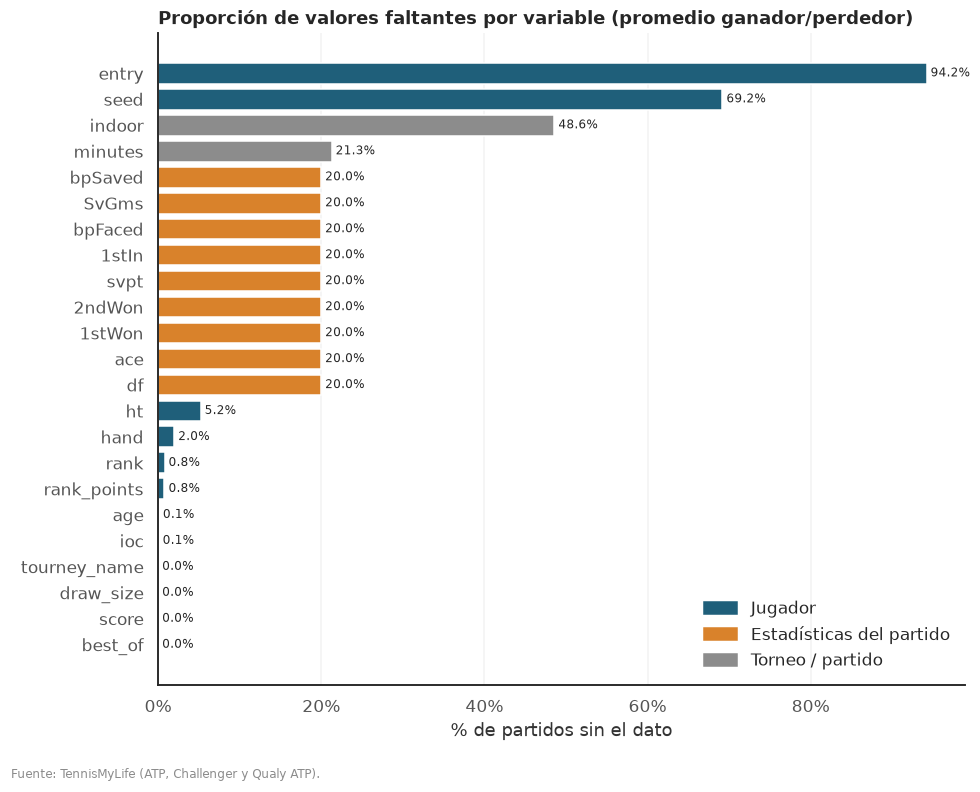

Nota: seed y entry son faltantes estructurales (sin seed = no es cabeza de serie; sin entry = ingreso directo).


In [11]:
filas = []
for v in ['seed', 'entry', 'hand', 'ht', 'ioc', 'age', 'rank', 'rank_points']:
    filas.append(('Jugador', v, df[[f'winner_{v}', f'loser_{v}']].isna().mean().mean()))
for v in STATS:
    filas.append(('Estadísticas del partido', v, df[[f'w_{v}', f'l_{v}']].isna().mean().mean()))
for v in ['tourney_name', 'draw_size', 'indoor', 'best_of', 'score', 'minutes']:
    filas.append(('Torneo / partido', v, df[v].isna().mean()))
faltantes = pd.DataFrame(filas, columns=['familia', 'variable', 'pct']).sort_values('pct')

COL_FAM = {'Jugador': C_PRINCIPAL, 'Estadísticas del partido': C_FOCO, 'Torneo / partido': C_GRIS}
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(faltantes.variable, faltantes.pct, color=faltantes.familia.map(COL_FAM))
for y, v in enumerate(faltantes.pct):
    ax.text(v + 0.005, y, f'{v:.1%}', va='center', fontsize=8)
pct_axis(ax, 'x'); ax.grid(False, axis='y'); ax.grid(True, axis='x', alpha=.25)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COL_FAM.values()], COL_FAM.keys(), loc='lower right')
ax.set_title('Proporción de valores faltantes por variable (promedio ganador/perdedor)')
ax.set_xlabel('% de partidos sin el dato')
cerrar('02_faltantes_por_variable')
print('Nota: seed y entry son faltantes estructurales (sin seed = no es cabeza de serie; sin entry = ingreso directo).')

### 3.3 Patrón temporal

Proporción de faltantes por temporada y circuito, para ver si la ausencia depende de cómo se registró la información en cada época.

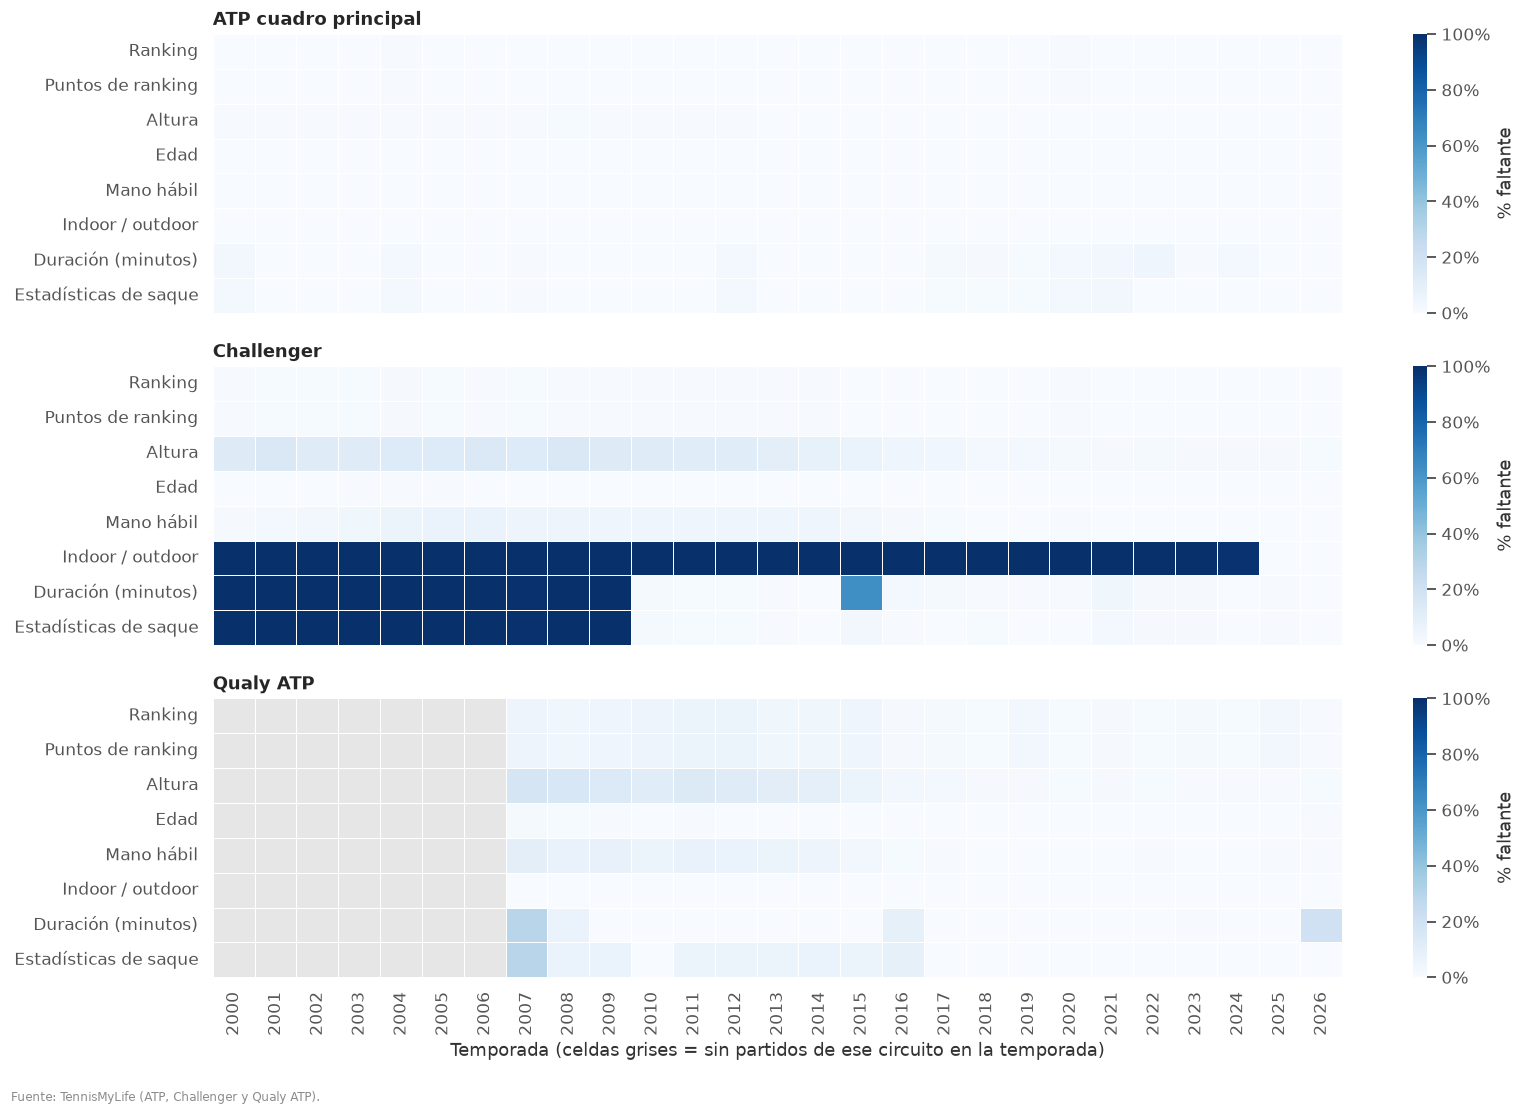

Primer año desde el cual ≥80% de los partidos tiene estadísticas de saque (y se mantiene):
  ATP cuadro principal   2000
  Challenger             2010
  Qualy ATP              2008


In [12]:
VARS_HM = {'Ranking': ['winner_rank', 'loser_rank'], 'Puntos de ranking': ['winner_rank_points', 'loser_rank_points'],
           'Altura': ['winner_ht', 'loser_ht'], 'Edad': ['winner_age', 'loser_age'], 'Mano hábil': ['winner_hand', 'loser_hand'],
           'Indoor / outdoor': ['indoor'], 'Duración (minutos)': ['minutes'], 'Estadísticas de saque': ['w_svpt', 'l_svpt']}
anios = list(range(ANIO_INICIO, ANIO_FIN + 1))
fig, axes = plt.subplots(len(circ_presentes), 1, figsize=(15, 3.3 * len(circ_presentes)), sharex=True, squeeze=False)
for ax, circ in zip(axes[:, 0], circ_presentes):
    sub = df[df.circuito == circ]
    mat = pd.DataFrame({k: sub[v].isna().mean(axis=1).groupby(sub.anio).mean() for k, v in VARS_HM.items()}).T.reindex(columns=anios)
    sns.heatmap(mat.astype(float), ax=ax, cmap='Blues', vmin=0, vmax=1, linewidths=.4, linecolor='white',
                cbar_kws={'format': mtick.PercentFormatter(1.0), 'label': '% faltante'})
    ax.set_facecolor('#e6e6e6')
    ax.set_title(circ); ax.set_xlabel(''); ax.set_ylabel(''); ax.grid(False)
axes[-1, 0].set_xlabel('Temporada (celdas grises = sin partidos de ese circuito en la temporada)')
cerrar('03_faltantes_por_temporada')

def anio_cobertura(serie, umbral=0.8):
    """Primer año desde el cual la cobertura supera el umbral y se mantiene."""
    s = serie.dropna()
    for a in s.index:
        if (s.loc[a:] >= umbral).all():
            return int(a)
    return None

cobertura = df.assign(con_stats=df.w_svpt.notna()).groupby(['anio', 'circuito']).con_stats.mean().unstack()
COBERTURA_DESDE = {c: anio_cobertura(cobertura[c]) for c in cobertura.columns}
print('Primer año desde el cual ≥80% de los partidos tiene estadísticas de saque (y se mantiene):')
for c, a in COBERTURA_DESDE.items():
    print(f'  {c:<22} {a if a else "no alcanza el 80%"}')

### 3.4 Altura: hipótesis MAR

Hipótesis: la altura falta más en jugadores de ranking bajo, cuya información biográfica está menos documentada. Si se confirma, eliminar esos registros sesgaría la muestra justamente contra la población objetivo.

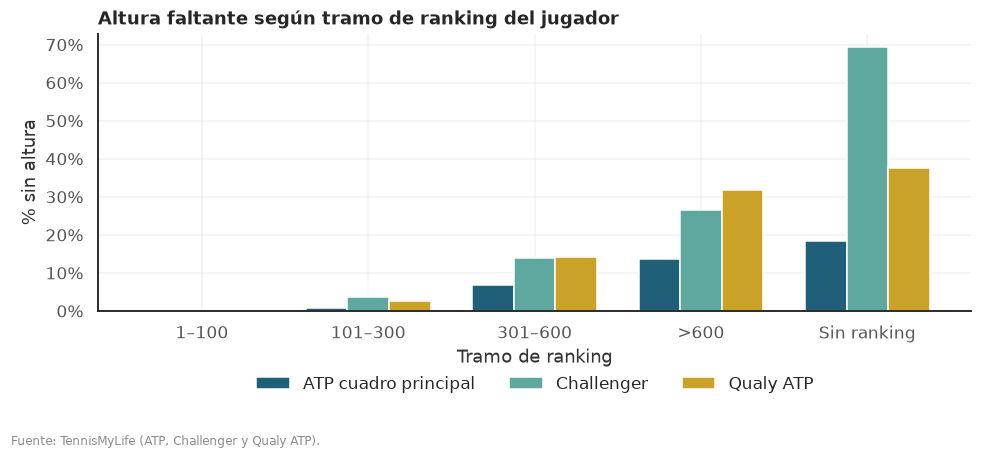

Chi-cuadrado de independencia (altura faltante vs. tramo de ranking): chi2 = 52,006; gl = 4; p-valor = 0.00e+00
p < 0.05 → se rechaza la independencia: el faltante no es MCAR.


In [13]:
tmp = apilar(df, ['id', 'rank', 'ht', 'hand', 'age', 'entry'])
tmp['tramo'] = pd.cut(tmp['rank'], TRAMOS, labels=ETIQ_TRAMOS).cat.add_categories('Sin ranking').fillna('Sin ranking')
ht_falta = tmp.groupby(['tramo', 'circuito'], observed=False).ht.apply(lambda s: s.isna().mean()).unstack().reindex(columns=circ_presentes)

ax = ht_falta.plot(kind='bar', figsize=(9, 4), color=[PALETA_CIRCUITO[c] for c in circ_presentes], width=.75, rot=0)
pct_axis(ax); ax.set_title('Altura faltante según tramo de ranking del jugador')
ax.set_xlabel('Tramo de ranking'); ax.set_ylabel('% sin altura')
ax.legend(title='', ncol=3, loc='upper center', bbox_to_anchor=(.5, -.18))
cerrar('04_altura_faltante_por_ranking')

chi2, p_val, gl, _ = stats.chi2_contingency(pd.crosstab(tmp.tramo, tmp.ht.isna()))
print(f'Chi-cuadrado de independencia (altura faltante vs. tramo de ranking): chi2 = {chi2:,.0f}; gl = {gl}; p-valor = {p_val:.2e}')
print('p < 0.05 → se rechaza la independencia: el faltante no es MCAR.' if p_val < 0.05 else 'No se rechaza la independencia.')

### 3.5 Ranking: hipótesis MNAR

Hipótesis: el ranking falta porque el jugador no tiene ranking o lo tiene muy bajo. Se contrasta con el ranking que esos mismos jugadores tienen en otros torneos de la temporada y con la tasa de faltantes por circuito. También se verifica si la forma de ingreso (`entry`) se registra de forma pareja en todos los circuitos.

In [14]:
sin_rank = tmp[tmp['rank'].isna()]
print(f'Registros jugador-partido sin ranking: {len(sin_rank):,} ({len(sin_rank) / len(tmp):.1%})')

comp = pd.DataFrame({
    'Sin ranking': sin_rank.entry.fillna('Directa').value_counts(normalize=True),
    'Con ranking': tmp[tmp['rank'].notna()].entry.fillna('Directa').value_counts(normalize=True),
}).fillna(0).sort_values('Sin ranking', ascending=False).head(8)
print('\nForma de ingreso al torneo (vacío = directa o no registrado):')
display(comp.style.format('{:.1%}'))

print('Proporción sin ranking por circuito:')
display(pd.crosstab(tmp.circuito, tmp['rank'].isna(), normalize='index')
          .rename(columns={False: 'Con ranking', True: 'Sin ranking'}).style.format('{:.1%}'))

mediana_anual = tmp.dropna(subset=['rank']).groupby(['id', 'anio'])['rank'].median().rename('rank_mismo_anio')
ref = sin_rank.join(mediana_anual, on=['id', 'anio'])
RANK_REF_PCT = ref.rank_mismo_anio.notna().mean()
RANK_REF_MED, RANK_MED_GRAL = ref.rank_mismo_anio.median(), tmp['rank'].median()
print(f'Casos sin ranking que sí lo tienen en otro torneo del mismo año: {RANK_REF_PCT:.1%}')
print(f'Mediana de ese ranking: {RANK_REF_MED:,.0f} (mediana general: {RANK_MED_GRAL:,.0f})')
print(f'El {1 - RANK_REF_PCT:.1%} restante no registra ranking en toda la temporada (jugadores sin ranking).')

# Diagnóstico: ¿la forma de ingreso se registra igual en todos los circuitos?
ENTRY_INFORMADO = tmp.groupby('circuito').entry.apply(lambda s: s.notna().mean()).reindex(circ_presentes)
CIRC_CON_ENTRY = ENTRY_INFORMADO[ENTRY_INFORMADO >= 0.05].index.tolist()
print('\n% de jugador-partido con forma de ingreso informada, por circuito:')
display(ENTRY_INFORMADO.to_frame('% informado').style.format('{:.1%}'))
print('Circuitos donde el campo entry es utilizable (≥5% informado):', CIRC_CON_ENTRY or 'ninguno')

Registros jugador-partido sin ranking: 3,493 (0.8%)

Forma de ingreso al torneo (vacío = directa o no registrado):


,Sin ranking,Con ranking
entry,,
Directa,95.2%,94.2%
WC,3.5%,1.9%
Q,0.7%,3.2%
PR,0.3%,0.1%
LL,0.2%,0.5%
ALT,0.1%,0.0%
CO,0.0%,0.0%
A,0.0%,0.0%


Proporción sin ranking por circuito:


rank,Con ranking,Sin ranking
circuito,,
ATP cuadro principal,99.8%,0.2%
Challenger,99.5%,0.5%
Qualy ATP,96.6%,3.4%


Casos sin ranking que sí lo tienen en otro torneo del mismo año: 23.1%
Mediana de ese ranking: 484 (mediana general: 161)
El 76.9% restante no registra ranking en toda la temporada (jugadores sin ranking).



% de jugador-partido con forma de ingreso informada, por circuito:


,% informado
circuito,
ATP cuadro principal,17.7%
Challenger,0.0%
Qualy ATP,0.2%


Circuitos donde el campo entry es utilizable (≥5% informado): ['ATP cuadro principal']


### 3.6 Tratamiento: propagación intra-jugador

Altura, mano hábil y fecha de nacimiento son atributos fijos del jugador. Si faltan en un partido pero figuran en otro del mismo jugador, se completan con ese dato, sin estimar nada.

In [15]:
def moda_por_jugador(t, v):
    x = t.dropna(subset=[v]).groupby(['id', v]).size().reset_index(name='n')
    return x.sort_values('n').drop_duplicates('id', keep='last').set_index('id')[v]

antes = {v: df[[f'winner_{v}', f'loser_{v}']].isna().mean().mean() for v in ['hand', 'ht', 'age']}
tmp = apilar(df, ['id', 'hand', 'ht'])
for v in ['hand', 'ht']:
    referencia = moda_por_jugador(tmp, v)
    for p in ('winner', 'loser'):
        df[f'{p}_{v}'] = df[f'{p}_{v}'].fillna(df[f'{p}_id'].map(referencia))

# Edad: se estima la fecha de nacimiento de cada jugador y se recalcula la edad faltante
nacimiento = pd.concat([
    pd.DataFrame({'id': df[f'{p}_id'],
                  'nac': df.tourney_date - pd.to_timedelta(df[f'{p}_age'] * 365.25, unit='D')})
    for p in ('winner', 'loser')]).dropna().groupby('id').nac.median()
for p in ('winner', 'loser'):
    edad_est = (df.tourney_date - df[f'{p}_id'].map(nacimiento)).dt.days / 365.25
    df[f'{p}_age'] = df[f'{p}_age'].fillna(edad_est)

despues = {v: df[[f'winner_{v}', f'loser_{v}']].isna().mean().mean() for v in ['hand', 'ht', 'age']}
display(pd.DataFrame({'% faltante antes': antes, '% faltante después': despues}).style.format('{:.2%}'))

,% faltante antes,% faltante después
hand,1.97%,1.88%
ht,5.21%,4.97%
age,0.09%,0.07%


### 3.7 Decisiones sobre valores faltantes

In [16]:
decisiones_faltantes = pd.DataFrame([
    ['seed', 'Estructural', 'Solo los cabezas de serie tienen seed', 'Indicador es_cabeza_serie; el faltante significa "sin seed"'],
    ['entry', 'Estructural + subregistro', f'Vacío = ingreso directo o no registrado; registro utilizable solo en: {", ".join(CIRC_CON_ENTRY) or "ninguno"}',
     'Imputar "Directa"; el análisis por forma de ingreso se limita a los circuitos con registro'],
    ['rank / rank_points', 'MNAR', f'Más frecuente en qualys; cuando el jugador tiene ranking en la misma temporada, su mediana es {RANK_REF_MED:,.0f} '
     f'(vs. {RANK_MED_GRAL:,.0f} general); el {1 - RANK_REF_PCT:.0%} no tiene ranking en todo el año',
     f'Valor centinela {RANK_CENTINELA} + indicador sin_ranking; puntos = 0'],
    ['ht', 'MAR', 'Depende del tramo de ranking y del circuito (test chi-cuadrado)',
     'Propagación intra-jugador; el remanente se imputa con la mediana + indicador en el modelado'],
    ['hand', 'MAR / encubierto', 'Desconocida en 31% de los jugadores, pero solo 2% de los partidos: falta en jugadores con pocos partidos',
     'Propagación intra-jugador; el remanente como categoría "Desconocida"'],
    ['age', 'MAR', 'Datos biográficos incompletos en jugadores poco documentados', 'Recalculada a partir de la fecha de nacimiento estimada'],
    ['Estadísticas w_* / l_*', 'MAR', 'Depende del circuito y la temporada (cobertura histórica)',
     'No se imputan. Son post-partido: se usarán como promedios históricos, solo en temporadas con cobertura'],
    ['Partidos de qualy ATP 2000–2006', 'Faltante a nivel fuente (MAR por temporada)', 'El archivo de qualys no existe antes de 2007',
     'Calentamiento extendido a 2000–2006: el Elo se calcula desde 2000, pero el entrenamiento arranca en 2007 con las tres fuentes completas'],
    ['minutes', 'MAR', 'Depende del circuito y la temporada', 'Solo descriptiva (post-partido); no se usa como predictor'],
    ['indoor', 'MAR (por circuito)', 'En Challenger prácticamente no se registra hasta las temporadas más recientes (mapa 3.3)',
     'Imputación por torneo desde las temporadas con registro + enriquecimiento externo; si la cobertura no alcanza, se descarta como predictor'],
], columns=['variable', 'mecanismo', 'evidencia', 'tratamiento'])
display(decisiones_faltantes.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

variable,mecanismo,evidencia,tratamiento
seed,Estructural,Solo los cabezas de serie tienen seed,"Indicador es_cabeza_serie; el faltante significa ""sin seed"""
entry,Estructural + subregistro,Vacío = ingreso directo o no registrado; registro utilizable solo en: ATP cuadro principal,"Imputar ""Directa""; el análisis por forma de ingreso se limita a los circuitos con registro"
rank / rank_points,MNAR,"Más frecuente en qualys; cuando el jugador tiene ranking en la misma temporada, su mediana es 484 (vs. 161 general); el 77% no tiene ranking en todo el año",Valor centinela 3000 + indicador sin_ranking; puntos = 0
ht,MAR,Depende del tramo de ranking y del circuito (test chi-cuadrado),Propagación intra-jugador; el remanente se imputa con la mediana + indicador en el modelado
hand,MAR / encubierto,"Desconocida en 31% de los jugadores, pero solo 2% de los partidos: falta en jugadores con pocos partidos","Propagación intra-jugador; el remanente como categoría ""Desconocida"""
age,MAR,Datos biográficos incompletos en jugadores poco documentados,Recalculada a partir de la fecha de nacimiento estimada
Estadísticas w_* / l_*,MAR,Depende del circuito y la temporada (cobertura histórica),"No se imputan. Son post-partido: se usarán como promedios históricos, solo en temporadas con cobertura"
Partidos de qualy ATP 2000–2006,Faltante a nivel fuente (MAR por temporada),El archivo de qualys no existe antes de 2007,"Calentamiento extendido a 2000–2006: el Elo se calcula desde 2000, pero el entrenamiento arranca en 2007 con las tres fuentes completas"
minutes,MAR,Depende del circuito y la temporada,Solo descriptiva (post-partido); no se usa como predictor
indoor,MAR (por circuito),En Challenger prácticamente no se registra hasta las temporadas más recientes (mapa 3.3),"Imputación por torneo desde las temporadas con registro + enriquecimiento externo; si la cobertura no alcanza, se descarta como predictor"


## 4. Outliers

Se separan dos casos: **errores de carga** (valores imposibles o implausibles), que se anulan, y **extremos reales** del deporte, que se conservan.

### 4.1 Integridad lógica de las estadísticas

Se verifican relaciones que siempre deben cumplirse (por ejemplo, no se pueden ganar más puntos con el primer saque que primeros saques adentro). Si un jugador viola alguna, se anula su bloque de estadísticas de ese partido; el resultado del partido se conserva.

In [17]:
def reglas_integridad(d, s):
    sv, f_in, f_w, s_w = d[f'{s}_svpt'], d[f'{s}_1stIn'], d[f'{s}_1stWon'], d[f'{s}_2ndWon']
    return {
        '1ros saques adentro > puntos de saque': f_in > sv,
        'Puntos ganados con 1er saque > 1ros saques adentro': f_w > f_in,
        'Puntos ganados con 2do saque > 2dos saques jugados': s_w > (sv - f_in),
        'Aces > puntos ganados con el saque': d[f'{s}_ace'] > (f_w + s_w),
        'Dobles faltas > 2dos saques jugados': d[f'{s}_df'] > (sv - f_in),
        'Break points salvados > enfrentados': d[f'{s}_bpSaved'] > d[f'{s}_bpFaced'],
        'Puntos de saque = 0 en partido completo': sv.eq(0) & d.resultado_tipo.eq('Completo'),
    }

con_stats = int((df.w_svpt.notna()).sum() + (df.l_svpt.notna()).sum())
violaciones, invalido = {}, {}
for s in ('w', 'l'):
    reglas = reglas_integridad(df, s)
    invalido[s] = pd.concat(reglas, axis=1).fillna(False).any(axis=1)
    for k, m in reglas.items():
        violaciones[k] = violaciones.get(k, 0) + int(m.fillna(False).sum())
tabla_integridad = pd.DataFrame({'violaciones': violaciones})
tabla_integridad['% de bloques con estadísticas'] = tabla_integridad.violaciones / max(con_stats, 1)
display(tabla_integridad.sort_values('violaciones', ascending=False).style.format({'% de bloques con estadísticas': '{:.3%}'}))

for s in ('w', 'l'):
    df.loc[invalido[s], [f'{s}_{v}' for v in STATS]] = np.nan
N_BLOQUES_INVALIDOS = int(sum(m.sum() for m in invalido.values()))
print(f'Bloques de estadísticas anulados por inconsistencia lógica: {N_BLOQUES_INVALIDOS:,}')

,violaciones,% de bloques con estadísticas
Break points salvados > enfrentados,16,0.004%
Puntos de saque = 0 en partido completo,13,0.004%
Puntos ganados con 2do saque > 2dos saques jugados,5,0.001%
Dobles faltas > 2dos saques jugados,4,0.001%
1ros saques adentro > puntos de saque,1,0.000%
Puntos ganados con 1er saque > 1ros saques adentro,0,0.000%
Aces > puntos ganados con el saque,0,0.000%


Bloques de estadísticas anulados por inconsistencia lógica: 36


### 4.2 Rangos de plausibilidad

Altura entre 155 y 215 cm y edad entre 14 y 45 años. La duración se valida según el formato. Al revisar los partidos más largos aparecieron partidos a 3 sets de más de 500 minutos (errores de carga), mientras que el más largo a 5 sets, Isner–Mahut en Wimbledon 2010 con 665 minutos, es real. Por eso se usan topes de 300 minutos a 3 sets y 720 minutos a 5 sets.

In [18]:
RANGOS = {'ht': (155, 215), 'age': (14, 45)}
filas = []
for v, (lo, hi) in RANGOS.items():
    for p in ('winner', 'loser'):
        s = df[f'{p}_{v}']
        m = (s < lo) | (s > hi)
        filas.append({'variable': f'{p}_{v}', 'rango válido': f'{lo}–{hi}', 'fuera de rango': int(m.sum()),
                      'ejemplos': list(np.round(s[m].unique()[:5], 1))})
        df.loc[m, f'{p}_{v}'] = np.nan
# La duración se valida según el formato: un partido al mejor de 3 sets de más de 5 horas es implausible
m = (df.minutes > 720) | (df.best_of.eq(3) & (df.minutes > 300)) | ((df.minutes < 25) & df.resultado_tipo.eq('Completo'))
filas.append({'variable': 'minutes', 'rango válido': '25–300 (mejor de 3) / 25–720 (mejor de 5)', 'fuera de rango': int(m.sum()),
              'ejemplos': list(df.minutes[m].unique()[:5])})
df.loc[m, 'minutes'] = np.nan
display(pd.DataFrame(filas))

,variable,rango válido,fuera de rango,ejemplos
0,winner_ht,155–215,0,[]
1,loser_ht,155–215,0,[]
2,winner_age,14–45,0,[]
3,loser_age,14–45,3,"[46.6, 45.8, 46.0]"
4,minutes,25–300 (mejor de 3) / 25–720 (mejor de 5),30,"[23.0, 24.0, 999.0, 536.0, 1237.0]"


### 4.3 Duración de los partidos

El IQR se calcula dentro de cada formato: sin segmentar, todos los partidos a 5 sets aparecerían como atípicos (outliers contextuales).

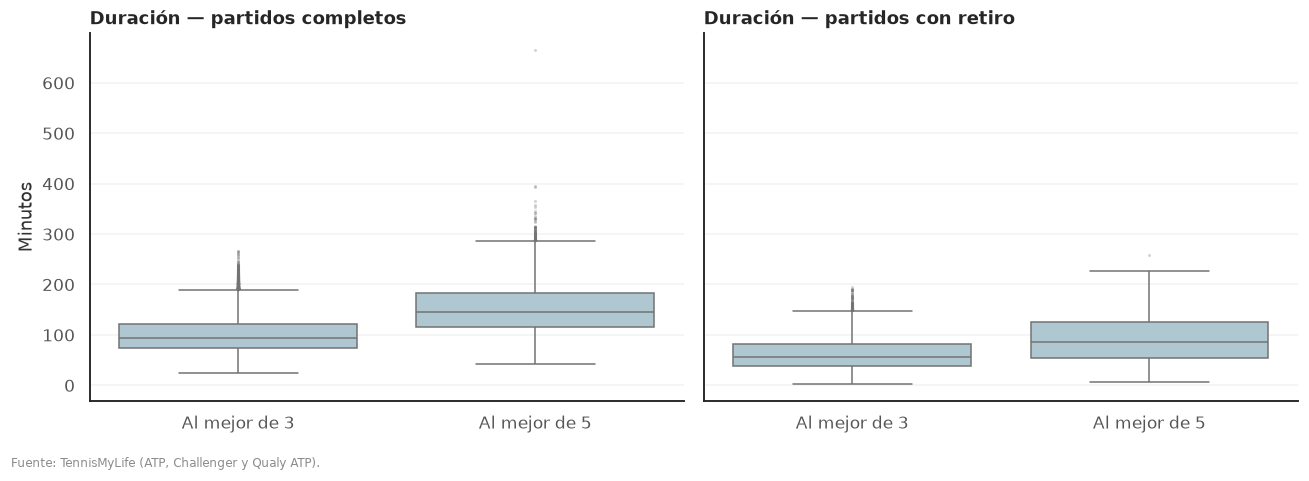

,formato,Q1,mediana,Q3,límite inferior,límite superior,outliers,% outliers
0,Al mejor de 3,75.0,94.0,121.0,6.0,190.0,974,0.62%
1,Al mejor de 5,115.0,145.0,184.0,11.5,287.5,89,0.67%


Partidos más largos tras la depuración:


,tourney_date,tourney_name,round,winner_name,loser_name,score,minutes
30512,2010-06-21,Wimbledon,R128,John Isner,Nicolas Mahut,6-4 3-6 6-7(7) 7-6(3) 70-68,665.0
51777,2018-07-02,Wimbledon,SF,Kevin Anderson,John Isner,7-6(6) 6-7(5) 6-7(9) 6-4 26-24,396.0
13092,2004-05-24,Roland Garros,R128,Fabrice Santoro,Arnaud Clement,6-4 6-3 6-7(5) 3-6 16-14,393.0
56355,2020-09-28,Roland Garros,R128,Lorenzo Giustino,Corentin Moutet,0-6 7-6(7) 7-6(3) 2-6 18-16,365.0
71524,2026-05-30,Roland Garros,R32,Juan Manuel Cerundolo,Martin Landaluce,6-4 6-7(7) 7-6(4) 6-7(4) 7-6(8),358.0


In [19]:
d_min = df[df.minutes.notna() & df.resultado_tipo.isin(['Completo', 'Retiro'])].copy()
d_min['formato'] = 'Al mejor de ' + d_min.best_of.astype('Int64').astype('string').fillna('?')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, tipo, titulo in zip(axes, ['Completo', 'Retiro'], ['Partidos completos', 'Partidos con retiro']):
    sub = d_min[d_min.resultado_tipo == tipo]
    orden = sorted(sub.formato.unique())
    if len(sub):
        sns.boxplot(data=sub, x='formato', y='minutes', order=orden, ax=ax, color=C_SECUNDARIO, linewidth=1,
                    flierprops={'marker': '.', 'markersize': 2, 'alpha': .3})
    ax.set_title(f'Duración — {titulo.lower()}'); ax.set_xlabel(''); ax.set_ylabel('Minutos')
cerrar('05_duracion_boxplot')

filas = []
for fmt, sub in d_min[d_min.resultado_tipo == 'Completo'].groupby('formato'):
    lo, hi = limites_iqr(sub.minutes)
    fuera = (sub.minutes < lo) | (sub.minutes > hi)
    filas.append({'formato': fmt, 'Q1': sub.minutes.quantile(.25), 'mediana': sub.minutes.median(),
                  'Q3': sub.minutes.quantile(.75), 'límite inferior': round(lo, 1), 'límite superior': round(hi, 1),
                  'outliers': int(fuera.sum()), '% outliers': f'{fuera.mean():.2%}'})
display(pd.DataFrame(filas))
print('Partidos más largos tras la depuración:')
display(df.nlargest(5, 'minutes')[['tourney_date', 'tourney_name', 'round', 'winner_name', 'loser_name', 'score', 'minutes']])

### 4.4 Porcentaje de aces

Variable muy asimétrica. Se comparan los criterios z-score e IQR y se revisa quiénes son los jugadores extremos para decidir si son errores o casos reales.

In [20]:
t = apilar(df, ['id', 'name', 'ht']).assign(
    ace=np.r_[df.w_ace.values, df.l_ace.values], svpt=np.r_[df.w_svpt.values, df.l_svpt.values])
t = t[t.svpt >= 20].copy()
t['ace_rate'] = t.ace / t.svpt
z = (t.ace_rate - t.ace_rate.mean()) / t.ace_rate.std()
lo, hi = limites_iqr(t.ace_rate)
print(f'Asimetría: {t.ace_rate.skew():.2f} (distribución sesgada a derecha)')
print(f'Outliers por z-score (|z| > 3): {(z.abs() > 3).sum():,} ({(z.abs() > 3).mean():.2%})')
print(f'Outliers por IQR (> {hi:.1%}): {(t.ace_rate > hi).sum():,} ({(t.ace_rate > hi).mean():.2%})')
print('Como la distribución no es normal, el criterio IQR es el más adecuado; el z-score subestima la cola.\n')

top_sacadores = (t.groupby(['id', 'name']).agg(partidos=('ace_rate', 'size'), ace_rate=('ace_rate', 'mean'), altura=('ht', 'median'))
                   .query('partidos >= 50').sort_values('ace_rate', ascending=False).head(10))
print('Jugadores con mayor % de aces (mínimo 50 partidos):')
display(top_sacadores.style.format({'ace_rate': '{:.1%}', 'altura': '{:.0f}'}))

Asimetría: 1.45 (distribución sesgada a derecha)
Outliers por z-score (|z| > 3): 5,289 (1.49%)
Outliers por IQR (> 19.9%): 11,821 (3.32%)
Como la distribución no es normal, el criterio IQR es el más adecuado; el z-score subestima la cola.

Jugadores con mayor % de aces (mínimo 50 partidos):


,,partidos,ace_rate,altura
id,name,,,
K336,Ivo Karlovic,784,23.5%,211
O522,Reilly Opelka,373,21.6%,211
I186,John Isner,779,21.2%,208
R975,Milos Raonic,573,20.2%,196
O411,Albano Olivetti,112,19.8%,203
G940,Sam Groth,338,19.4%,193
J194,Joachim Johansson,126,18.7%,198
M0GZ,Giovanni Mpetshi Perricard,206,18.7%,203
A202,Wayne Arthurs,246,18.6%,185


### 4.5 Decisiones sobre outliers

In [21]:
decisiones_outliers = pd.DataFrame([
    ['Estadísticas con inconsistencias lógicas', 'Error de carga', f'Se anula el bloque de estadísticas del jugador ({N_BLOQUES_INVALIDOS:,} casos); el resultado del partido se conserva'],
    ['Altura / edad fuera de rango plausible', 'Error de carga', 'Se convierten a faltante'],
    ['Duración implausible para el formato (> 300 min a 3 sets, > 720 a 5 sets, < 25 en partido completo)', 'Error de carga',
     'Se convierte a faltante (detectado al revisar manualmente los partidos más largos)'],
    ['Partidos muy largos a 5 sets', 'Extremo real (outlier contextual)', 'Se conservan; el análisis se segmenta por formato'],
    ['% de aces muy alto', 'Extremo real (grandes sacadores)', 'Se conserva; en el modelado se usan modelos de árboles, robustos a colas largas'],
    ['Ranking muy alto (> 1000)', 'Extremo real (jugadores con pocos puntos)', 'Se conserva; se usa log(ranking) para comprimir la escala'],
], columns=['caso', 'diagnóstico', 'tratamiento'])
display(decisiones_outliers.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

caso,diagnóstico,tratamiento
Estadísticas con inconsistencias lógicas,Error de carga,Se anula el bloque de estadísticas del jugador (36 casos); el resultado del partido se conserva
Altura / edad fuera de rango plausible,Error de carga,Se convierten a faltante
"Duración implausible para el formato (> 300 min a 3 sets, > 720 a 5 sets, < 25 en partido completo)",Error de carga,Se convierte a faltante (detectado al revisar manualmente los partidos más largos)
Partidos muy largos a 5 sets,Extremo real (outlier contextual),Se conservan; el análisis se segmenta por formato
% de aces muy alto,Extremo real (grandes sacadores),"Se conserva; en el modelado se usan modelos de árboles, robustos a colas largas"
Ranking muy alto (> 1000),Extremo real (jugadores con pocos puntos),Se conserva; se usa log(ranking) para comprimir la escala


## 5. Construcción de atributos

### 5.1 Rating Elo general y por superficie

El ranking ATP suma puntos de las últimas 52 semanas: mide actividad y resultados, pero no contra quién se jugó. El Elo estima el nivel de cada jugador según los rivales que enfrentó y se actualiza partido a partido (esquema de FiveThirtyEight):

- Probabilidad de que A le gane a B: $P(A) = \dfrac{1}{1 + 10^{(E_B - E_A)/400}}$
- Actualización: $E_A' = E_A + K(n_A)\,(S_A - P(A))$, con $K(n) = 250 / (n + 5)^{0.4}$, de modo que los jugadores con pocos partidos ajustan más rápido.

Se calcula un Elo general y uno por superficie (la carpeta se agrupa con cemento); el Elo combinado promedia ambos. A cada partido se le asigna el Elo **previo** a disputarlo, procesando en orden cronológico y por ronda, para evitar fuga de información.

In [22]:
ORDEN_RONDA = {'Q1': 1, 'Q2': 2, 'Q3': 3, 'Q4': 4, 'ER': 5, 'R128': 10, 'R64': 11, 'R32': 12, 'R16': 13,
               'RR': 14, 'QF': 15, 'SF': 16, 'BR': 17, 'F': 18}
df['orden_ronda'] = df['round'].fillna('').str.upper().map(ORDEN_RONDA).fillna(9).astype(int)
df = df.sort_values(['tourney_date', 'orden_ronda', 'tourney_id', 'match_num'], kind='mergesort').reset_index(drop=True)
df['match_uid'] = np.arange(len(df))

codigos, _ = pd.factorize(pd.concat([df.winner_id, df.loser_id], ignore_index=True))
n = len(df)
W, L = codigos[:n].tolist(), codigos[n:].tolist()
S = df.surface_elo.map({'Hard': 0, 'Clay': 1, 'Grass': 2}).fillna(0).astype(int).tolist()
P = int(codigos.max()) + 1

def k_factor(m):
    return 250.0 / ((m + 5) ** 0.4)

elo, cnt = [1500.0] * P, [0] * P
elo_s, cnt_s = [[1500.0] * 3 for _ in range(P)], [[0] * 3 for _ in range(P)]
salida = [None] * n
t0 = time.time()
for i in range(n):
    w, l, s = W[i], L[i], S[i]
    ew, el, ews, els = elo[w], elo[l], elo_s[w][s], elo_s[l][s]
    salida[i] = (ew, el, ews, els, cnt[w], cnt[l], cnt_s[w][s], cnt_s[l][s])
    p = 1.0 / (1.0 + 10 ** ((el - ew) / 400))
    ps = 1.0 / (1.0 + 10 ** ((els - ews) / 400))
    elo[w] += k_factor(cnt[w]) * (1 - p);            elo[l] -= k_factor(cnt[l]) * (1 - p)
    elo_s[w][s] += k_factor(cnt_s[w][s]) * (1 - ps); elo_s[l][s] -= k_factor(cnt_s[l][s]) * (1 - ps)
    cnt[w] += 1; cnt[l] += 1; cnt_s[w][s] += 1; cnt_s[l][s] += 1

COLS_ELO = ['winner_elo', 'loser_elo', 'winner_elo_sup', 'loser_elo_sup',
            'winner_n_previos', 'loser_n_previos', 'winner_n_previos_sup', 'loser_n_previos_sup']
df[COLS_ELO] = pd.DataFrame(salida, columns=COLS_ELO)
print(f'Elo calculado para {n:,} partidos y {P:,} jugadores')

Elo calculado para 223,190 partidos y 5,955 jugadores


**Período de calentamiento (2000–2006).** Hay dos motivos:

1. **Convergencia del Elo:** todos los jugadores arrancan en 1500 y el Elo necesita algunas temporadas para reflejar el nivel real. El gráfico compara su tasa de acierto con la del ranking ATP.
2. **Cobertura de fuentes:** las qualys ATP recién existen desde 2007. Antes, un jugador que perdió en qualy figura como inactivo, lo que distorsiona su carga, su descanso y su Elo. Entrenar desde 2007 asegura que el entrenamiento tenga la misma composición que el test.

Los partidos 2000–2006 no se descartan: alimentan el Elo, que llega a 2007 ya estabilizado.

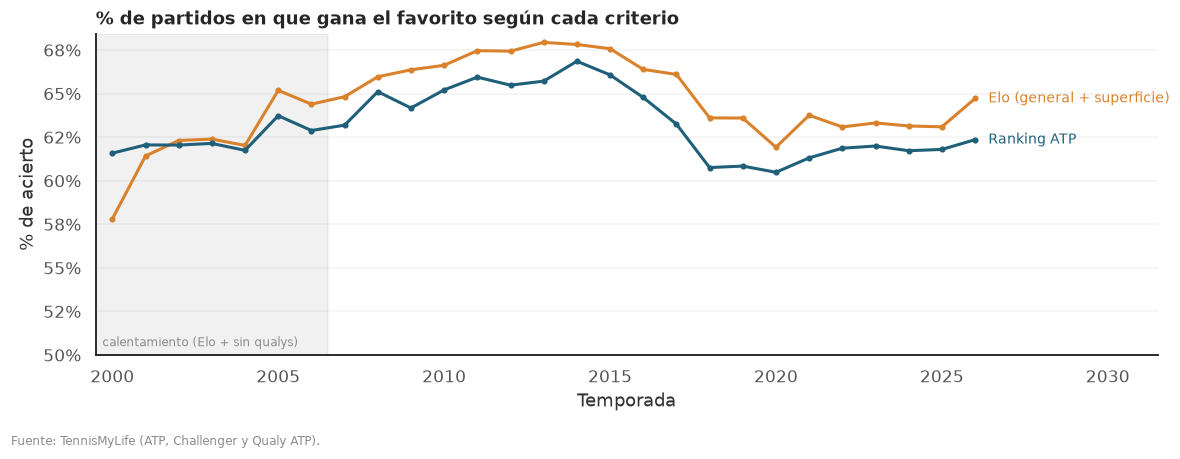

anio,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Elo (general + superficie),57.8%,61.4%,62.3%,62.4%,62.0%,65.2%,64.4%,64.8%,66.0%,66.4%,66.6%,67.5%,67.4%,67.9%,67.8%,67.6%,66.4%,66.1%,63.6%,63.6%,61.9%,63.8%,63.1%,63.3%,63.1%,63.1%,64.7%
Ranking ATP,61.6%,62.1%,62.0%,62.1%,61.7%,63.7%,62.9%,63.2%,65.1%,64.2%,65.2%,65.9%,65.5%,65.7%,66.9%,66.1%,64.8%,63.2%,60.8%,60.8%,60.5%,61.3%,61.9%,62.0%,61.7%,61.8%,62.4%


In [23]:
elo_mix_w = df.winner_elo + df.winner_elo_sup
elo_mix_l = df.loser_elo + df.loser_elo_sup
ambos_rank = df.winner_rank.notna() & df.loser_rank.notna() & (df.winner_rank != df.loser_rank)
acierto = pd.DataFrame({
    'Elo (general + superficie)': (elo_mix_w > elo_mix_l)[elo_mix_w != elo_mix_l].groupby(df.anio).mean(),
    'Ranking ATP': (df.winner_rank < df.loser_rank)[ambos_rank].groupby(df.anio).mean(),
})
fig, ax = plt.subplots(figsize=(11, 4))
ax.axvspan(ANIO_INICIO - .5, ANIO_BURNIN_FIN + .5, color=C_GRIS, alpha=.12)
ax.text(ANIO_INICIO - .3, .505, 'calentamiento (Elo + sin qualys)', fontsize=8, color=C_GRIS)
for col, color in zip(acierto.columns, [C_FOCO, C_PRINCIPAL]):
    ax.plot(acierto.index, acierto[col], marker='o', ms=3, lw=2, color=color)
    ax.text(acierto.index[-1] + .4, acierto[col].iloc[-1], col, color=color, va='center', fontsize=9)
ax.set_xlim(ANIO_INICIO - .5, ANIO_FIN + 5.5); ax.set_ylim(.5, None); pct_axis(ax)
ax.set_title('% de partidos en que gana el favorito según cada criterio'); ax.set_xlabel('Temporada'); ax.set_ylabel('% de acierto')
cerrar('06_convergencia_elo')
display(acierto.T.style.format('{:.1%}'))

### 5.2 Formato jugador-partido y atributos derivados

Cada partido se desdobla en dos registros, uno por jugador, con la variable objetivo `gano` (1/0). Se agregan:

- **Probabilidad Elo** de ganar y **sobre-rendimiento** (`gano − p_elo`): cuánto rindió el jugador respecto de lo esperable según su nivel. Es la métrica que se usa para medir afinidades aislando la fuerza del jugador.
- **Ranking imputado** con valor centinela e indicador, y su logaritmo.
- **Tasas de saque y devolución** (post-partido, solo descriptivas).
- **Descanso** (días desde el torneo anterior) y **carga** (partidos en los 30 días previos al torneo).

*Limitación:* las qualys de algunos torneos (por ejemplo, los Grand Slams) tienen fecha de la semana anterior al cuadro principal, así que para un clasificado ambos figuran como torneos distintos. En la notebook 02 se unifican como un único evento.

In [24]:
BASE_COLS = ['match_uid', 'tourney_id', 'tourney_name', 'tourney_date', 'anio', 'surface', 'surface_elo', 'indoor', 'draw_size',
             'tourney_level', 'categoria', 'circuito', 'fuente', 'es_qualy', 'round', 'orden_ronda', 'best_of', 'minutes', 'resultado_tipo']
ATRIB = ['id', 'name', 'seed', 'entry', 'hand', 'ht', 'ioc', 'age', 'rank', 'rank_points', 'elo', 'elo_sup', 'n_previos', 'n_previos_sup']

def perspectiva(d, yo, rival, s_yo, s_rival, gano):
    cols = {}
    for v in ATRIB:
        cols[v] = d[f'{yo}_{v}'].values
        cols[f'opp_{v}'] = d[f'{rival}_{v}'].values
    for v in STATS:
        cols[f'sv_{v}'] = d[f'{s_yo}_{v}'].values
        cols[f'opp_sv_{v}'] = d[f'{s_rival}_{v}'].values
    x = pd.concat([d[BASE_COLS].reset_index(drop=True), pd.DataFrame(cols)], axis=1)
    x['gano'] = gano
    return x

lon = pd.concat([perspectiva(df, 'winner', 'loser', 'w', 'l', 1),
                 perspectiva(df, 'loser', 'winner', 'l', 'w', 0)], ignore_index=True)

def dividir(a, b):
    return a / b.where(b > 0)

lon['entry'] = lon.entry.fillna('Directa'); lon['opp_entry'] = lon.opp_entry.fillna('Directa')
lon['es_cabeza_serie'] = lon.seed.notna()
lon['sin_ranking'] = lon['rank'].isna()
lon['rank_imp'] = lon['rank'].fillna(RANK_CENTINELA)
lon['opp_rank_imp'] = lon.opp_rank.fillna(RANK_CENTINELA)
lon['log_rank'] = np.log(lon.rank_imp)
lon['log_puntos'] = np.log1p(lon.rank_points.fillna(0))
lon['elo_mix'] = 0.5 * lon.elo + 0.5 * lon.elo_sup
lon['opp_elo_mix'] = 0.5 * lon.opp_elo + 0.5 * lon.opp_elo_sup
lon['p_elo'] = 1 / (1 + 10 ** ((lon.opp_elo - lon.elo) / 400))
lon['p_elo_mix'] = 1 / (1 + 10 ** ((lon.opp_elo_mix - lon.elo_mix) / 400))
lon['sobre_rend'] = lon.gano - lon.p_elo
lon['en_poblacion'] = lon['rank'].between(RANK_MIN, RANK_MAX)
lon['es_arg'] = lon.ioc.eq(PAIS_FOCO)
lon['post_burnin'] = lon.anio > ANIO_BURNIN_FIN

lon['sv_ace_rate'] = dividir(lon.sv_ace, lon.sv_svpt)
lon['sv_df_rate'] = dividir(lon.sv_df, lon.sv_svpt)
lon['sv_1st_in'] = dividir(lon.sv_1stIn, lon.sv_svpt)
lon['sv_1st_won'] = dividir(lon.sv_1stWon, lon.sv_1stIn)
lon['sv_2nd_won'] = dividir(lon.sv_2ndWon, lon.sv_svpt - lon.sv_1stIn)
lon['sv_pts_won'] = dividir(lon.sv_1stWon + lon.sv_2ndWon, lon.sv_svpt)
lon['sv_bp_saved'] = dividir(lon.sv_bpSaved, lon.sv_bpFaced)
lon['ret_pts_won'] = 1 - dividir(lon.opp_sv_1stWon + lon.opp_sv_2ndWon, lon.opp_sv_svpt)
print(f'Formato jugador-partido: {lon.shape[0]:,} filas × {lon.shape[1]} columnas')

Formato jugador-partido: 446,380 filas × 88 columnas


In [25]:
# Descanso y carga reciente (solo con información previa al torneo)
lon = lon.sort_values(['id', 'tourney_date', 'orden_ronda', 'match_uid'], kind='mergesort').reset_index(drop=True)
fechas = lon[['id', 'tourney_date']].drop_duplicates().copy()
fechas['dias_descanso'] = fechas.groupby('id').tourney_date.diff().dt.days
lon = lon.merge(fechas, on=['id', 'tourney_date'], how='left')

dias = lon.tourney_date.values.astype('datetime64[D]').astype(np.int64)
carga = np.zeros(len(lon))
for _, idx in lon.groupby('id', sort=False).indices.items():
    tt = dias[idx]
    carga[idx] = np.searchsorted(tt, tt, 'left') - np.searchsorted(tt, tt - 30, 'left')
lon['carga_30d'] = carga

# Se llevan a la tabla por partido para el formato A/B
for gano, pref in [(1, 'winner'), (0, 'loser')]:
    aux = lon.loc[lon.gano == gano, ['match_uid', 'dias_descanso', 'carga_30d']].set_index('match_uid')
    df[f'{pref}_dias_descanso'] = df.match_uid.map(aux.dias_descanso)
    df[f'{pref}_carga_30d'] = df.match_uid.map(aux.carga_30d)
display(lon[['dias_descanso', 'carga_30d']].describe(percentiles=[.25, .5, .75, .95]).T)

,count,mean,std,min,25%,50%,75%,95%,max
dias_descanso,438737.0,32.894256,103.768764,1.0,7.0,13.0,21.0,105.0,6399.0
carga_30d,446380.0,3.658869,3.061436,0.0,1.0,3.0,6.0,9.0,23.0


## 6. Análisis univariado

### 6.1 Variables categóricas

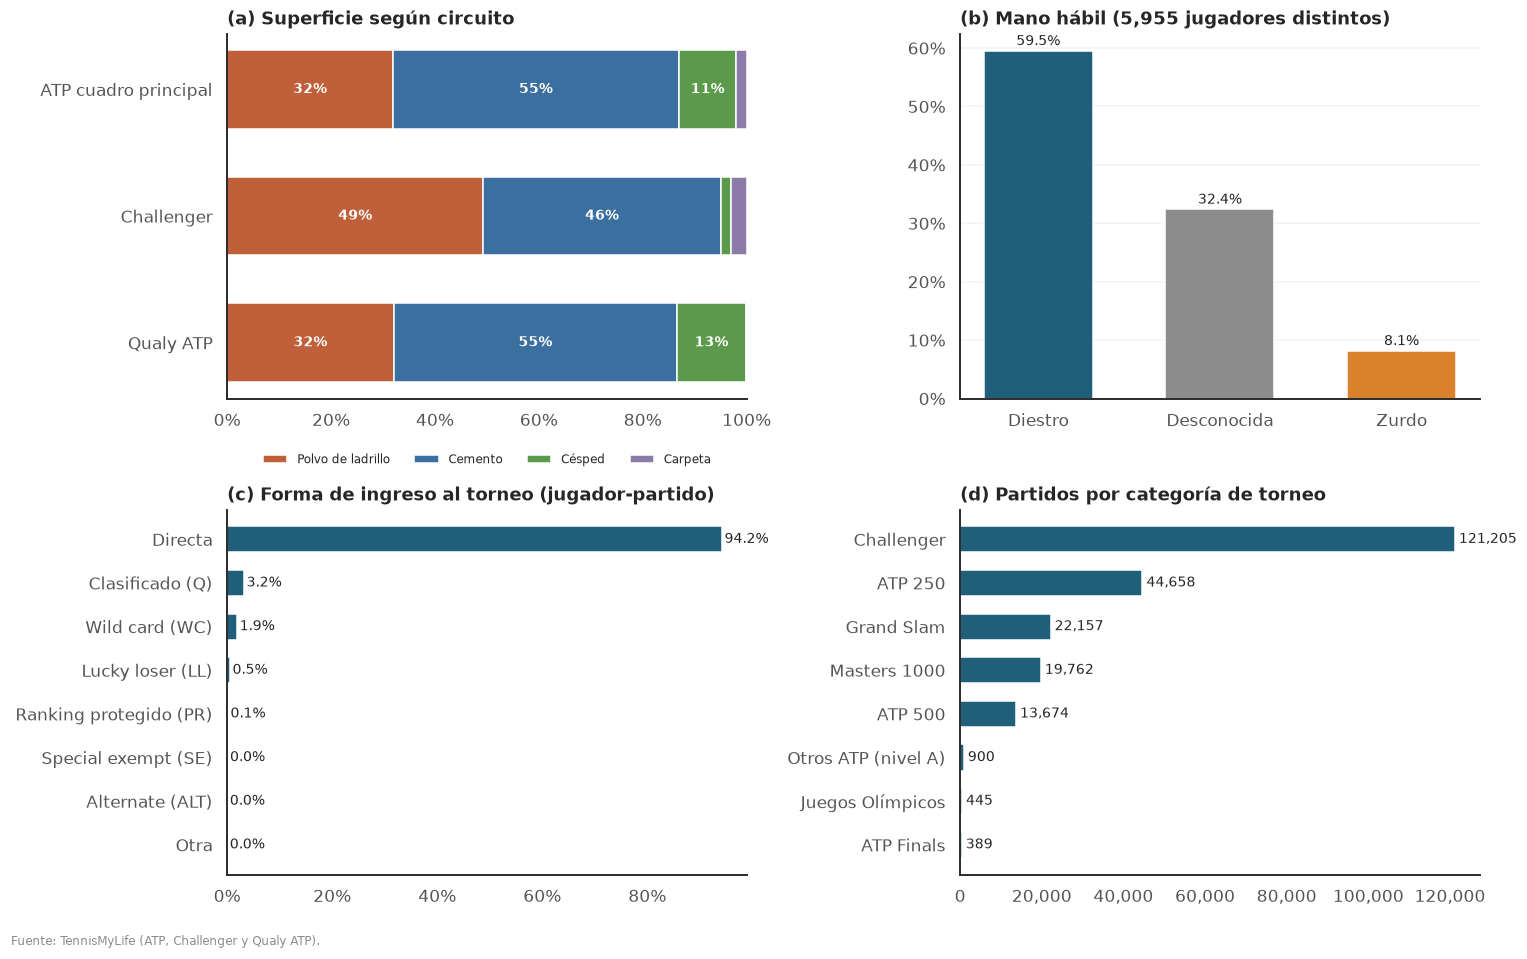

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
ct = pd.crosstab(df.circuito, df.surface, normalize='index').reindex(index=circ_presentes[::-1])
ct = ct[[s for s in SUPERFICIES if s in ct.columns]]
barras_apiladas(axes[0, 0], ct, PALETA_SUP, NOMBRE_SUP)
axes[0, 0].set_title('(a) Superficie según circuito')

ax = axes[0, 1]
jugadores = lon.sort_values('tourney_date').drop_duplicates('id', keep='last')
mano = jugadores.hand.map({'R': 'Diestro', 'L': 'Zurdo'}).fillna('Desconocida').value_counts(normalize=True)
col_mano = {'Diestro': C_PRINCIPAL, 'Zurdo': C_FOCO, 'Desconocida': C_GRIS}
ax.bar(mano.index, mano.values, color=[col_mano[k] for k in mano.index], width=.6)
for i, v in enumerate(mano.values):
    ax.text(i, v + .01, f'{v:.1%}', ha='center', fontsize=9)
pct_axis(ax); ax.set_title(f'(b) Mano hábil ({len(jugadores):,} jugadores distintos)')

ax = axes[1, 0]
ENTRADAS = {'Directa': 'Directa', 'Q': 'Clasificado (Q)', 'WC': 'Wild card (WC)', 'LL': 'Lucky loser (LL)',
            'PR': 'Ranking protegido (PR)', 'SE': 'Special exempt (SE)', 'ALT': 'Alternate (ALT)'}
ent = lon.entry.map(ENTRADAS).fillna('Otra').value_counts(normalize=True).sort_values()
ax.barh(ent.index, ent.values, color=C_PRINCIPAL, height=.6)
for y, v in enumerate(ent.values):
    ax.text(v + .005, y, f'{v:.1%}', va='center', fontsize=9)
pct_axis(ax, 'x'); ax.grid(False); ax.set_title('(c) Forma de ingreso al torneo (jugador-partido)')

ax = axes[1, 1]
cat = df.categoria.value_counts().sort_values()
ax.barh(cat.index, cat.values, color=C_PRINCIPAL, height=.6)
for y, v in enumerate(cat.values):
    ax.text(v, y, f' {v:,}', va='center', fontsize=9)
ax.grid(False); ax.set_title('(d) Partidos por categoría de torneo'); ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
cerrar('07_univariado_categoricas')

### 6.2 Variables numéricas

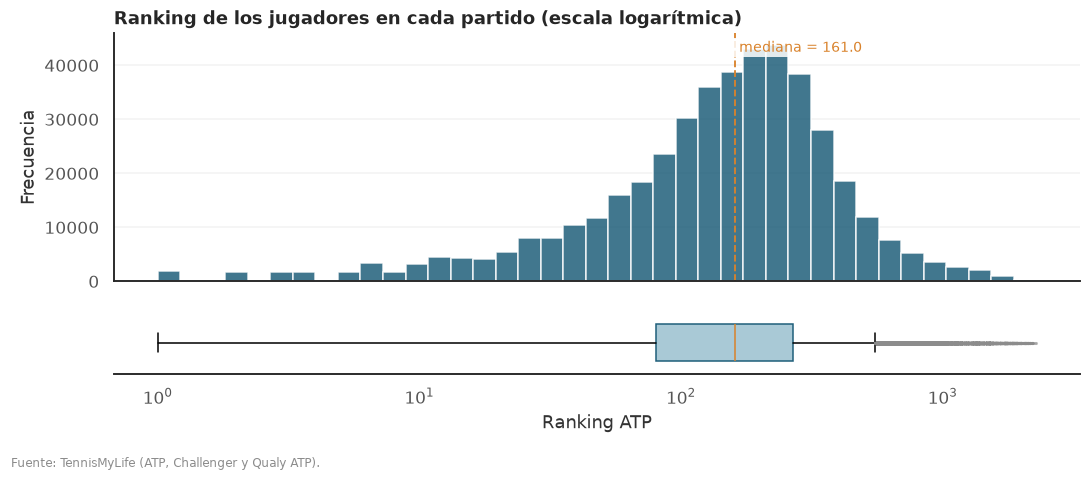

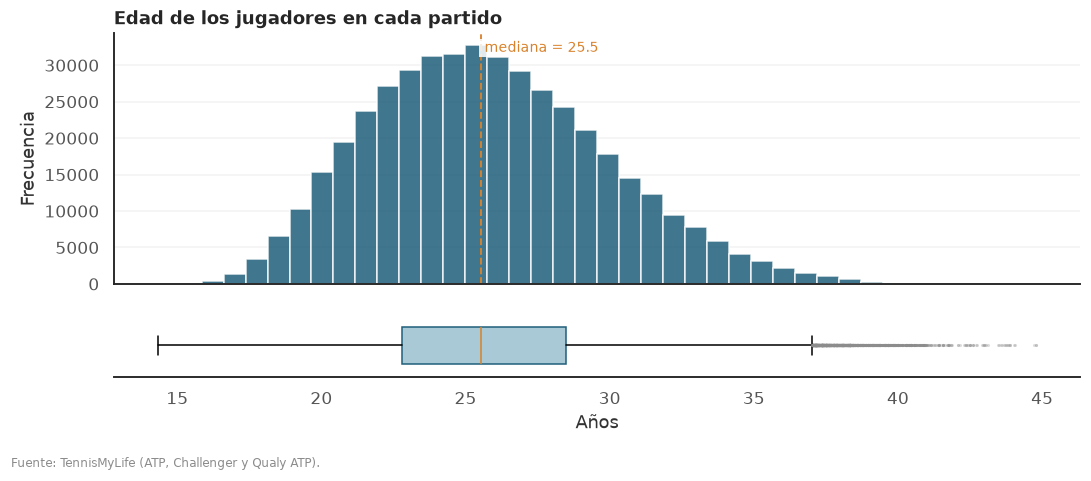

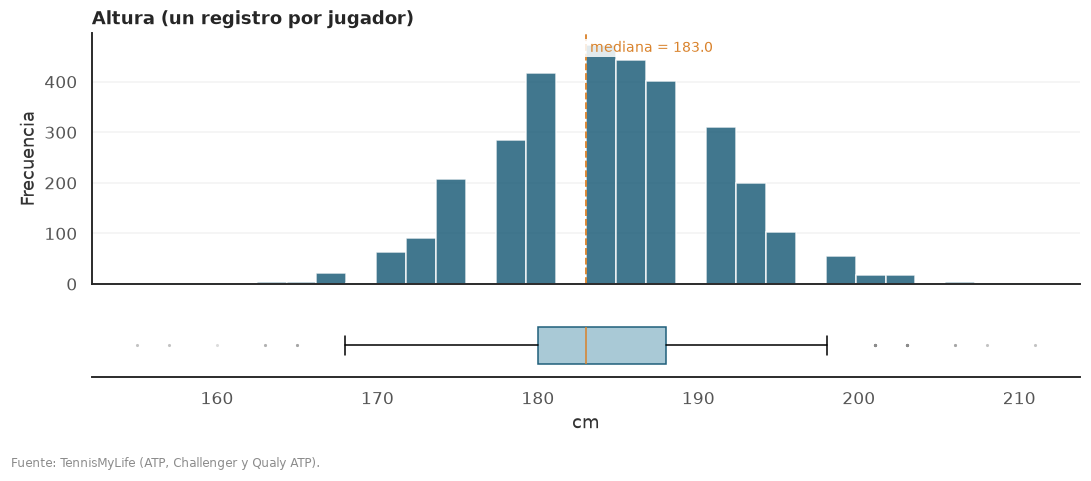

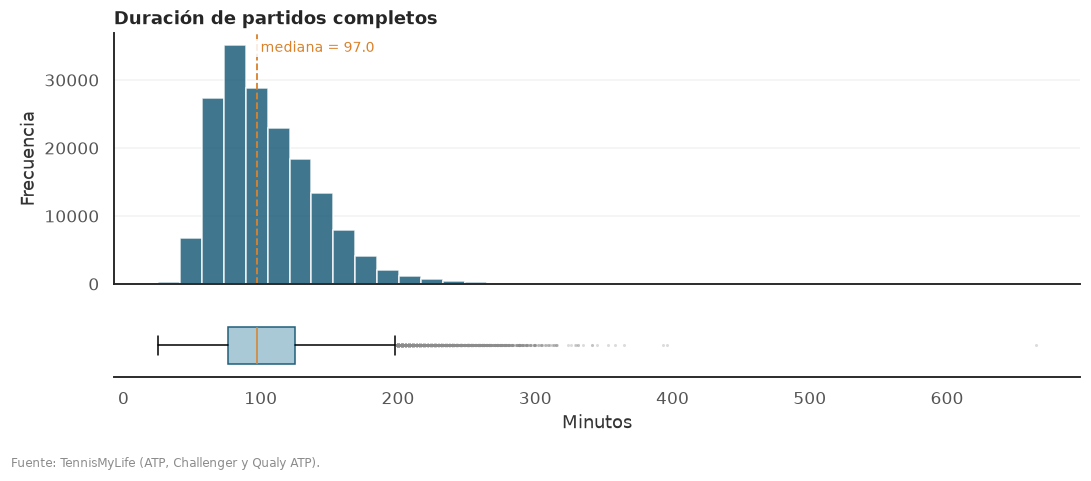

,count,mean,std,min,5%,25%,50%,75%,95%,max
Ranking ATP,"442,887.0",211.4,215.1,1.0,14.0,80.0,161.0,268.0,575.0,"2,279.0"
Edad (años),"446,056.0",25.8,4.1,14.3,19.7,22.8,25.5,28.5,33.0,44.8
Altura (cm),"3,125.0",184.2,6.9,155.0,173.0,180.0,183.0,188.0,196.0,211.0
Duración (min),"169,959.0",103.7,36.3,25.0,58.0,76.0,97.0,125.0,170.0,665.0


,ranking_mediano,edad_media,altura_media,pct_sin_ranking
circuito,,,,
ATP cuadro principal,53,26.6,186.1,0.2%
Challenger,229,25.3,184.4,0.5%
Qualy ATP,180,26.0,185.2,3.4%


In [27]:
def hist_box(s, titulo, xlabel, nombre, bins=40, logx=False, color=C_PRINCIPAL):
    s = pd.Series(s).dropna().astype(float)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 4.2), sharex=True, gridspec_kw={'height_ratios': [4, 1]})
    if logx:
        bins = np.logspace(np.log10(max(s.min(), 1)), np.log10(s.max()), bins)
        ax1.set_xscale('log')
    ax1.hist(s, bins=bins, color=color, alpha=.85, edgecolor='white')
    med = s.median()
    ax1.axvline(med, color=C_FOCO, ls='--', lw=1.2)
    ax1.text(med, ax1.get_ylim()[1] * .97, f' mediana = {med:,.1f} ', color=C_FOCO, va='top', fontsize=9,
             bbox=dict(facecolor='white', edgecolor='none', alpha=.85, pad=1))
    ax2.boxplot(s, vert=False, widths=.6, patch_artist=True,
                boxprops=dict(facecolor=C_SECUNDARIO, color=C_PRINCIPAL), medianprops=dict(color=C_FOCO),
                flierprops=dict(marker='.', markersize=2, alpha=.3, markeredgecolor=C_GRIS))
    ax2.set_yticks([]); ax2.grid(False); ax2.spines['left'].set_visible(False); ax2.set_xlabel(xlabel)
    ax1.set_title(titulo); ax1.set_ylabel('Frecuencia')
    cerrar(nombre)
    return s.describe(percentiles=[.05, .25, .5, .75, .95])

resumen_num = {
    'Ranking ATP': hist_box(lon['rank'], 'Ranking de los jugadores en cada partido (escala logarítmica)', 'Ranking ATP', '08a_ranking', logx=True),
    'Edad (años)': hist_box(lon.age, 'Edad de los jugadores en cada partido', 'Años', '08b_edad'),
    'Altura (cm)': hist_box(jugadores.ht, 'Altura (un registro por jugador)', 'cm', '08c_altura', bins=30),
    'Duración (min)': hist_box(df.loc[df.resultado_tipo.eq('Completo'), 'minutes'], 'Duración de partidos completos', 'Minutos', '08d_duracion'),
}
display(pd.DataFrame(resumen_num).T.style.format('{:,.1f}'))
display(lon.groupby('circuito').agg(ranking_mediano=('rank', 'median'), edad_media=('age', 'mean'), altura_media=('ht', 'mean'),
                                    pct_sin_ranking=('sin_ranking', 'mean')).reindex(circ_presentes)
          .style.format({'ranking_mediano': '{:,.0f}', 'edad_media': '{:.1f}', 'altura_media': '{:.1f}', 'pct_sin_ranking': '{:.1%}'}))

### 6.3 Población objetivo (ranking 100–300)

Se caracteriza dónde compiten los jugadores de la población objetivo y sobre qué superficies. Esto valida empíricamente la decisión de incorporar el circuito Challenger y las clasificaciones.

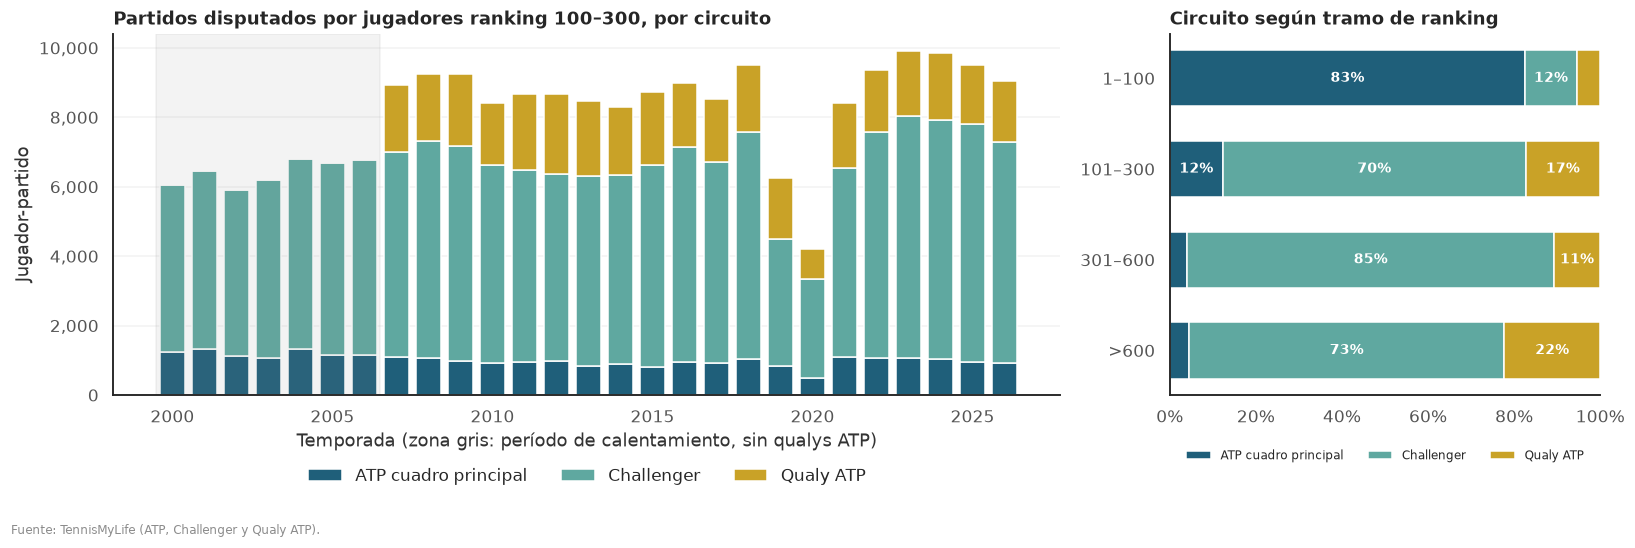

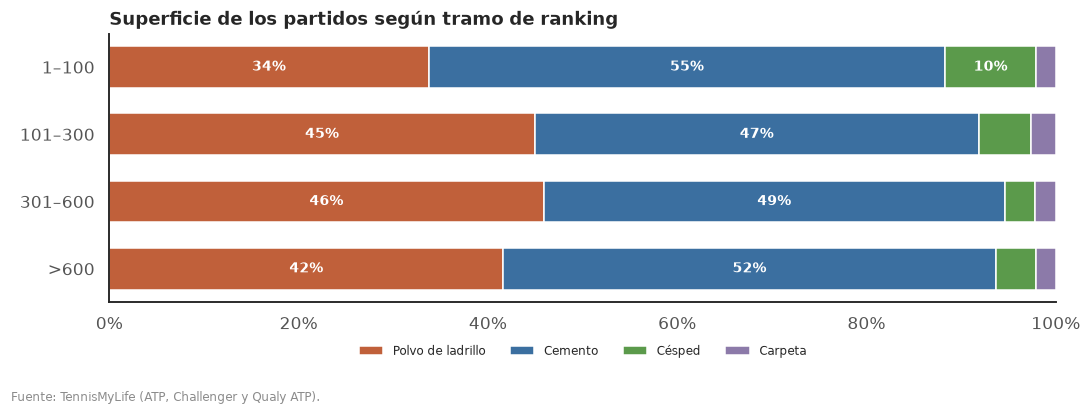

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [2.2, 1]})
ax = axes[0]
serie = lon[lon.en_poblacion].groupby(['anio', 'circuito']).size().unstack().reindex(columns=circ_presentes).fillna(0)
abajo = np.zeros(len(serie))
for c in serie.columns:
    ax.bar(serie.index, serie[c], bottom=abajo, color=PALETA_CIRCUITO[c], label=c, width=.8)
    abajo += serie[c].values
ax.axvspan(ANIO_INICIO - .5, ANIO_BURNIN_FIN + .5, color=C_GRIS, alpha=.1)
ax.set_title(f'Partidos disputados por jugadores ranking {RANK_MIN}–{RANK_MAX}, por circuito')
ax.set_xlabel('Temporada (zona gris: período de calentamiento, sin qualys ATP)'); ax.set_ylabel('Jugador-partido')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.16), ncol=3)

tr = lon.assign(tramo=pd.cut(lon['rank'], TRAMOS, labels=ETIQ_TRAMOS)).dropna(subset=['tramo'])
mix = pd.crosstab(tr.tramo, tr.circuito, normalize='index').reindex(columns=circ_presentes).iloc[::-1]
barras_apiladas(axes[1], mix, PALETA_CIRCUITO)
axes[1].set_title('Circuito según tramo de ranking')
cerrar('09_poblacion_objetivo')

sup_tramo = pd.crosstab(tr.tramo, tr.surface, normalize='index').iloc[::-1]
sup_tramo = sup_tramo[[s for s in SUPERFICIES if s in sup_tramo.columns]]
fig, ax = plt.subplots(figsize=(10, 3.6))
barras_apiladas(ax, sup_tramo, PALETA_SUP, NOMBRE_SUP)
ax.set_title('Superficie de los partidos según tramo de ranking')
cerrar('10_superficie_por_tramo')

### 6.4 Foco argentino

Presencia argentina en la población objetivo y jugadores con más actividad reciente, candidatos para el análisis por jugador.

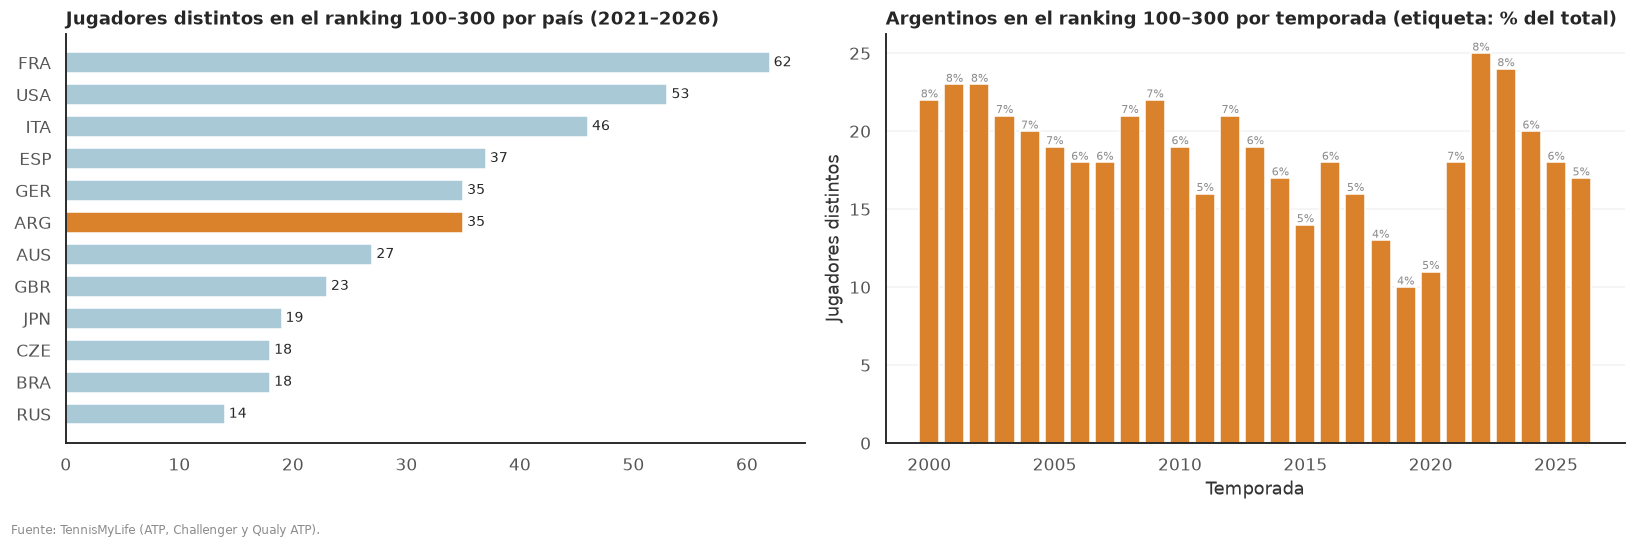

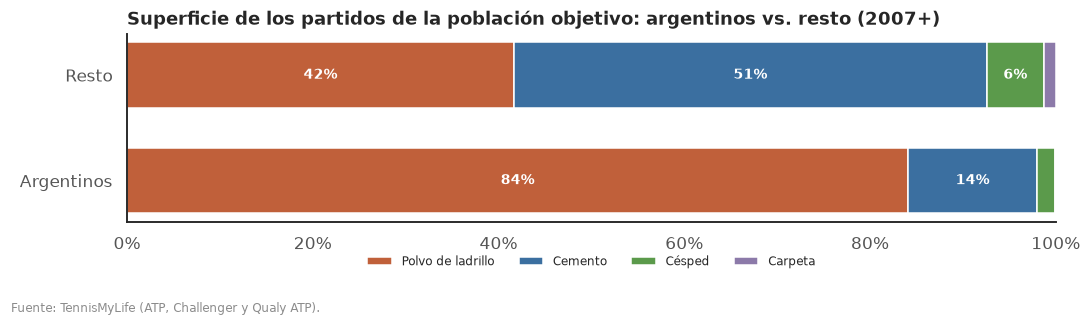

In [29]:
ultimas = lon[lon.en_poblacion & lon.anio.between(ANIO_FIN - 5, ANIO_FIN)]
paises = ultimas.groupby('ioc').id.nunique().sort_values(ascending=False).head(12).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ax = axes[0]
ax.barh(paises.index, paises.values, color=[C_FOCO if p == PAIS_FOCO else C_SECUNDARIO for p in paises.index], height=.65)
for y, v in enumerate(paises.values):
    ax.text(v, y, f' {v}', va='center', fontsize=9)
ax.grid(False); ax.set_title(f'Jugadores distintos en el ranking {RANK_MIN}–{RANK_MAX} por país ({ANIO_FIN - 5}–{ANIO_FIN})')

ax = axes[1]
pob_all = lon[lon.en_poblacion]
anual = pd.DataFrame({'arg': pob_all[pob_all.es_arg].groupby('anio').id.nunique(),
                      'total': pob_all.groupby('anio').id.nunique()}).fillna(0)
ax.bar(anual.index, anual.arg, color=C_FOCO, width=.8)
for x, (a, tot) in anual.iterrows():
    if tot > 0:
        ax.text(x, a, f'{a / tot:.0%}', ha='center', va='bottom', fontsize=7, color=C_GRIS)
ax.set_title(f'Argentinos en el ranking {RANK_MIN}–{RANK_MAX} por temporada (etiqueta: % del total)')
ax.set_xlabel('Temporada'); ax.set_ylabel('Jugadores distintos')
cerrar('11_presencia_argentina')

base_sup = lon[lon.en_poblacion & lon.post_burnin].assign(grupo=lambda x: np.where(x.es_arg, 'Argentinos', 'Resto'))
mix_arg = pd.crosstab(base_sup.grupo, base_sup.surface, normalize='index')
mix_arg = mix_arg[[s for s in SUPERFICIES if s in mix_arg.columns]]
fig, ax = plt.subplots(figsize=(10, 2.8))
barras_apiladas(ax, mix_arg, PALETA_SUP, NOMBRE_SUP)
ax.set_title(f'Superficie de los partidos de la población objetivo: argentinos vs. resto ({ANIO_BURNIN_FIN + 1}+)')
cerrar('12_superficie_argentinos')

In [30]:
candidatos = (lon[lon.en_poblacion & lon.es_arg & lon.anio.ge(ANIO_FIN - 10)]
              .groupby(['id', 'name'])
              .agg(partidos=('gano', 'size'), pct_victorias=('gano', 'mean'),
                   pct_polvo=('surface', lambda s: (s == 'Clay').mean()), mejor_rank_en_rango=('rank', 'min'),
                   temporadas=('anio', 'nunique'), ultima_temporada=('anio', 'max'),
                   mano=('hand', lambda s: s.mode().iloc[0] if s.notna().any() else None),
                   altura=('ht', 'median'), sobre_rend_elo=('sobre_rend', 'mean'))
              .sort_values('partidos', ascending=False).head(20).reset_index())
print(f'Argentinos con más partidos en el ranking {RANK_MIN}–{RANK_MAX} ({ANIO_FIN - 10}–{ANIO_FIN}): candidatos para el análisis por jugador')
display(candidatos.style.format({'pct_victorias': '{:.1%}', 'pct_polvo': '{:.1%}', 'mejor_rank_en_rango': '{:.0f}',
                                 'altura': '{:.0f}', 'sobre_rend_elo': '{:+.3f}'}))

Argentinos con más partidos en el ranking 100–300 (2016–2026): candidatos para el análisis por jugador


,id,name,partidos,pct_victorias,pct_polvo,mejor_rank_en_rango,temporadas,ultima_temporada,mano,altura,sobre_rend_elo
0,TA29,Marco Trungelliti,494,58.1%,64.4%,112,11,2026,R,178,+0.021
1,CC66,Andrea Collarini,359,45.7%,90.8%,177,10,2026,L,183,+0.001
2,BF23,Facundo Bagnis,357,61.6%,89.4%,100,9,2024,L,183,+0.031
3,O376,Renzo Olivo,326,47.9%,82.2%,100,8,2024,R,178,-0.013
4,FA43,Juan Pablo Ficovich,314,46.5%,65.3%,126,7,2026,R,188,-0.014
5,T0A1,Thiago Agustin Tirante,276,56.9%,71.7%,100,6,2026,R,185,+0.035
6,C0C8,Juan Manuel Cerundolo,272,61.0%,91.9%,100,5,2025,L,183,+0.020
7,A887,Guido Andreozzi,264,53.8%,83.7%,101,8,2024,R,183,-0.016
8,B0FV,Roman Andres Burruchaga,230,60.9%,87.8%,101,5,2026,R,183,+0.043
9,U182,Camilo Ugo Carabelli,219,64.4%,91.3%,100,5,2025,R,185,+0.031


## 7. Análisis bivariado

Qué variables del jugador y del contexto se asocian con ganar partidos.

### 7.1 Ranking y resultado

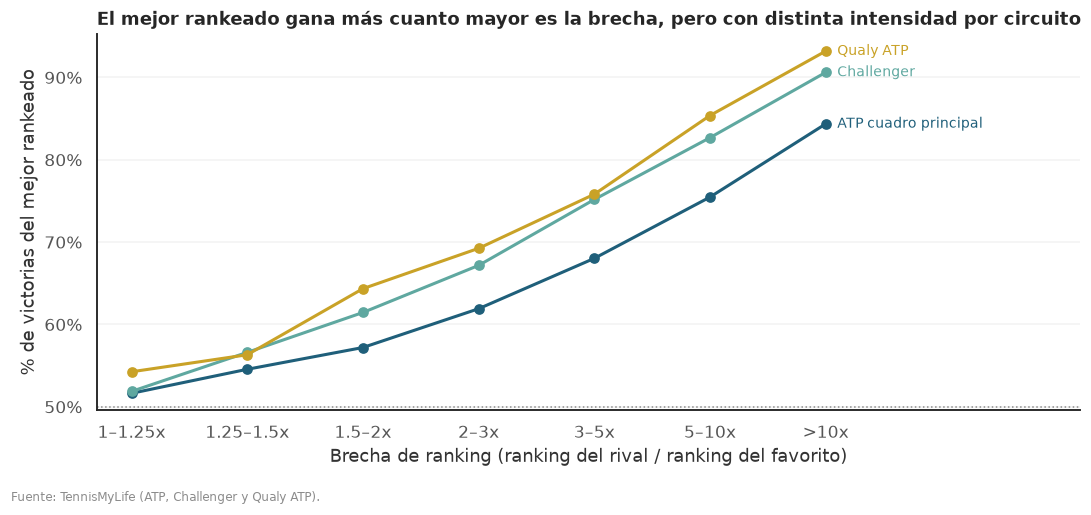

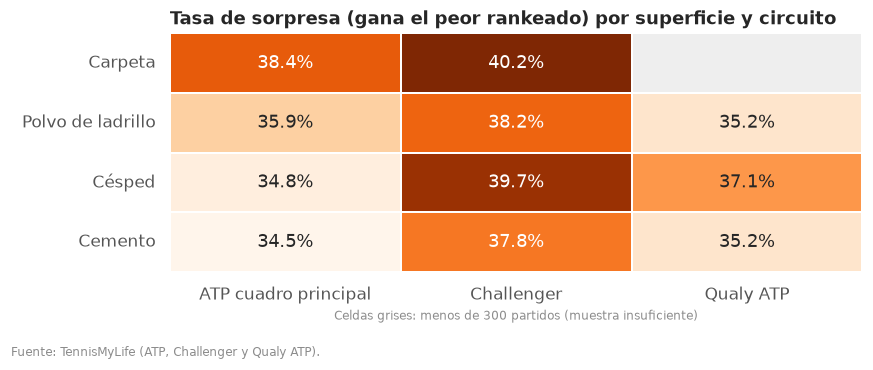

In [31]:
b = df.dropna(subset=['winner_rank', 'loser_rank']).query('winner_rank != loser_rank').copy()
b['fav_gana'] = b.winner_rank < b.loser_rank
b['brecha'] = np.maximum(b.winner_rank, b.loser_rank) / np.minimum(b.winner_rank, b.loser_rank)
ETIQ_BRECHA = ['1–1.25x', '1.25–1.5x', '1.5–2x', '2–3x', '3–5x', '5–10x', '>10x']
b['tramo_brecha'] = pd.cut(b.brecha, [1, 1.25, 1.5, 2, 3, 5, 10, np.inf], labels=ETIQ_BRECHA, right=False)
g = b.groupby(['circuito', 'tramo_brecha'], observed=True).fav_gana.agg(['mean', 'size']).reset_index()

fig, ax = plt.subplots(figsize=(10, 4.5))
for c in circ_presentes:
    s = g[g.circuito == c]
    x = s.tramo_brecha.cat.codes
    ax.plot(x, s['mean'], marker='o', color=PALETA_CIRCUITO[c], lw=2)
    if len(s):
        ax.text(x.iloc[-1] + .1, s['mean'].iloc[-1], c, color=PALETA_CIRCUITO[c], va='center', fontsize=9)
ax.axhline(.5, color=C_GRIS, lw=1, ls=':')
ax.set_xticks(range(len(ETIQ_BRECHA))); ax.set_xticklabels(ETIQ_BRECHA); ax.set_xlim(-.3, len(ETIQ_BRECHA) + 1.2)
pct_axis(ax); ax.set_ylabel('% de victorias del mejor rankeado')
ax.set_xlabel('Brecha de ranking (ranking del rival / ranking del favorito)')
ax.set_title('El mejor rankeado gana más cuanto mayor es la brecha, pero con distinta intensidad por circuito')
cerrar('13_favorito_vs_brecha')

sorpresa = 1 - b.groupby(['surface', 'circuito']).fav_gana.mean().unstack().reindex(columns=circ_presentes)
n_sorpresa = b.groupby(['surface', 'circuito']).size().unstack().reindex(index=sorpresa.index, columns=circ_presentes)
sorpresa = sorpresa.where(n_sorpresa >= 300)
sorpresa.index = [NOMBRE_SUP.get(s, s) for s in sorpresa.index]
fig, ax = plt.subplots(figsize=(8, 3.2))
sns.heatmap(sorpresa.astype(float), annot=True, fmt='.1%', cmap='Oranges', cbar=False, linewidths=1, linecolor='white', ax=ax)
ax.set_facecolor('#eeeeee')
ax.set_title('Tasa de sorpresa (gana el peor rankeado) por superficie y circuito'); ax.set_ylabel(''); ax.grid(False)
ax.set_xlabel('Celdas grises: menos de 300 partidos (muestra insuficiente)', fontsize=8, color=C_GRIS)
cerrar('14_sorpresas')

### 7.2 Afinidad por superficie: ¿los argentinos rinden más en polvo de ladrillo?

El porcentaje de victorias mezcla el nivel del jugador con su afinidad por la superficie. El **sobre-rendimiento respecto del Elo general** aísla la afinidad: si un grupo gana en una superficie más de lo que predice su Elo general, esa diferencia se atribuye a la superficie. La significancia se evalúa con un test t de Welch.

Como los partidos de un mismo jugador no son independientes, los p-valores son optimistas y se leen como evidencia orientativa. En la notebook 02 la afinidad se modela a nivel individual.

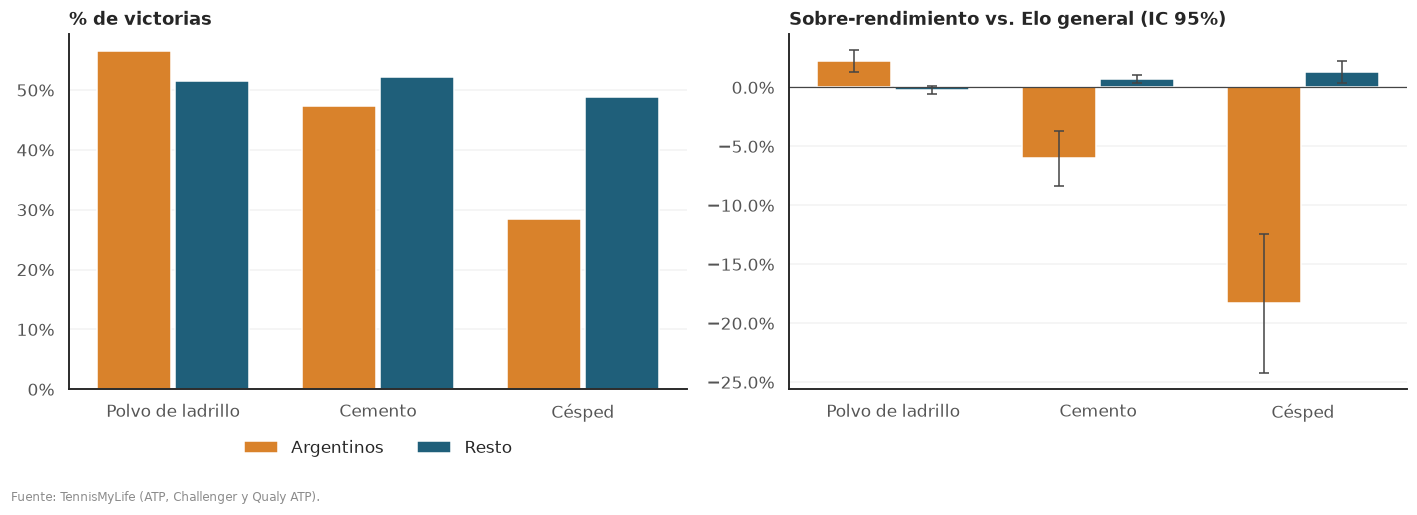

,ARG,Resto,t,p_valor,n_ARG
Polvo de ladrillo,+0.022,-0.002,4.85,1.25e-06,"9,837"
Cemento,-0.060,+0.007,-5.66,1.82e-08,"1,618"
Césped,-0.183,+0.013,-6.43,6.96e-10,228


In [32]:
ORDEN_S = ['Clay', 'Hard', 'Grass']
base = lon[lon.en_poblacion & lon.post_burnin & lon.surface.isin(ORDEN_S)].copy()
base['grupo'] = np.where(base.es_arg, 'Argentinos', 'Resto')
afinidad = (base.groupby(['surface', 'grupo'])
            .agg(victorias=('gano', 'mean'), sobre_rend=('sobre_rend', 'mean'), ic=('sobre_rend', ic95), n=('gano', 'size'))
            .reset_index())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, met, tit in [(axes[0], 'victorias', '% de victorias'),
                     (axes[1], 'sobre_rend', 'Sobre-rendimiento vs. Elo general (IC 95%)')]:
    for j, (grp, col) in enumerate([('Argentinos', C_FOCO), ('Resto', C_PRINCIPAL)]):
        s = afinidad[afinidad.grupo == grp].set_index('surface').reindex(ORDEN_S)
        x = np.arange(len(ORDEN_S)) + (j - .5) * .38
        ax.bar(x, s[met], width=.36, color=col, label=grp,
               yerr=s['ic'] if met == 'sobre_rend' else None, capsize=3, error_kw={'lw': 1, 'ecolor': '#444'})
    ax.set_xticks(range(len(ORDEN_S))); ax.set_xticklabels([NOMBRE_SUP[s] for s in ORDEN_S]); ax.set_title(tit)
    pct_axis(ax, 'y', 1 if met == 'sobre_rend' else 0)
axes[1].axhline(0, color='#444', lw=.8)
axes[0].legend(ncol=2, loc='upper center', bbox_to_anchor=(.5, -.1))
cerrar('15_afinidad_superficie')

tests_afinidad = {}
for sup in ORDEN_S:
    a = base.loc[(base.surface == sup) & base.es_arg, 'sobre_rend'].dropna()
    r = base.loc[(base.surface == sup) & ~base.es_arg, 'sobre_rend'].dropna()
    if len(a) > 30 and len(r) > 30:
        t_stat, p = stats.ttest_ind(a, r, equal_var=False)
        tests_afinidad[sup] = {'ARG': a.mean(), 'Resto': r.mean(), 't': t_stat, 'p_valor': p, 'n_ARG': len(a)}
display(pd.DataFrame(tests_afinidad).T.rename(index=NOMBRE_SUP)
          .style.format({'ARG': '{:+.3f}', 'Resto': '{:+.3f}', 't': '{:.2f}', 'p_valor': '{:.3g}', 'n_ARG': '{:,.0f}'}))

### 7.3 Perfil físico y saque: altura vs. porcentaje de aces

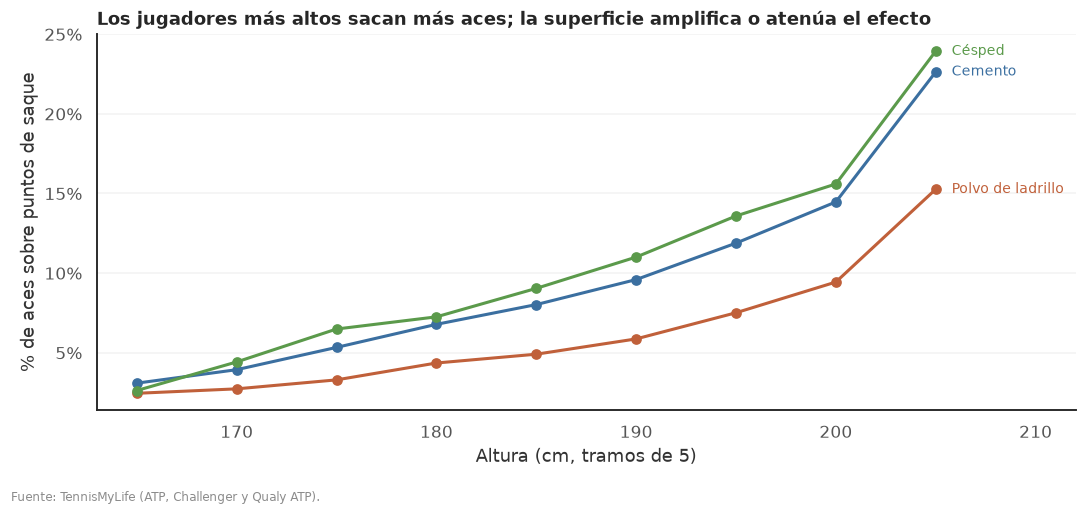

Correlación de Spearman altura – % de aces: rho = 0.341 (p = 0.00e+00)


In [33]:
s = lon[lon.sv_svpt.ge(30) & lon.ht.notna() & lon.surface.isin(ORDEN_S)].copy()
s['tramo_ht'] = (s.ht // 5 * 5).clip(165, 205)
g = s.groupby(['surface', 'tramo_ht']).sv_ace_rate.agg(['mean', 'size']).reset_index()
g = g[g['size'] >= 30]
fig, ax = plt.subplots(figsize=(10, 4.5))
for sup in ORDEN_S:
    x = g[g.surface == sup]
    if len(x):
        ax.plot(x.tramo_ht, x['mean'], marker='o', color=PALETA_SUP[sup], lw=2)
        ax.text(x.tramo_ht.iloc[-1] + .8, x['mean'].iloc[-1], NOMBRE_SUP[sup], color=PALETA_SUP[sup], va='center', fontsize=9)
pct_axis(ax); ax.set_xlim(None, g.tramo_ht.max() + 7 if len(g) else None)
ax.set_xlabel('Altura (cm, tramos de 5)'); ax.set_ylabel('% de aces sobre puntos de saque')
ax.set_title('Los jugadores más altos sacan más aces; la superficie amplifica o atenúa el efecto')
cerrar('16_altura_aces')
if len(s) > 2:
    rho, p = stats.spearmanr(s.ht, s.sv_ace_rate)
    print(f'Correlación de Spearman altura – % de aces: rho = {rho:.3f} (p = {p:.2e})')

### 7.4 Descanso, carga, forma de ingreso y edad

Se evalúan contra el Elo para no confundirlas con el nivel del jugador (por ejemplo, los mejores jugadores llegan lejos y juegan menos torneos).

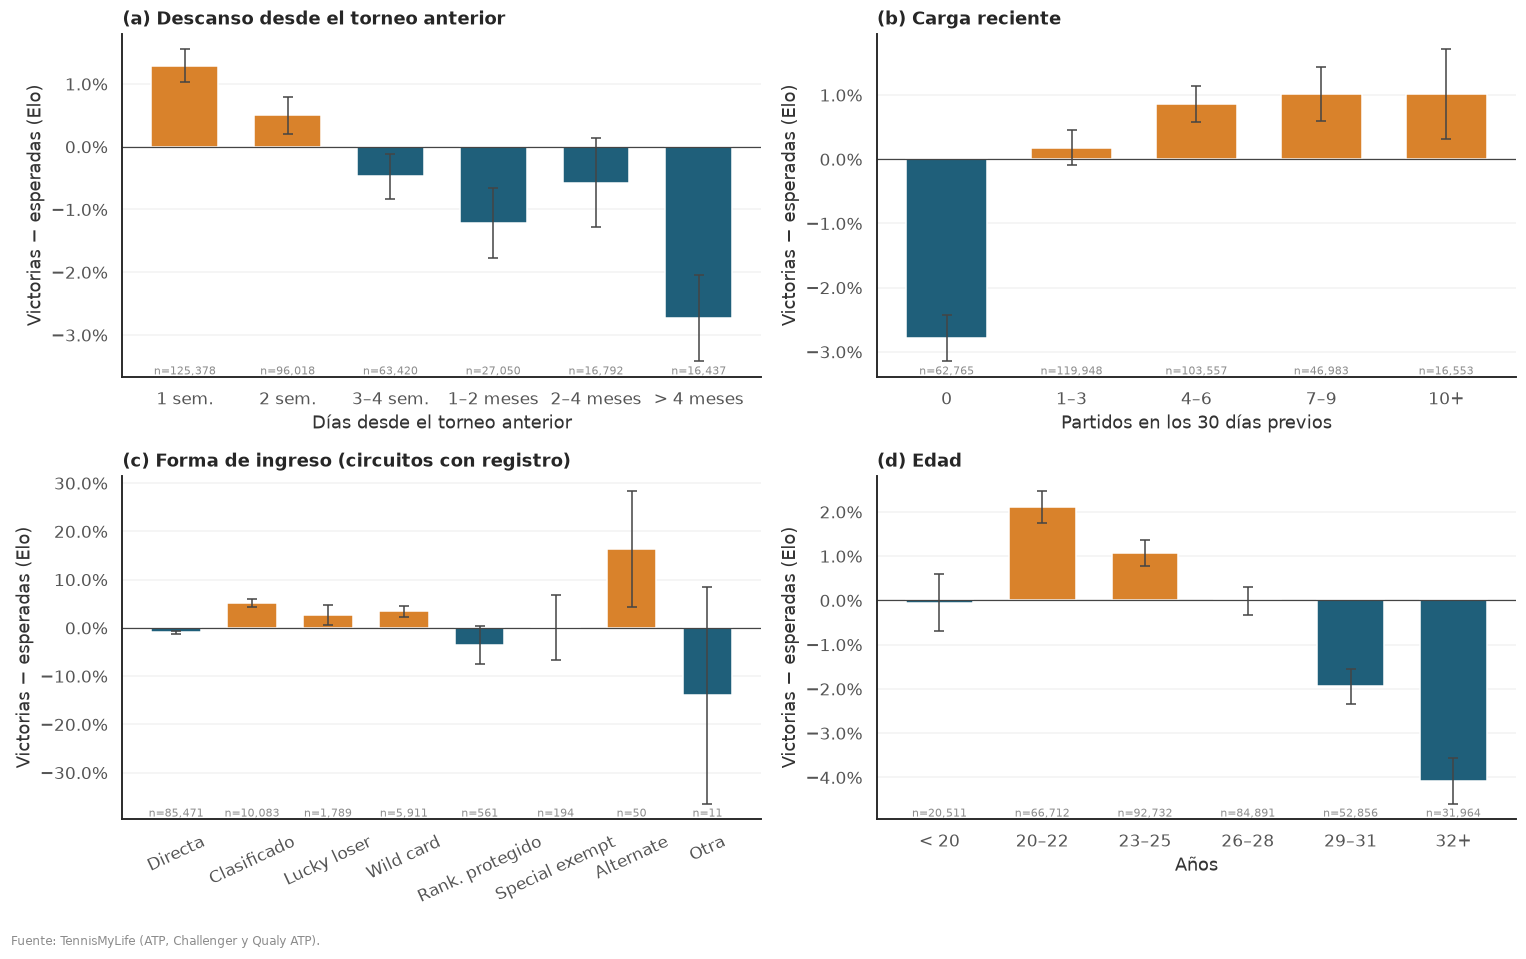

In [34]:
def graficar_sobre_rend(ax, datos, col, titulo, xlabel, orden=None):
    r = datos.groupby(col, observed=True).sobre_rend.agg(media='mean', ic=ic95, n='size')
    if orden is not None:
        r = r.reindex([o for o in orden if o in r.index])
    ax.bar(r.index.astype(str), r.media, yerr=r.ic, capsize=3, error_kw={'lw': 1, 'ecolor': '#444'},
           color=[C_FOCO if v > 0 else C_PRINCIPAL for v in r.media], width=.65)
    ax.axhline(0, color='#444', lw=.8)
    for i, n_ in enumerate(r.n):
        ax.text(i, ax.get_ylim()[0], f'n={n_:,}', ha='center', va='bottom', fontsize=7, color=C_GRIS)
    ax.set_title(titulo); ax.set_xlabel(xlabel); ax.set_ylabel('Victorias − esperadas (Elo)')
    pct_axis(ax, 'y', 1)
    return r

post = lon[lon.post_burnin].copy()
post['tramo_descanso'] = pd.cut(post.dias_descanso, [0, 8, 15, 29, 57, 113, np.inf], right=False,
                                labels=['1 sem.', '2 sem.', '3–4 sem.', '1–2 meses', '2–4 meses', '> 4 meses'])
post['tramo_carga'] = pd.cut(post.carga_30d, [0, 1, 4, 7, 10, np.inf], right=False, labels=['0', '1–3', '4–6', '7–9', '10+'])
post['entrada'] = post.entry.map({'Directa': 'Directa', 'Q': 'Clasificado', 'WC': 'Wild card', 'LL': 'Lucky loser',
                                  'PR': 'Rank. protegido', 'SE': 'Special exempt', 'ALT': 'Alternate'}).fillna('Otra')
post['tramo_edad'] = pd.cut(post.age, [0, 20, 23, 26, 29, 32, 60], right=False, labels=['< 20', '20–22', '23–25', '26–28', '29–31', '32+'])

fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
rend_descanso = graficar_sobre_rend(axes[0, 0], post, 'tramo_descanso', '(a) Descanso desde el torneo anterior', 'Días desde el torneo anterior')
rend_carga = graficar_sobre_rend(axes[0, 1], post, 'tramo_carga', '(b) Carga reciente', 'Partidos en los 30 días previos')
rend_entrada = graficar_sobre_rend(axes[1, 0], post[post.circuito.isin(CIRC_CON_ENTRY)], 'entrada',
                                   '(c) Forma de ingreso (circuitos con registro)', '',
                                   orden=['Directa', 'Clasificado', 'Lucky loser', 'Wild card', 'Rank. protegido', 'Special exempt', 'Alternate', 'Otra'])
axes[1, 0].tick_params(axis='x', rotation=25)
rend_edad = graficar_sobre_rend(axes[1, 1], post, 'tramo_edad', '(d) Edad', 'Años')
cerrar('17_sobre_rendimiento_contexto')

## 8. Correlaciones y colinealidad

### 8.1 Atributos pre-partido del jugador

Se usa Spearman porque varias variables son asimétricas (ranking, puntos, descanso) y las relaciones esperadas son monótonas.

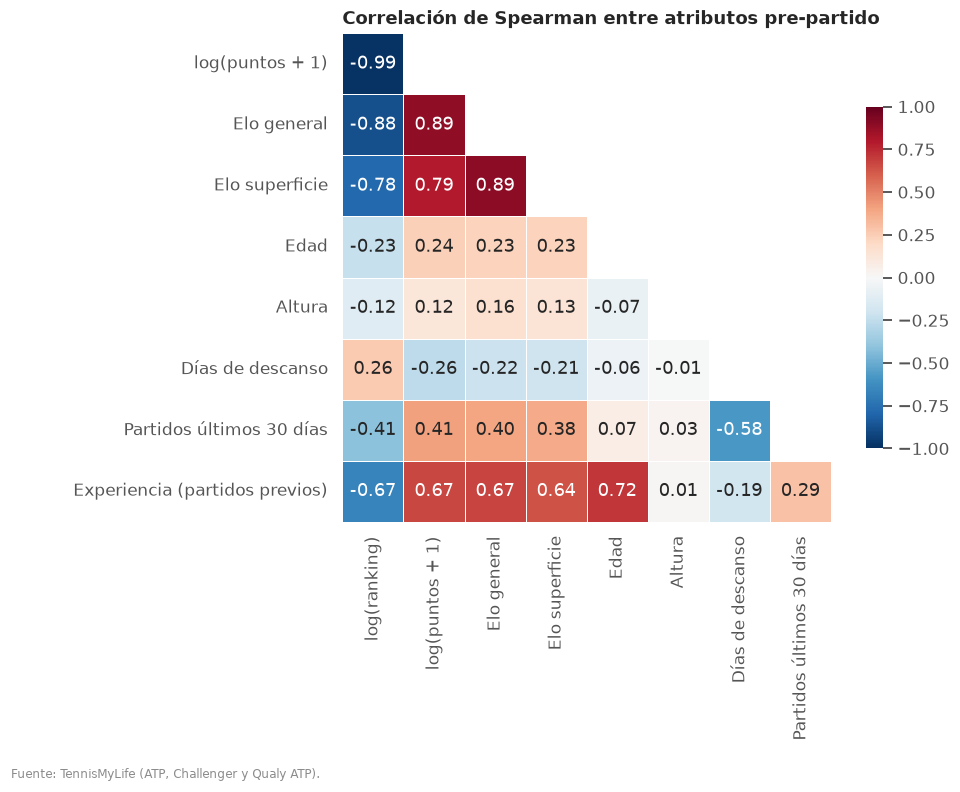

Pares con |rho| ≥ 0.70 (candidatos a redundancia):


,level_0,level_1,rho
0,log(puntos + 1),log(ranking),-0.988968
5,Elo superficie,Elo general,0.891254
2,Elo general,log(puntos + 1),0.887812
1,Elo general,log(ranking),-0.877125
4,Elo superficie,log(puntos + 1),0.789876
3,Elo superficie,log(ranking),-0.783702
32,Experiencia (partidos previos),Edad,0.717040


In [35]:
FEAT_JUG = {'log_rank': 'log(ranking)', 'log_puntos': 'log(puntos + 1)', 'elo': 'Elo general', 'elo_sup': 'Elo superficie',
            'age': 'Edad', 'ht': 'Altura', 'dias_descanso': 'Días de descanso', 'carga_30d': 'Partidos últimos 30 días',
            'n_previos': 'Experiencia (partidos previos)'}
m = lon.loc[lon.post_burnin, list(FEAT_JUG)].rename(columns=FEAT_JUG)
if len(m) > 300_000:
    m = m.sample(300_000, random_state=SEED)
corr = m.corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr.iloc[1:, :-1], mask=mask[1:, :-1], annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0, square=True,
            linewidths=.5, cbar_kws={'shrink': .7}, ax=ax)
ax.set_title('Correlación de Spearman entre atributos pre-partido'); ax.grid(False)
cerrar('18_correlacion_atributos')
pares_altos = corr.where(~mask).stack().rename('rho').reset_index()
pares_altos = pares_altos[pares_altos.rho.abs() >= .7].sort_values('rho', key=abs, ascending=False)
print('Pares con |rho| ≥ 0.70 (candidatos a redundancia):')
display(pares_altos)

### 8.2 Formato A vs. B: relación con el resultado y multicolinealidad

Cada partido se representa como jugador A vs. jugador B, con A asignado al azar: la variable objetivo queda balanceada y sin sesgo de posición. Los predictores son diferencias entre ambos jugadores. Se mide su asociación con el resultado y el VIF.

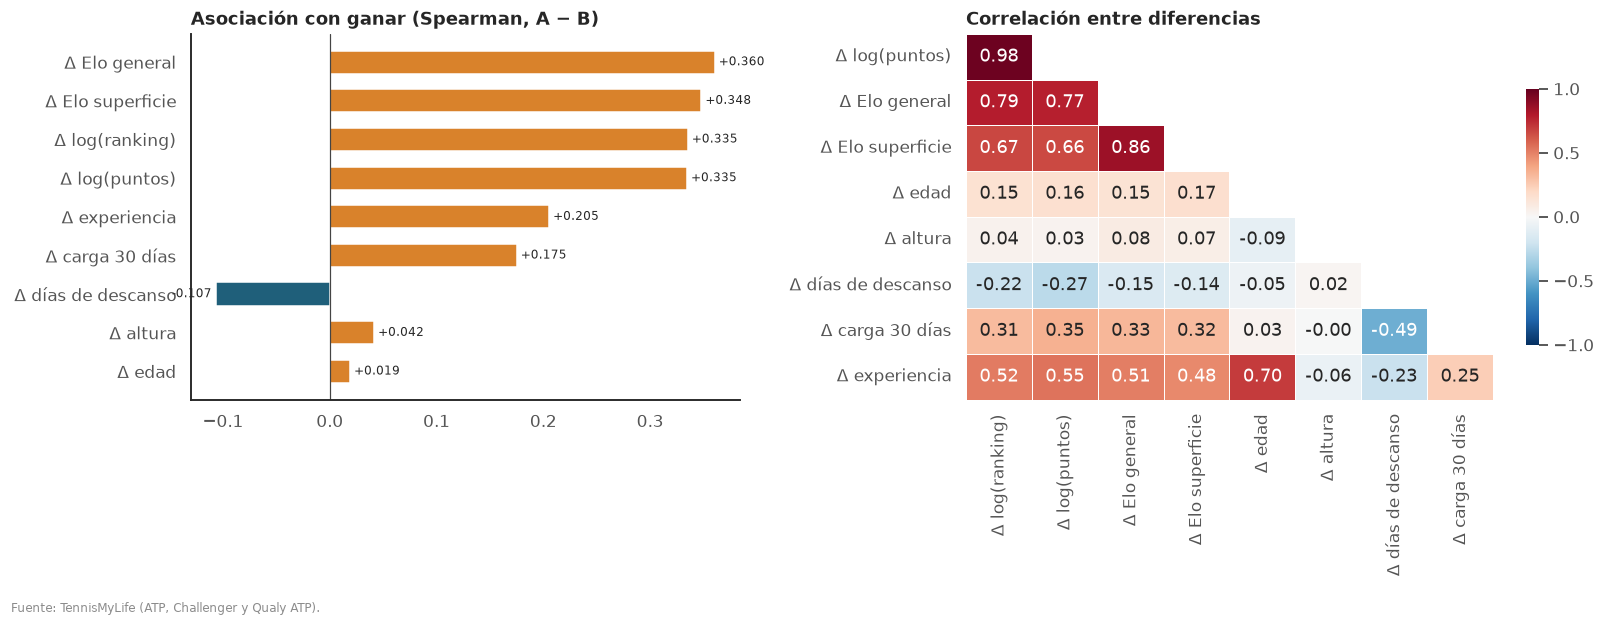

VIF calculado sobre 158,674 partidos con todas las variables disponibles:


variable,VIF,diagnóstico
Δ log(ranking),9.17,Colinealidad moderada
Δ log(puntos),8.65,Colinealidad moderada
Δ Elo general,6.01,Colinealidad moderada
Δ Elo superficie,3.94,Aceptable
Δ experiencia,3.58,Aceptable
Δ edad,2.38,Aceptable
Δ días de descanso,1.26,Aceptable
Δ carga 30 días,1.20,Aceptable
Δ altura,1.02,Aceptable


In [36]:
rng = np.random.default_rng(SEED)
m = df[df.anio > ANIO_BURNIN_FIN].reset_index(drop=True)
a_gana = rng.random(len(m)) < 0.5
ab = pd.DataFrame({'anio': m.anio.values, 'circuito': m.circuito.values, 'surface': m.surface.values, 'y': a_gana.astype(int)})
for v in ['rank', 'rank_points', 'elo', 'elo_sup', 'age', 'ht', 'dias_descanso', 'carga_30d', 'n_previos']:
    w, l = m[f'winner_{v}'].astype(float).values, m[f'loser_{v}'].astype(float).values
    ab[f'A_{v}'], ab[f'B_{v}'] = np.where(a_gana, w, l), np.where(a_gana, l, w)

ab['d_log_rank'] = np.log(ab.B_rank.fillna(RANK_CENTINELA)) - np.log(ab.A_rank.fillna(RANK_CENTINELA))
ab['d_log_puntos'] = np.log1p(ab.A_rank_points.fillna(0)) - np.log1p(ab.B_rank_points.fillna(0))
ab['d_elo'] = ab.A_elo - ab.B_elo
ab['d_elo_sup'] = ab.A_elo_sup - ab.B_elo_sup
ab['d_edad'] = ab.A_age - ab.B_age
ab['d_altura'] = ab.A_ht - ab.B_ht
ab['d_descanso'] = ab.A_dias_descanso - ab.B_dias_descanso
ab['d_carga'] = ab.A_carga_30d - ab.B_carga_30d
ab['d_experiencia'] = np.log1p(ab.A_n_previos) - np.log1p(ab.B_n_previos)
ab['en_poblacion'] = ab.A_rank.between(RANK_MIN, RANK_MAX) | ab.B_rank.between(RANK_MIN, RANK_MAX)

DIFS = {'d_log_rank': 'Δ log(ranking)', 'd_log_puntos': 'Δ log(puntos)', 'd_elo': 'Δ Elo general', 'd_elo_sup': 'Δ Elo superficie',
        'd_edad': 'Δ edad', 'd_altura': 'Δ altura', 'd_descanso': 'Δ días de descanso', 'd_carga': 'Δ carga 30 días',
        'd_experiencia': 'Δ experiencia'}
corr_y = ab[list(DIFS)].corrwith(ab.y, method='spearman').rename(DIFS).sort_values(key=abs)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1, 1.2]})
ax = axes[0]
ax.barh(corr_y.index, corr_y.values, color=[C_FOCO if v > 0 else C_PRINCIPAL for v in corr_y.values], height=.6)
for y, v in enumerate(corr_y.values):
    ax.text(v, y, f' {v:+.3f} ', va='center', ha='left' if v >= 0 else 'right', fontsize=8)
ax.axvline(0, color='#444', lw=.8); ax.grid(False)
ax.set_title('Asociación con ganar (Spearman, A − B)')
cd = ab[list(DIFS)].rename(columns=DIFS).corr(method='spearman')
mk = np.triu(np.ones_like(cd, dtype=bool))
sns.heatmap(cd.iloc[1:, :-1], mask=mk[1:, :-1], annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0, linewidths=.5,
            cbar_kws={'shrink': .7}, ax=axes[1])
axes[1].set_title('Correlación entre diferencias'); axes[1].grid(False)
cerrar('19_diferencias_vs_objetivo')

X = ab[list(DIFS)].dropna()
if len(X) > 200_000:
    X = X.sample(200_000, random_state=SEED)
if len(X) > len(DIFS) + 10:
    Xs = np.column_stack([np.ones(len(X)), StandardScaler().fit_transform(X)])
    vif = pd.DataFrame({'variable': [DIFS[c] for c in X.columns],
                        'VIF': [variance_inflation_factor(Xs, i + 1) for i in range(X.shape[1])]}).sort_values('VIF', ascending=False)
    vif['diagnóstico'] = np.select([vif.VIF >= 10, vif.VIF >= 5], ['Colinealidad severa', 'Colinealidad moderada'], 'Aceptable')
    print(f'VIF calculado sobre {len(X):,} partidos con todas las variables disponibles:')
    display(vif.style.hide(axis='index').format({'VIF': '{:.2f}'}))
else:
    vif = pd.DataFrame(columns=['variable', 'VIF', 'diagnóstico'])
    print('No hay suficientes casos completos para calcular el VIF.')

### 8.3 Estadísticas post-partido

No son predictores válidos, pero su estructura de correlación orienta cómo construir los promedios históricos de la notebook 02. El PCA se usa solo para cuantificar la redundancia.

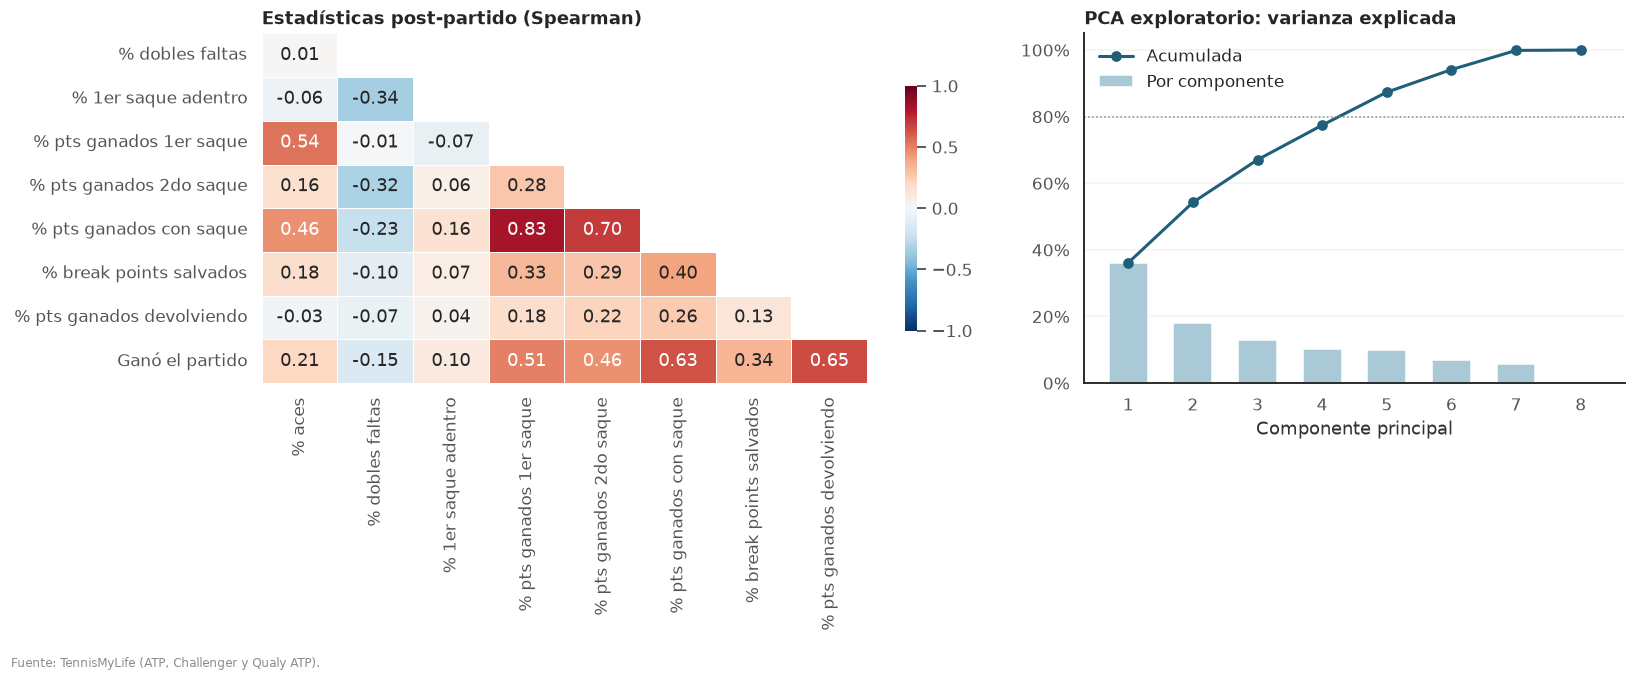

Con 5 de 8 componentes se explica el 87.3% de la varianza.


In [37]:
SERV = {'sv_ace_rate': '% aces', 'sv_df_rate': '% dobles faltas', 'sv_1st_in': '% 1er saque adentro',
        'sv_1st_won': '% pts ganados 1er saque', 'sv_2nd_won': '% pts ganados 2do saque', 'sv_pts_won': '% pts ganados con saque',
        'sv_bp_saved': '% break points salvados', 'ret_pts_won': '% pts ganados devolviendo', 'gano': 'Ganó el partido'}
e = lon.loc[lon.sv_svpt.ge(30), list(SERV)].dropna()
if len(e) > 300_000:
    e = e.sample(300_000, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.4, 1]})
ce = e.rename(columns=SERV).corr(method='spearman')
sns.heatmap(ce.iloc[1:, :-1], mask=np.triu(np.ones_like(ce, dtype=bool))[1:, :-1], annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            center=0, linewidths=.5, cbar_kws={'shrink': .7}, ax=axes[0])
axes[0].set_title('Estadísticas post-partido (Spearman)'); axes[0].grid(False)

vars_pca = [c for c in SERV if c != 'gano']
pca = PCA().fit(StandardScaler().fit_transform(e[vars_pca]))
var_acum = np.cumsum(pca.explained_variance_ratio_)
ax = axes[1]
ax.bar(range(1, len(vars_pca) + 1), pca.explained_variance_ratio_, color=C_SECUNDARIO, width=.6, label='Por componente')
ax.plot(range(1, len(vars_pca) + 1), var_acum, marker='o', color=C_PRINCIPAL, lw=2, label='Acumulada')
ax.axhline(.8, color=C_GRIS, ls=':', lw=1)
pct_axis(ax); ax.set_xlabel('Componente principal'); ax.set_title('PCA exploratorio: varianza explicada'); ax.legend()
cerrar('20_estadisticas_post_partido')
N_COMP_80 = int(np.argmax(var_acum >= .8) + 1)
print(f'Con {N_COMP_80} de {len(vars_pca)} componentes se explica el {var_acum[N_COMP_80 - 1]:.1%} de la varianza.')

### 8.4 Decisión: no se aplica reducción de dimensionalidad

1. **Explicabilidad:** el producto final es una recomendación de calendario que debe poder justificarse ante un jugador o su entrenador. Los componentes principales cortan la conexión con las variables originales.
2. **Pocas variables:** el número de predictores es moderado, así que no hay un problema de dimensionalidad que resolver.
3. **Modelos previstos:** XGBoost y LightGBM toleran la colinealidad. En la regresión logística se usará una variable por grupo redundante (Elo en lugar de ranking y puntos), según el VIF.

## 9. Señal predictiva preliminar, viabilidad y objetivos

Para evaluar la viabilidad se miden baselines simples en el test (2024–2026), con la misma partición temporal del modelado. Son el piso que el modelo de la notebook 02 deberá superar:

- **Ranking:** regresión logística sobre la diferencia de log(ranking), entrenada en 2007–2021.
- **Elo general** y **Elo general + superficie:** probabilidad directa de la fórmula, sin entrenamiento.
- **Elo recalibrado:** logística sobre las diferencias de Elo, para corregir la escala de sus probabilidades.

Además de AUC-ROC y Log-Loss (métricas planteadas al inicio del proyecto) se reportan el Brier score y la calibración, porque las probabilidades alimentarán la simulación de Monte Carlo de los cuadros.

In [38]:
ab['p_elo'] = 1 / (1 + 10 ** (-ab.d_elo / 400))
ab['p_elo_mix'] = 1 / (1 + 10 ** (-(0.5 * ab.d_elo + 0.5 * ab.d_elo_sup) / 400))
entrenamiento = ab[ab.anio.between(*TRAIN)]
test = ab[ab.anio.between(*TEST)].copy()
logit_rank = LogisticRegression().fit(entrenamiento[['d_log_rank']], entrenamiento.y)
test['p_rank'] = logit_rank.predict_proba(test[['d_log_rank']])[:, 1]
# Elo recalibrado: la fórmula del Elo no se ajusta a los datos; una logística sobre las diferencias corrige su escala
logit_elo = LogisticRegression().fit(entrenamiento[['d_elo', 'd_elo_sup']], entrenamiento.y)
test['p_elo_cal'] = logit_elo.predict_proba(test[['d_elo', 'd_elo_sup']])[:, 1]

def metricas(y, p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return {'AUC-ROC': roc_auc_score(y, p), 'Log-Loss': log_loss(y, p, labels=[0, 1]),
            'Brier': brier_score_loss(y, p), 'Accuracy': ((p > .5) == y).mean(), 'n': len(y)}

MODELOS = {'Ranking (logística)': 'p_rank', 'Elo general': 'p_elo', 'Elo general + superficie': 'p_elo_mix',
           'Elo recalibrado (logística)': 'p_elo_cal'}
SUBCONJUNTOS = {'Todos los partidos': test,
                f'Población objetivo (≥1 jugador {RANK_MIN}–{RANK_MAX})': test[test.en_poblacion],
                'ATP cuadro principal': test[test.circuito == 'ATP cuadro principal'],
                'Challenger': test[test.circuito == 'Challenger'],
                'Qualy ATP': test[test.circuito == 'Qualy ATP']}
filas = []
for nombre_sub, sub in SUBCONJUNTOS.items():
    if len(sub) < 50 or sub.y.nunique() < 2:
        continue
    for nombre_mod, col in MODELOS.items():
        filas.append({'subconjunto': nombre_sub, 'baseline': nombre_mod, **metricas(sub.y.values, sub[col].values)})
tabla_baselines = pd.DataFrame(filas)
print(f'Test: temporadas {TEST[0]}–{TEST[1]} | Objetivos iniciales: AUC-ROC > 0.72 y Log-Loss < 0.60')
display(tabla_baselines.style.hide(axis='index')
        .format({'AUC-ROC': '{:.3f}', 'Log-Loss': '{:.3f}', 'Brier': '{:.3f}', 'Accuracy': '{:.1%}', 'n': '{:,}'})
        .background_gradient(subset=['AUC-ROC'], cmap='Greens'))

Test: temporadas 2024–2026 | Objetivos iniciales: AUC-ROC > 0.72 y Log-Loss < 0.60


subconjunto,baseline,AUC-ROC,Log-Loss,Brier,Accuracy,n
Todos los partidos,Ranking (logística),0.667,0.650,0.229,62.1%,"30,338"
Todos los partidos,Elo general,0.683,0.646,0.226,63.2%,"30,338"
Todos los partidos,Elo general + superficie,0.687,0.641,0.225,63.6%,"30,338"
Todos los partidos,Elo recalibrado (logística),0.688,0.638,0.224,63.6%,"30,338"
Población objetivo (≥1 jugador 100–300),Ranking (logística),0.660,0.654,0.231,61.9%,"20,211"
Población objetivo (≥1 jugador 100–300),Elo general,0.680,0.650,0.228,62.9%,"20,211"
Población objetivo (≥1 jugador 100–300),Elo general + superficie,0.685,0.644,0.226,63.5%,"20,211"
Población objetivo (≥1 jugador 100–300),Elo recalibrado (logística),0.685,0.641,0.225,63.6%,"20,211"
ATP cuadro principal,Ranking (logística),0.695,0.640,0.224,63.9%,"7,844"
ATP cuadro principal,Elo general,0.713,0.623,0.217,65.2%,"7,844"


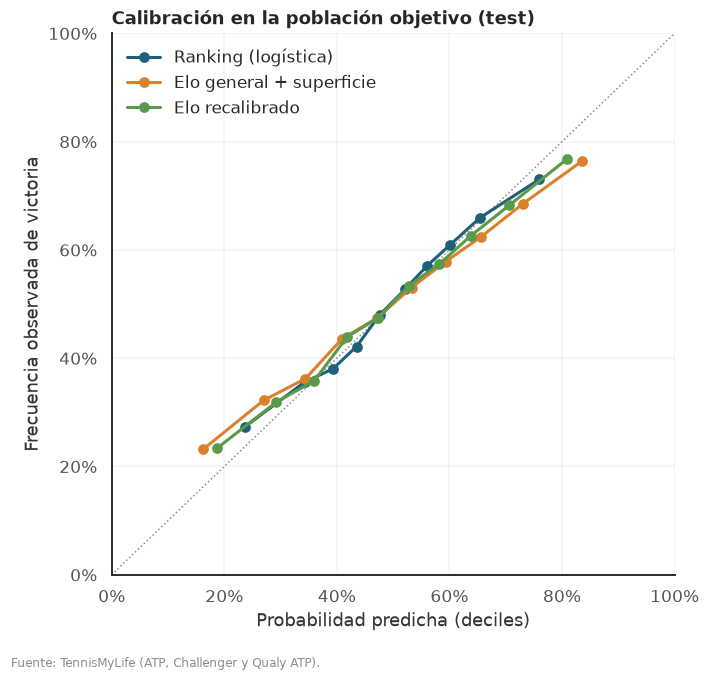

Pendiente de calibración del Elo general + superficie: 0.74 (1 = calibrado; < 1 = probabilidades demasiado extremas, sobreconfianza; > 1 = demasiado conservadoras)


In [39]:
sub = test[test.en_poblacion]
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], color=C_GRIS, ls=':', lw=1)
for col, nombre, color in [('p_rank', 'Ranking (logística)', C_PRINCIPAL), ('p_elo_mix', 'Elo general + superficie', C_FOCO),
                          ('p_elo_cal', 'Elo recalibrado', '#5b9a4b')]:
    if len(sub) >= 100:
        q = pd.qcut(sub[col], 10, duplicates='drop')
        cal = sub.groupby(q, observed=True).agg(pred=(col, 'mean'), obs=('y', 'mean'))
        ax.plot(cal.pred, cal.obs, marker='o', lw=2, color=color, label=nombre)
pct_axis(ax, 'x'); pct_axis(ax, 'y'); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(True, axis='both', alpha=.25)
ax.set_xlabel('Probabilidad predicha (deciles)'); ax.set_ylabel('Frecuencia observada de victoria')
ax.set_title('Calibración en la población objetivo (test)'); ax.legend(loc='upper left')
cerrar('21_calibracion_baselines')

def pendiente_calibracion(y, p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return LogisticRegression(C=1e6).fit(np.log(p / (1 - p)).reshape(-1, 1), y).coef_[0][0]
PEND_CAL = pendiente_calibracion(sub.y.values, sub.p_elo_mix.values) if len(sub) >= 100 else np.nan
print(f'Pendiente de calibración del Elo general + superficie: {PEND_CAL:.2f} '
      '(1 = calibrado; < 1 = probabilidades demasiado extremas, sobreconfianza; > 1 = demasiado conservadoras)')

In [40]:
ultimas6 = lon[lon.en_poblacion & lon.anio.between(ANIO_FIN - 5, ANIO_FIN)]
N_ARG_RECIENTES = int(ultimas6.loc[ultimas6.es_arg, 'id'].nunique())
N_POBLACION = int((lon.en_poblacion & lon.post_burnin).sum())

def valor_baseline(modelo, metrica, prefijo='Población'):
    f = tabla_baselines[tabla_baselines.subconjunto.str.startswith(prefijo) & (tabla_baselines.baseline == modelo)]
    return float(f[metrica].iloc[0]) if len(f) else np.nan

AUC_POB = valor_baseline('Elo general + superficie', 'AUC-ROC')
LL_POB = valor_baseline('Elo general + superficie', 'Log-Loss')
AUC_RANK_POB = valor_baseline('Ranking (logística)', 'AUC-ROC')
cob_ch = COBERTURA_DESDE.get('Challenger')

checks = pd.DataFrame([
    [f'Volumen de la población objetivo (jugador-partido, {ANIO_BURNIN_FIN + 1} en adelante)', f'{N_POBLACION:,}', N_POBLACION >= 50_000, True],
    [f'Jugadores argentinos distintos en la población ({ANIO_FIN - 5}–{ANIO_FIN})', N_ARG_RECIENTES, N_ARG_RECIENTES >= 10, True],
    ['Señal predictiva del baseline Elo en la población (AUC test)', f'{AUC_POB:.3f}', bool(AUC_POB >= 0.65), True],
    ['Estadísticas de saque en Challenger con cobertura ≥80% desde', cob_ch if cob_ch else 'no alcanza', bool(cob_ch and cob_ch <= 2015), False],
    ['Región geográfica del torneo disponible en la base', 'No', False, False],
    ['Categoría del Challenger (50/75/100/125/175) disponible en la base', 'No', False, False],
], columns=['criterio', 'valor', 'cumple', 'crítico'])
checks['estado'] = np.where(checks.cumple, 'OK', np.where(checks['crítico'], 'NO CUMPLE', 'Requiere enriquecimiento'))
display(checks.drop(columns='cumple').style.hide(axis='index').set_properties(**{'text-align': 'left'}))
DECISION_GO = bool(checks.loc[checks['crítico'], 'cumple'].all())
print('Viabilidad del proyecto:', 'viable, continúa con ajustes' if DECISION_GO else 'REVISAR — algún criterio crítico no se cumple')

criterio,valor,crítico,estado
"Volumen de la población objetivo (jugador-partido, 2007 en adelante)","172,256",True,OK
Jugadores argentinos distintos en la población (2021–2026),35,True,OK
Señal predictiva del baseline Elo en la población (AUC test),0.685,True,OK
Estadísticas de saque en Challenger con cobertura ≥80% desde,2010,False,OK
Región geográfica del torneo disponible en la base,No,False,Requiere enriquecimiento
Categoría del Challenger (50/75/100/125/175) disponible en la base,No,False,Requiere enriquecimiento


Viabilidad del proyecto: viable, continúa con ajustes


### 9.1 Reformulación de los objetivos de desempeño

Al plantear el proyecto se fijaron dos umbrales absolutos para el modelo de probabilidad de victoria: AUC-ROC > 0.72 y Log-Loss < 0.60. El EDA muestra que no son una vara adecuada para este problema, por tres razones:

1. **Dependen de la mezcla de partidos más que del modelo.** El mismo baseline Elo logra un AUC de 0.717 en cuadros principales ATP y de 0.670 en Challenger, donde los niveles son más parejos. Como dos tercios de los partidos de la población son Challengers, un umbral absoluto mide sobre todo la composición de la muestra.
2. **Equivalen al techo publicado para el circuito principal.** Kovalchik (2016) comparó once modelos en los partidos ATP de 2014. El mejor (Elo) logró un 70% de acierto y un Log-Loss de 0.59, y ninguno superó a las casas de apuestas (72% y 0.55). Además, todos los modelos fueron menos precisos con jugadores de ranking bajo, que son justamente la población de este proyecto.
3. **El uso del modelo exige calibración antes que discriminación.** Las probabilidades alimentan una simulación de Monte Carlo ronda por ronda, donde los errores de escala se acumulan. El Elo discrimina razonablemente, pero sus probabilidades son demasiado extremas (pendiente de calibración < 1), así que la mejora relevante está en el Log-Loss, el Brier score y la calibración.

Por eso los objetivos se reformulan como **mejora sobre el baseline Elo recalibrado**, medida en el mismo conjunto de test (2024–2026) y en la población objetivo. Los umbrales iniciales se siguen reportando como referencia.

*Referencia:* Kovalchik, S. A. (2016). Searching for the GOAT of tennis win prediction. *Journal of Quantitative Analysis in Sports, 12*(3), 127–138. https://doi.org/10.1515/jqas-2015-0059

In [41]:
# 9.1 Objetivos de desempeño: planteo inicial y reformulación

LL_CAL_POB = valor_baseline('Elo recalibrado (logística)', 'Log-Loss')
BRIER_CAL_POB = valor_baseline('Elo recalibrado (logística)', 'Brier')
AUC_CAL_POB = valor_baseline('Elo recalibrado (logística)', 'AUC-ROC')

objetivos = pd.DataFrame([
    ['Log-Loss', '< 0.60', f'{LL_CAL_POB:.3f}',
     'Menor que el baseline, con IC 95% bootstrap de la diferencia por debajo de 0', 'Principal'],
    ['Brier score', '—', f'{BRIER_CAL_POB:.3f}', 'Menor que el baseline', 'Principal'],
    ['Pendiente de calibración', '—', f'{PEND_CAL:.2f} (Elo sin recalibrar)', 'Entre 0.90 y 1.10', 'Principal'],
    ['AUC-ROC', '> 0.72', f'{AUC_CAL_POB:.3f}', 'Igual o mayor que el baseline', 'Secundaria'],
], columns=['métrica', 'objetivo inicial', 'baseline Elo recalibrado (test, población)',
            'objetivo reformulado', 'prioridad'])
display(objetivos.style.hide(axis='index').format(escape='html').set_properties(**{'text-align': 'left'}))

métrica,objetivo inicial,"baseline Elo recalibrado (test, población)",objetivo reformulado,prioridad
Log-Loss,< 0.60,0.641,"Menor que el baseline, con IC 95% bootstrap de la diferencia por debajo de 0",Principal
Brier score,—,0.225,Menor que el baseline,Principal
Pendiente de calibración,—,0.74 (Elo sin recalibrar),Entre 0.90 y 1.10,Principal
AUC-ROC,> 0.72,0.685,Igual o mayor que el baseline,Secundaria


## 10. Conclusiones del EDA


In [42]:
# @title Conclusiones { display-mode: "form" }
def pct(x):
    return f'{x:.1%}' if pd.notna(x) else 's/d'

def pp(x):
    return f'{x:+.1%}' if pd.notna(x) else 's/d'

def fila_get(tabla, idx, col):
    try:
        return tabla.loc[idx, col]
    except (KeyError, TypeError):
        return np.nan

mix_pob = lon[lon.en_poblacion & lon.post_burnin].circuito.value_counts(normalize=True)
falta_stats = df.groupby('circuito').w_svpt.apply(lambda s: s.isna().mean())
falta_indoor = df.groupby('circuito')['indoor'].apply(lambda s: s.isna().mean())
AUC_ATP = valor_baseline('Elo general + superficie', 'AUC-ROC', 'ATP cuadro principal')
AUC_CH = valor_baseline('Elo general + superficie', 'AUC-ROC', 'Challenger')
LL_CAL = valor_baseline('Elo recalibrado (logística)', 'Log-Loss')
txt = []

# 1. Volumen y composición
txt.append(f"**1. Volumen y composición.** Tras la depuración, la base analítica contiene **{len(df):,} partidos** "
           f"({df.anio.min()}–{df.anio.max()}) y **{lon.id.nunique():,} jugadores**. En la población objetivo "
           f"(ranking {RANK_MIN}–{RANK_MAX}, desde {ANIO_BURNIN_FIN + 1}) hay **{N_POBLACION:,} registros jugador-partido**: "
           f"el {pct(mix_pob.get('Challenger'))} corresponde a Challenger, el {pct(mix_pob.get('Qualy ATP'))} a clasificaciones "
           f"ATP y solo el {pct(mix_pob.get('ATP cuadro principal'))} a cuadros principales ATP. El Challenger es el escenario "
           f"central del problema, lo que confirma la decisión de incorporarlo. La temporada 2020 es atípica (calendario "
           f"interrumpido por la pandemia y ranking ATP congelado), por lo que las variables de ranking de 2020–2021 deben "
           f"leerse con cautela; el Elo no tiene ese problema.")

# 2. Perfil de superficie
clay_pob = fila_get(sup_tramo, '101–300', 'Clay'); clay_top = fila_get(sup_tramo, '1–100', 'Clay')
clay_arg = fila_get(mix_arg, 'Argentinos', 'Clay'); clay_resto = fila_get(mix_arg, 'Resto', 'Clay')
txt.append(f"**2. Perfil de superficie.** Los jugadores 101–300 juegan el {pct(clay_pob)} de sus partidos en polvo de "
           f"ladrillo, contra el {pct(clay_top)} del top 100. Los argentinos de la población llevan esto al extremo: "
           f"**{pct(clay_arg)} en polvo** frente al {pct(clay_resto)} del resto. El calendario argentino real ya se parece a la "
           f"heurística de referencia (\"polvo, máxima categoría, región cercana\"), así que la pregunta del proyecto "
           f"no es si jugar en polvo, sino **si esa concentración es óptima** o si deja puntos sobre la mesa.")

# 3. Calidad del dato
prop = {v: (antes[v], despues[v]) for v in ['hand', 'ht', 'age']}
txt.append(f"**3. Calidad del dato.** Las estadísticas de saque faltan en el {pct(falta_stats.get('ATP cuadro principal'))} de los "
           f"partidos ATP, el {pct(falta_stats.get('Challenger'))} de los Challenger y el {pct(falta_stats.get('Qualy ATP'))} de "
           f"las qualys; la ausencia depende de la temporada y del circuito (MAR) y en Challenger la cobertura supera el 80% "
           f"desde **{COBERTURA_DESDE.get('Challenger') or 'ningún año'}**. La variable *indoor* falta en el "
           f"{pct(falta_indoor.get('Challenger'))} de los Challenger"
           + (": sin enriquecimiento externo no es utilizable. " if falta_indoor.get('Challenger', 0) > .5 else ". ")
           + f"El ranking "
           f"faltante es MNAR: cuando el mismo jugador tiene ranking en otro torneo del año, su mediana es {RANK_REF_MED:,.0f} "
           f"(contra {RANK_MED_GRAL:,.0f} general), y el {pct(1 - RANK_REF_PCT)} no tiene ranking en toda la temporada. "
           f"La propagación intra-jugador tuvo un efecto marginal (altura {pct(prop['ht'][0])} → {pct(prop['ht'][1])}): "
           f"los faltantes biográficos se concentran en jugadores que **nunca** tienen el dato, jugadores con pocos partidos. "
           f"La forma de ingreso solo es utilizable en: {', '.join(CIRC_CON_ENTRY) or 'ningún circuito'}.")

# 4. Outliers
top3 = ', '.join(top_sacadores.reset_index().name.head(3).astype(str))
txt.append(f"**4. Outliers.** Se anularon {N_BLOQUES_INVALIDOS:,} bloques de estadísticas con inconsistencias lógicas. La revisión "
           f"manual de los partidos más largos detectó duraciones imposibles para partidos a 3 sets (más de 500 minutos), lo que "
           f"llevó a validar la duración según el formato. Los extremos reales se conservan: partidos a 5 sets y grandes "
           f"sacadores (los mayores porcentajes de aces son de {top3}, todos jugadores reconocidos por su saque, lo que valida "
           f"el dato).")

# 5. Señal predictiva y calibración
t = (f"**5. Señal predictiva.** En la población objetivo (test {TEST[0]}–{TEST[1]}), el baseline Elo general + superficie "
     f"alcanza un AUC-ROC de **{AUC_POB:.3f}** y un Log-Loss de **{LL_POB:.3f}** (ranking ATP: AUC {AUC_RANK_POB:.3f}). "
     + (f"La señal es mayor en cuadros principales ATP (AUC {AUC_ATP:.3f}) que en Challenger ({AUC_CH:.3f}), donde los "
        f"niveles son más parejos. " if AUC_ATP > AUC_CH else
        f"AUC en cuadros principales ATP: {AUC_ATP:.3f}; en Challenger: {AUC_CH:.3f}. "))
if pd.notna(PEND_CAL):
    if PEND_CAL < 0.95:
        t += (f"La pendiente de calibración del Elo es {PEND_CAL:.2f}: sus probabilidades son **demasiado extremas**, un "
              f"problema crítico para la simulación de Monte Carlo. Recalibrarlo con una logística baja el Log-Loss a "
              f"**{LL_CAL:.3f}**. ")
    elif PEND_CAL > 1.05:
        t += f"La pendiente de calibración del Elo es {PEND_CAL:.2f}: sus probabilidades son demasiado conservadoras. "
    else:
        t += f"El Elo está bien calibrado (pendiente {PEND_CAL:.2f}). "
brecha_auc, brecha_ll = 0.72 - AUC_POB, LL_POB - 0.60
if AUC_POB > 0.72 and LL_POB < 0.60:
    t += "Un baseline de una sola variable ya cumple los umbrales iniciales: los objetivos se redefinen como mejora sobre el baseline (sección 9.1)."
else:
    t += (f"Frente a los umbrales iniciales faltan **{brecha_auc:+.3f} de AUC** y **{-brecha_ll:+.3f} de "
          f"Log-Loss**. Esos umbrales equivalen al techo publicado para el circuito principal y no contemplan una población "
          f"que juega sobre todo Challengers, por lo que los objetivos se reformulan como **mejora sobre el baseline Elo "
          f"recalibrado**, con prioridad en Log-Loss, Brier y calibración (sección 9.1).")
txt.append(t)

# 6. Afinidad por superficie
if tests_afinidad:
    partes = []
    for sup in ['Clay', 'Hard', 'Grass']:
        if sup in tests_afinidad:
            ta = tests_afinidad[sup]
            partes.append(f"{NOMBRE_SUP[sup].lower()} {pp(ta['ARG'])} (resto {pp(ta['Resto'])}, p = {ta['p_valor']:.2g}, n = {ta['n_ARG']:,.0f})")
    especialistas = ('Clay' in tests_afinidad and 'Hard' in tests_afinidad
                     and tests_afinidad['Clay']['ARG'] > tests_afinidad['Clay']['Resto']
                     and tests_afinidad['Hard']['ARG'] < tests_afinidad['Hard']['Resto'])
    txt.append("**6. Afinidad por superficie.** Rendimiento de los argentinos de la población respecto de lo que predice su "
               "Elo general: " + '; '.join(partes) + ". "
               + ("Los argentinos son **especialistas en polvo de ladrillo**: rinden por encima de lo esperado en su "
                  "superficie y por debajo en superficies rápidas. Como su Elo general se construye sobre todo con partidos "
                  "en polvo, **sobreestima su nivel en cemento y césped**. Esto confirma que el Elo por superficie es "
                  "indispensable y sugiere optimizar su ponderación en el modelado. " if especialistas else
                  "El patrón no es concluyente a nivel de nacionalidad; la afinidad se modelará a nivel individual con el "
                  "Elo por superficie. ")
               + "(Los p-valores son optimistas porque los partidos de un mismo jugador no son independientes.)")

# 7. Contexto competitivo
lineas = []
if len(rend_descanso):
    lineas.append(f"la **inactividad penaliza**: tras más de 4 meses sin jugar, el rendimiento cae "
                  f"{pp(fila_get(rend_descanso, '> 4 meses', 'media'))} respecto del Elo, y quien jugó la semana anterior "
                  f"rinde {pp(fila_get(rend_descanso, '1 sem.', 'media'))}")
if len(rend_carga):
    c10, c0 = fila_get(rend_carga, '10+', 'media'), fila_get(rend_carga, '0', 'media')
    lineas.append((f"no se observa fatiga por carga alta (10+ partidos en 30 días: {pp(c10)})" if c10 >= 0 else
                   f"la carga alta se asocia a un rendimiento menor (10+ partidos en 30 días: {pp(c10)})")
                  + f"; sin partidos en los 30 días previos el rendimiento es {pp(c0)}")
if len(rend_edad):
    e_joven, e_mayor = fila_get(rend_edad, '20–22', 'media'), fila_get(rend_edad, '32+', 'media')
    lineas.append((f"el Elo **no captura la trayectoria de edad**: " if e_joven > 0 > e_mayor else "por edad: ")
                  + f"los jugadores de 20–22 años rinden {pp(e_joven)} y los de 32+ {pp(e_mayor)}")
if len(rend_entrada) and 'Clasificado' in rend_entrada.index:
    q_, wc_ = rend_entrada.loc['Clasificado', 'media'], fila_get(rend_entrada, 'Wild card', 'media')
    lineas.append(f"los clasificados rinden {pp(q_)}" + (" (llegan en ritmo)" if q_ > 0 else "")
                  + f" y los wild cards {pp(wc_)}" + (" (probable efecto localía)" if wc_ > 0 else ""))
if lineas:
    txt.append("**7. Contexto competitivo.** Midiendo contra el Elo: " + '; '.join(lineas) + ". Son señales que el Elo no "
               "incorpora y que justifican sumar al modelo inactividad, forma reciente, edad y forma de ingreso. Esto es "
               "relevante para la recomendación de calendario: el orden y la densidad de los torneos afectan el rendimiento.")

# 8. Colinealidad
sev = vif[vif['diagnóstico'] != 'Aceptable'].variable.tolist() if len(vif) else []
txt.append("**8. Colinealidad.** " + (f"VIF entre 5 y 10 (colinealidad moderada) en: {', '.join(sev)}. " if sev else
           "No se detecta colinealidad relevante entre las diferencias. ")
           + "Ranking y puntos son prácticamente la misma variable (rho ≈ −0.99), y ambos están muy asociados al Elo: miden "
           "el mismo constructo, el nivel del jugador. En modelos lineales se conservará el Elo y se descartará log(puntos); "
           "los modelos de árboles toleran la redundancia. No se aplica reducción de dimensionalidad, para preservar la "
           "explicabilidad de la recomendación.")

# 9. Viabilidad
txt.append(f"**9. Viabilidad: {'el proyecto es viable y continúa' if DECISION_GO else 'REVISAR el planteo'}**, con estos "
           f"ajustes para el modelado: (a) enriquecer la base con la **región geográfica** de cada torneo y la **categoría "
           f"de los Challenger**, que no están en la fuente (sección 13); (b) usar las estadísticas de saque como promedios "
           f"históricos solo desde las temporadas con cobertura; (c) incorporar inactividad, forma reciente y edad; (d) "
           f"evaluar contra los objetivos reformulados: mejora sobre el baseline Elo recalibrado en Log-Loss, Brier y "
           f"calibración (sección 9.1).")
display(Markdown('\n\n'.join(txt)))

**1. Volumen y composición.** Tras la depuración, la base analítica contiene **223,190 partidos** (2000–2026) y **5,955 jugadores**. En la población objetivo (ranking 100–300, desde 2007) hay **172,256 registros jugador-partido**: el 67.2% corresponde a Challenger, el 21.8% a clasificaciones ATP y solo el 11.0% a cuadros principales ATP. El Challenger es el escenario central del problema, lo que confirma la decisión de incorporarlo. La temporada 2020 es atípica (calendario interrumpido por la pandemia y ranking ATP congelado), por lo que las variables de ranking de 2020–2021 deben leerse con cautela; el Elo no tiene ese problema.

**2. Perfil de superficie.** Los jugadores 101–300 juegan el 45.0% de sus partidos en polvo de ladrillo, contra el 33.7% del top 100. Los argentinos de la población llevan esto al extremo: **84.1% en polvo** frente al 41.7% del resto. El calendario argentino real ya se parece a la heurística de referencia ("polvo, máxima categoría, región cercana"), así que la pregunta del proyecto no es si jugar en polvo, sino **si esa concentración es óptima** o si deja puntos sobre la mesa.

**3. Calidad del dato.** Las estadísticas de saque faltan en el 0.6% de los partidos ATP, el 35.3% de los Challenger y el 4.9% de las qualys; la ausencia depende de la temporada y del circuito (MAR) y en Challenger la cobertura supera el 80% desde **2010**. La variable *indoor* falta en el 89.4% de los Challenger: sin enriquecimiento externo no es utilizable. El ranking faltante es MNAR: cuando el mismo jugador tiene ranking en otro torneo del año, su mediana es 484 (contra 161 general), y el 76.9% no tiene ranking en toda la temporada. La propagación intra-jugador tuvo un efecto marginal (altura 5.2% → 5.0%): los faltantes biográficos se concentran en jugadores que **nunca** tienen el dato, jugadores con pocos partidos. La forma de ingreso solo es utilizable en: ATP cuadro principal.

**4. Outliers.** Se anularon 36 bloques de estadísticas con inconsistencias lógicas. La revisión manual de los partidos más largos detectó duraciones imposibles para partidos a 3 sets (más de 500 minutos), lo que llevó a validar la duración según el formato. Los extremos reales se conservan: partidos a 5 sets y grandes sacadores (los mayores porcentajes de aces son de Ivo Karlovic, Reilly Opelka, John Isner, todos jugadores reconocidos por su saque, lo que valida el dato).

**5. Señal predictiva.** En la población objetivo (test 2024–2026), el baseline Elo general + superficie alcanza un AUC-ROC de **0.685** y un Log-Loss de **0.644** (ranking ATP: AUC 0.660). La señal es mayor en cuadros principales ATP (AUC 0.717) que en Challenger (0.670), donde los niveles son más parejos. La pendiente de calibración del Elo es 0.74: sus probabilidades son **demasiado extremas**, un problema crítico para la simulación de Monte Carlo. Recalibrarlo con una logística baja el Log-Loss a **0.641**. Frente a los umbrales iniciales faltan **+0.035 de AUC** y **-0.044 de Log-Loss**. Esos umbrales equivalen al techo publicado para el circuito principal y no contemplan una población que juega sobre todo Challengers, por lo que los objetivos se reformulan como **mejora sobre el baseline Elo recalibrado**, con prioridad en Log-Loss, Brier y calibración (sección 9.1).

**6. Afinidad por superficie.** Rendimiento de los argentinos de la población respecto de lo que predice su Elo general: polvo de ladrillo +2.2% (resto -0.2%, p = 1.3e-06, n = 9,837); cemento -6.0% (resto +0.7%, p = 1.8e-08, n = 1,618); césped -18.3% (resto +1.3%, p = 7e-10, n = 228). Los argentinos son **especialistas en polvo de ladrillo**: rinden por encima de lo esperado en su superficie y por debajo en superficies rápidas. Como su Elo general se construye sobre todo con partidos en polvo, **sobreestima su nivel en cemento y césped**. Esto confirma que el Elo por superficie es indispensable y sugiere optimizar su ponderación en el modelado. (Los p-valores son optimistas porque los partidos de un mismo jugador no son independientes.)

**7. Contexto competitivo.** Midiendo contra el Elo: la **inactividad penaliza**: tras más de 4 meses sin jugar, el rendimiento cae -2.7% respecto del Elo, y quien jugó la semana anterior rinde +1.3%; no se observa fatiga por carga alta (10+ partidos en 30 días: +1.0%); sin partidos en los 30 días previos el rendimiento es -2.8%; el Elo **no captura la trayectoria de edad**: los jugadores de 20–22 años rinden +2.1% y los de 32+ -4.1%; los clasificados rinden +5.1% (llegan en ritmo) y los wild cards +3.4% (probable efecto localía). Son señales que el Elo no incorpora y que justifican sumar al modelo inactividad, forma reciente, edad y forma de ingreso. Esto es relevante para la recomendación de calendario: el orden y la densidad de los torneos afectan el rendimiento.

**8. Colinealidad.** VIF entre 5 y 10 (colinealidad moderada) en: Δ log(ranking), Δ log(puntos), Δ Elo general. Ranking y puntos son prácticamente la misma variable (rho ≈ −0.99), y ambos están muy asociados al Elo: miden el mismo constructo, el nivel del jugador. En modelos lineales se conservará el Elo y se descartará log(puntos); los modelos de árboles toleran la redundancia. No se aplica reducción de dimensionalidad, para preservar la explicabilidad de la recomendación.

**9. Viabilidad: el proyecto es viable y continúa**, con estos ajustes para el modelado: (a) enriquecer la base con la **región geográfica** de cada torneo y la **categoría de los Challenger**, que no están en la fuente (sección 13); (b) usar las estadísticas de saque como promedios históricos solo desde las temporadas con cobertura; (c) incorporar inactividad, forma reciente y edad; (d) evaluar contra los objetivos reformulados: mejora sobre el baseline Elo recalibrado en Log-Loss, Brier y calibración (sección 9.1).

### Implicancias para el modelado (notebook 02)

- **Variable objetivo y formato:** probabilidad de victoria en formato A vs. B con asignación aleatoria; partición temporal 2007–2021 / 2022–2023 / 2024–2026.
- **Atributos pre-partido a construir:** Elo general y por superficie (con ponderación optimizada y penalización por inactividad), diferencias de ranking y puntos (log), forma reciente (Elo de las últimas semanas), promedios históricos de saque y devolución con ventana y mínimo de partidos, descanso, carga, forma de ingreso, edad, altura y mano (con indicadores de faltante).
- **Enriquecimiento externo:** región y país de cada torneo, categoría de los Challenger y tabla de puntos ATP por ronda, necesarios para pasar de probabilidad de victoria a puntos esperados. Se incorporan en la sección 13.
- **Evaluación:** AUC-ROC, Log-Loss, Brier y curva de calibración, contra el baseline Elo recalibrado y los objetivos de la sección 9.1.
- **Limpieza previa al modelado:** unificar qualy y cuadro principal como un único evento para calcular el descanso, y acotar los descansos extremos (hay pausas de varios años).

## 11. Diccionario de datos

Variables originales y derivadas, con tipo, descripción, dominio, rol, porcentaje de faltantes (sobre la base depurada) y tratamiento aplicado. Se exporta a CSV y Excel.

In [43]:
# @title Construcción del diccionario de datos { display-mode: "form" }
PRE, POST, ID, OBJ, SEG = 'Atributo pre-partido', 'Post-partido (riesgo de fuga)', 'Identificador', 'Variable objetivo', 'Segmentación / filtro'
D = [
    # variable, clave, origen, tipo, descripción, dominio, rol, tratamiento
    ('tourney_id', 'tourney_id', 'Original', 'texto', 'Identificador del torneo (base ATP)', 'Código', ID, '—'),
    ('tourney_name', 'tourney_name', 'Original', 'texto', 'Ciudad o nombre del torneo', 'Texto libre', 'Contexto', 'Se vincula por id_atp con la tabla de torneos (sección 13)'),
    ('surface', 'surface', 'Original', 'categórica', 'Superficie de juego', 'Hard, Clay, Grass, Carpet', PRE, 'Normalizada; Carpet se agrupa con Hard para el Elo'),
    ('draw_size', 'draw_size', 'Original', 'entera', 'Tamaño del cuadro', '4 a 128', PRE, '—'),
    ('tourney_level', 'tourney_level', 'Original', 'categórica', 'Nivel del torneo', 'G, M, A, F, D, C...', PRE, 'Copa Davis (D) excluida'),
    ('indoor', 'indoor', 'Original', 'categórica', 'Torneo bajo techo o al aire libre', 'Indoor, Outdoor', PRE, 'Normalizada; para la simulación se toma del calendario ATP 2026 (sección 13)'),
    ('tourney_date', 'tourney_date', 'Original', 'fecha', 'Semana de inicio del torneo', '2000–2026', PRE, 'Convertida a fecha'),
    ('match_num', 'match_num', 'Original', 'entera', 'Número de partido dentro del torneo', '≥ 1', ID, '—'),
    ('winner_id / loser_id', 'id', 'Original', 'texto', 'ID ATP del jugador', 'Código ATP', ID, '—'),
    ('winner_name / loser_name', 'name', 'Original', 'texto', 'Nombre del jugador', 'Texto', ID, '—'),
    ('winner_seed / loser_seed', 'seed', 'Original', 'entera', 'Cabeza de serie', '1 a 32 o vacío', PRE, 'Faltante estructural → indicador es_cabeza_serie'),
    ('winner_entry / loser_entry', 'entry', 'Original', 'categórica', 'Forma de ingreso al cuadro', 'Q, WC, LL, PR, SE, ALT o vacío', PRE, 'Vacío → "Directa"; subregistrado en algunos circuitos'),
    ('winner_hand / loser_hand', 'hand', 'Original', 'categórica', 'Mano hábil', 'R, L', PRE, '"U" → faltante; propagación intra-jugador'),
    ('winner_ht / loser_ht', 'ht', 'Original', 'numérica', 'Altura', 'cm (155–215)', PRE, 'Valores imposibles → faltante; propagación intra-jugador'),
    ('winner_ioc / loser_ioc', 'ioc', 'Original', 'categórica', 'País del jugador (código IOC)', 'ARG, ESP, ...', SEG, '—'),
    ('winner_age / loser_age', 'age', 'Original', 'numérica', 'Edad al momento del torneo', 'años (14–45)', PRE, 'Recalculada desde fecha de nacimiento estimada'),
    ('winner_rank / loser_rank', 'rank', 'Original', 'entera', 'Ranking ATP al momento del torneo', '≥ 1', PRE, f'MNAR → centinela {RANK_CENTINELA} + indicador'),
    ('winner_rank_points / loser_rank_points', 'rank_points', 'Original', 'entera', 'Puntos de ranking ATP', '≥ 0', PRE, 'Faltante → 0; transformación log'),
    ('score', 'score', 'Original', 'texto', 'Resultado set por set', 'Texto', POST, 'Base de resultado_tipo'),
    ('best_of', 'best_of', 'Original', 'entera', 'Formato del partido', '3 o 5 sets', PRE, '—'),
    ('round', 'round', 'Original', 'categórica', 'Ronda', 'Q1–Q3, R128…F, RR', PRE, 'Base de orden_ronda'),
    ('minutes', 'minutes', 'Original', 'numérica', 'Duración del partido', 'minutos (25–720)', POST, 'Fuera de rango → faltante'),
] + [
    (f'w_{v} / l_{v}', v, 'Original', 'entera', d, 'conteo ≥ 0', POST, 'Inconsistencias → bloque anulado; no se imputa')
    for v, d in [('ace', 'Aces'), ('df', 'Dobles faltas'), ('svpt', 'Puntos jugados con el saque'), ('1stIn', 'Primeros saques adentro'),
                 ('1stWon', 'Puntos ganados con el primer saque'), ('2ndWon', 'Puntos ganados con el segundo saque'),
                 ('SvGms', 'Games de saque jugados'), ('bpSaved', 'Break points salvados'), ('bpFaced', 'Break points enfrentados')]
] + [
    ('fuente', 'fuente', 'Derivada', 'categórica', 'Archivo de origen', 'ATP, Challenger, Qualy ATP', SEG, '—'),
    ('anio', 'anio', 'Derivada', 'entera', 'Temporada', '2000–2026', SEG, 'Define burn-in y partición temporal'),
    ('circuito', 'circuito', 'Derivada', 'categórica', 'Circuito del partido', 'ATP cuadro principal, Challenger, Qualy ATP', PRE, '—'),
    ('categoria', 'categoria', 'Derivada', 'categórica', 'Categoría legible del torneo', 'Grand Slam, Masters 1000, ...', PRE, '—'),
    ('es_qualy', 'es_qualy', 'Derivada', 'booleana', 'Partido de clasificación', 'True/False', PRE, '—'),
    ('resultado_tipo', 'resultado_tipo', 'Derivada', 'categórica', 'Tipo de resultado', 'Completo, Retiro, Walkover, ...', POST, 'Walkovers excluidos'),
    ('surface_elo', 'surface_elo', 'Derivada', 'categórica', 'Superficie agrupada para el Elo', 'Hard, Clay, Grass', PRE, '—'),
    ('orden_ronda', 'orden_ronda', 'Derivada', 'entera', 'Orden cronológico de la ronda', '1–18', ID, '—'),
    ('match_uid', 'match_uid', 'Derivada', 'entera', 'Identificador único de partido', '≥ 0', ID, '—'),
    ('elo', 'elo', 'Derivada', 'numérica', 'Elo general previo al partido', '≈ 1200–2400', PRE, 'Calentamiento 2000–2006'),
    ('elo_sup', 'elo_sup', 'Derivada', 'numérica', 'Elo en la superficie del partido, previo al partido', '≈ 1200–2400', PRE, 'Calentamiento 2000–2006'),
    ('n_previos', 'n_previos', 'Derivada', 'entera', 'Partidos previos del jugador en la base', '≥ 0', PRE, '—'),
    ('n_previos_sup', 'n_previos_sup', 'Derivada', 'entera', 'Partidos previos en la superficie', '≥ 0', PRE, '—'),
    ('gano', 'gano', 'Derivada', 'binaria', 'El jugador ganó el partido', '0 / 1', OBJ, '—'),
    ('p_elo / p_elo_mix', 'p_elo', 'Derivada', 'numérica', 'Probabilidad de victoria según Elo general / combinado', '0–1', PRE, '—'),
    ('sobre_rend', 'sobre_rend', 'Derivada', 'numérica', 'Victoria observada menos probabilidad Elo', '−1 a 1', POST, 'Solo análisis'),
    ('rank_imp / sin_ranking', 'rank_imp', 'Derivada', 'numérica / booleana', 'Ranking imputado e indicador de ausencia', '≥ 1', PRE, '—'),
    ('log_rank / log_puntos', 'log_rank', 'Derivada', 'numérica', 'Transformaciones logarítmicas de ranking y puntos', 'reales', PRE, '—'),
    ('en_poblacion', 'en_poblacion', 'Derivada', 'booleana', f'Jugador con ranking {RANK_MIN}–{RANK_MAX}', 'True/False', SEG, '—'),
    ('es_arg', 'es_arg', 'Derivada', 'booleana', 'Jugador argentino', 'True/False', SEG, '—'),
    ('es_cabeza_serie', 'es_cabeza_serie', 'Derivada', 'booleana', 'Jugador cabeza de serie', 'True/False', PRE, '—'),
    ('dias_descanso', 'dias_descanso', 'Derivada', 'numérica', 'Días desde el torneo anterior del jugador', 'días ≥ 0', PRE, 'Faltante en el primer torneo del jugador'),
    ('carga_30d', 'carga_30d', 'Derivada', 'entera', 'Partidos jugados en los 30 días previos al torneo', '≥ 0', PRE, '—'),
    ('sv_ace_rate … ret_pts_won', 'sv_ace_rate', 'Derivada', 'numérica', 'Tasas de saque y devolución del partido', '0–1', POST, 'Base de promedios históricos (notebook 02)'),
    ('pais_torneo', 'pais_torneo', 'Externa', 'categórica', 'País del torneo (código IOC)', 'ARG, ESP, ...', PRE, 'Tabla de torneos y calendario ATP 2026 (sección 13)'),
    ('region_torneo / region_jugador', 'region_torneo', 'Externa', 'categórica', 'Región del torneo y del jugador', '6 regiones', PRE, 'Tabla de países (sección 13)'),
    ('es_local', 'es_local', 'Externa', 'booleana', 'El jugador juega en su país', 'True/False', PRE, 'Sección 13.8'),
    ('categoria_puntos', 'categoria_puntos', 'Externa', 'categórica', 'Clave de la tabla de puntos (categoría + tamaño de cuadro)', 'GS, M1000_96, …, CH50', 'Función de pago', 'Categoría oficial 2026 si el torneo está en el calendario (sección 13.6)'),
]

def pct_faltante(clave):
    for cols in ([clave], [f'winner_{clave}', f'loser_{clave}'], [f'w_{clave}', f'l_{clave}']):
        if all(c in df.columns for c in cols):
            return df[cols].isna().mean().mean()
    return lon[clave].isna().mean() if clave in lon.columns else np.nan

diccionario = pd.DataFrame(D, columns=['variable', 'clave', 'origen', 'tipo', 'descripción', 'dominio / unidad', 'rol', 'tratamiento'])
diccionario.insert(6, '% faltantes', diccionario.clave.map(pct_faltante))
diccionario = diccionario.drop(columns='clave')
display(diccionario.style.hide(axis='index').format({'% faltantes': '{:.1%}'}, na_rep='—').set_properties(**{'text-align': 'left'}))

variable,origen,tipo,descripción,dominio / unidad,% faltantes,rol,tratamiento
tourney_id,Original,texto,Identificador del torneo (base ATP),Código,0.0%,Identificador,—
tourney_name,Original,texto,Ciudad o nombre del torneo,Texto libre,0.0%,Contexto,Se vincula por id_atp con la tabla de torneos (sección 13)
surface,Original,categórica,Superficie de juego,"Hard, Clay, Grass, Carpet",0.0%,Atributo pre-partido,Normalizada; Carpet se agrupa con Hard para el Elo
draw_size,Original,entera,Tamaño del cuadro,4 a 128,0.0%,Atributo pre-partido,—
tourney_level,Original,categórica,Nivel del torneo,"G, M, A, F, D, C...",0.0%,Atributo pre-partido,Copa Davis (D) excluida
indoor,Original,categórica,Torneo bajo techo o al aire libre,"Indoor, Outdoor",48.6%,Atributo pre-partido,Normalizada; para la simulación se toma del calendario ATP 2026 (sección 13)
tourney_date,Original,fecha,Semana de inicio del torneo,2000–2026,0.0%,Atributo pre-partido,Convertida a fecha
match_num,Original,entera,Número de partido dentro del torneo,≥ 1,0.2%,Identificador,—
winner_id / loser_id,Original,texto,ID ATP del jugador,Código ATP,0.0%,Identificador,—
winner_name / loser_name,Original,texto,Nombre del jugador,Texto,0.0%,Identificador,—


## 12. Exportación

Se guardan la base de partidos depurada, la base jugador-partido, el diccionario y las figuras, insumos de la notebook 02.

In [44]:
import shutil
diccionario.to_csv(OUT_DIR / 'diccionario_de_datos.csv', index=False, encoding='utf-8-sig')
try:
    diccionario.to_excel(OUT_DIR / 'diccionario_de_datos.xlsx', index=False)
except Exception as e:
    print('No se pudo exportar a Excel:', e)

for nombre, tabla in [('base_partidos', df), ('base_jugador_partido', lon)]:
    try:
        tabla.to_parquet(OUT_DIR / f'{nombre}.parquet', index=False)
    except Exception as e:
        print(f'{nombre}: parquet no disponible ({e.__class__.__name__}); se guarda como CSV comprimido')
        tabla.to_csv(OUT_DIR / f'{nombre}.csv.gz', index=False)

shutil.make_archive(str(OUT_DIR / 'figuras_eda'), 'zip', FIG_DIR)
print('Archivos generados en', OUT_DIR)
for f in sorted(OUT_DIR.iterdir()):
    if f.is_file():
        print(f'  {f.name:<35} {f.stat().st_size / 1e6:,.1f} MB')

Archivos generados en proyecto_final_tenis/outputs
  base_jugador_partido.parquet        62.6 MB
  base_partidos.parquet               19.6 MB
  diccionario_de_datos.csv            0.0 MB
  diccionario_de_datos.xlsx           0.0 MB
  figuras_eda.zip                     2.1 MB


## 13. Tablas de torneos, puntos y países, y calendario 2026 (enriquecimiento externo)

La fuente no trae el país de los torneos, la región, la categoría de los Challenger ni los puntos por ronda. Esa información se incorpora con tres tablas y el calendario oficial 2026, versionados en el repositorio del proyecto (`data/externos`):

- **`torneos`:** una fila por torneo (`id_atp`) jugado desde 2007, con categoría, clave de puntos (`categoria_puntos`), tamaño del cuadro, superficie y país.
- **`puntos`:** puntos vigentes por ronda para cada `categoria_puntos` (Reglamento ATP 2026, sección 9.03.G.5).
  - Cada columna de ronda indica los puntos de quien **pierde** en esa ronda (`W` = campeón).
  - `Q_clasificado` se suma a los puntos del cuadro principal.
  - Una celda vacía indica que la ronda no aplica.
- **`paises`:** país (como figura en `torneos`), código IOC (el mismo de la nacionalidad de los jugadores) y región.
- **Calendario ATP 2026:** JSON público de atptour.com para los circuitos ATP y Challenger, descargado el 19/10/2026. Trae fechas, categoría, superficie, tamaño del cuadro y bandera del país de cada torneo.

**Construcción de las tablas.**
- La plantilla de la sección 13.3 parte de la base: una fila por torneo, con pistas para identificar el país y la categoría.
- El país, la categoría de los Challenger y la tabla de puntos se completaron y verificaron contra atptour.com y el Reglamento ATP 2026.
- Para los torneos que figuran en el calendario 2026, la categoría oficial reemplaza a la cargada (13.6).

**Regiones.** Son seis, con criterio logístico: dos torneos de la misma región se pueden encadenar sin un vuelo largo.

| Región | Incluye |
|---|---|
| Sudamerica | Argentina, Brasil, Chile, Uruguay, Paraguay, Bolivia, Perú, Ecuador, Colombia y Venezuela |
| Norteamerica | Estados Unidos, Canadá, México, Centroamérica y el Caribe |
| Europa | También el norte de África, Turquía, Israel, Chipre, Georgia y Rusia, que se juegan pegados a la gira europea |
| Asia | Incluye Medio Oriente y Asia central |
| Oceania | Australia, Nueva Zelanda y Nueva Caledonia |
| Africa | África subsahariana, con sus propios bloques de Challengers |

**Supuestos y limitaciones.**
- **Escala constante.** Cada torneo conserva su país y su categoría actuales, y todo el historial se valora con la tabla de puntos vigente.
  - Los puntos no son insumo del modelo de probabilidad: son la función de pago de la simulación.
  - Para validar contra 2024–2025 se usa el tamaño de cuadro de cada edición. Por ejemplo, Barcelona y Washington tenían 48 jugadores y en 2026 bajaron a 32.
- **Qualy de Challenger.** La fuente no tiene esos partidos, así que no se simulan.
  - Un Challenger es elegible solo si el jugador llega al corte del cuadro principal.
  - Esto subestima las opciones de los jugadores cercanos al puesto 300.
- **Semanas.** Un torneo que arranca sábado o domingo cuenta desde la semana siguiente, y una final en lunes o martes cuenta en la semana anterior.
  - Los torneos de 12 días ocupan dos semanas.
  - Canadá y Cincinnati se superponen una semana: la final de Canadá se juega el mismo día en que arranca Cincinnati.
- **Territorios de ultramar.** Le Gosier (Guadalupe) y Reunión figuran con Francia, en la región Europa.

In [45]:
# 13.1 Datos por edición (torneo × temporada): insumo para armar la tabla de torneos

t = df.copy()
t['temporada'] = pd.to_numeric(t.tourney_id.astype(str).str.split('-', n=1).str[0], errors='coerce').astype('Int64')
t['id_atp'] = t.tourney_id.astype(str).str.split('-', n=1).str[1]
t['es_cuadro'] = ~t.es_qualy.astype(bool)

def moda(s):
    s = pd.Series(s).dropna()
    return s.mode().iloc[0] if len(s) else np.nan

def unir(s):
    """Valores distintos separados por ' | ' (acepta celdas que ya vienen unidas)."""
    v = pd.Series(s).dropna().astype(str).str.split(r' \| ').explode().str.strip()
    v = v[v.ne('') & v.ne('nan')]
    return ' | '.join(sorted(v.unique())) if len(v) else np.nan

# --- Datos por partido, agregados por edición ---
ed = t.groupby('tourney_id').agg(
    id_atp=('id_atp', 'first'), temporada=('temporada', 'first'),
    nombre=('tourney_name', moda), nombres_en_fuente=('tourney_name', unir),
    fecha_inicio=('tourney_date', 'min'),
    superficie=('surface', unir), indoor=('indoor', moda),
    circuitos=('circuito', unir), tourney_level=('tourney_level', unir),
    best_of=('best_of', 'max'),
    partidos=('match_uid', 'size'), partidos_qualy=('es_qualy', 'sum'),
    pct_con_stats_saque=('w_svpt', lambda s: s.notna().mean()),
)
cuadro, qualy = t[t.es_cuadro], t[~t.es_cuadro]
ed['categoria'] = cuadro.groupby('tourney_id').categoria.agg(moda).reindex(ed.index).fillna(t.groupby('tourney_id').categoria.agg(moda))
ed['fecha_cuadro'] = cuadro.groupby('tourney_id').tourney_date.min()
ed['fecha_qualy'] = qualy.groupby('tourney_id').tourney_date.min()
ed['cuadro'] = cuadro.groupby('tourney_id').draw_size.max()
ed['cuadro_qualy'] = qualy.groupby('tourney_id').draw_size.max()
finales = cuadro[cuadro['round'].fillna('').str.upper().eq('F')].groupby('tourney_id')
ed['campeon'] = finales.winner_name.first()
ed['finalista'] = finales.loser_name.first()

# --- Datos por jugador: fuerza del cuadro, presencia argentina y pistas de país ---
jug = pd.concat([
    t[['tourney_id', 'es_qualy', 'orden_ronda', f'{p}_id', f'{p}_ioc', f'{p}_rank', f'{p}_elo', f'{p}_entry']]
     .set_axis(['tourney_id', 'es_qualy', 'orden_ronda', 'id', 'ioc', 'rank', 'elo', 'entry'], axis=1)
    for p in ('winner', 'loser')], ignore_index=True)
jug = jug.sort_values('orden_ronda', kind='mergesort')            # primer partido = Elo previo al torneo
jug_todos = jug.drop_duplicates(['tourney_id', 'id'])
jug_cuadro = jug[~jug.es_qualy.astype(bool)].drop_duplicates(['tourney_id', 'id'])

g = jug_cuadro.groupby('tourney_id')
ed['jugadores_cuadro'] = g.id.size()
ed['rank_mejor_cuadro'] = g['rank'].min()
ed['rank_mediano_cuadro'] = g['rank'].median()
ed['elo_medio_cuadro'] = g.elo.mean().round(0)
ed['elo_top8_cuadro'] = (jug_cuadro.sort_values('elo', ascending=False).groupby('tourney_id').head(8)
                         .groupby('tourney_id').elo.mean().round(0))
g = jug_todos.groupby('tourney_id')
ed['jug_poblacion_100_300'] = g['rank'].apply(lambda r: r.between(RANK_MIN, RANK_MAX).sum())
ed['jug_argentinos'] = g.ioc.apply(lambda s: s.eq(PAIS_FOCO).sum())

conteo_ioc = jug_todos.dropna(subset=['ioc']).groupby(['tourney_id', 'ioc']).size().rename('n').reset_index()
conteo_ioc['share'] = conteo_ioc.n / conteo_ioc.groupby('tourney_id').n.transform('sum')
top_ioc = conteo_ioc.sort_values(['tourney_id', 'n'], ascending=[True, False]).drop_duplicates('tourney_id').set_index('tourney_id')
ed['pista_pais_ioc'] = top_ioc.ioc
ed['pista_pais_share'] = top_ioc.share.round(2)
ed['ioc_wildcards'] = jug_cuadro[jug_cuadro.entry.eq('WC')].groupby('tourney_id').ioc.agg(unir)

ed['circuito_principal'] = np.select(
    [ed.circuitos.str.contains('Challenger', na=False), ed.circuitos.str.contains('ATP cuadro principal', na=False)],
    ['Challenger', 'ATP'], default='Solo qualy ATP')
ed['link_busqueda_atp'] = ('https://www.atptour.com/en/scores/results-archive?year=' + ed.temporada.astype(str)
                           + '&tournamentType=' + np.where(ed.circuito_principal.eq('Challenger'), 'ch', 'atp'))
ediciones = ed.reset_index()
print(f'Ediciones (torneo × temporada): {len(ediciones):,} | Torneos distintos (ID ATP): {ediciones.id_atp.nunique():,}')

Ediciones (torneo × temporada): 5,655 | Torneos distintos (ID ATP): 1,026


In [46]:
# 13.2 Calendario ATP 2026: categoría, fechas, país, superficie y cuadro de cada torneo
# Fuente: atptour.com (/en/-/tournaments/calendar/tour y /challenger), descargado el 19/10/2026. El sitio bloquea
# las descargas automatizadas, por lo que los JSON se versionan en el repositorio.

import json, re, unicodedata

ARCHIVOS_CAL = {clave: descargar_del_repo(f'data/externos/atp_calendario_{clave}.json',
                                          EXT_DIR / f'atp_calendario_{clave}.json')
                for clave in ('tour', 'challenger')}

def norm_txt(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode()
    return re.sub(r'\s+', ' ', re.sub(r'[^A-Z ]', '', s.upper())).strip()

# País (como lo escribe la ATP) → código IOC; solo se usa si el torneo no trae bandera (CountryFlagUrl)
PAIS_A_IOC = {
    'Argentina': 'ARG', 'Australia': 'AUS', 'Austria': 'AUT', 'Bahamas': 'BAH', 'Bahrain': 'BRN', 'Barbados': 'BAR',
    'Belarus': 'BLR', 'Belgium': 'BEL', 'Bolivia': 'BOL', 'Bosnia and Herzegovina': 'BIH', 'Bosnia & Herzegovina': 'BIH',
    'Brazil': 'BRA', 'Bulgaria': 'BUL', 'Cameroon': 'CMR', 'Canada': 'CAN', 'Chile': 'CHI', 'China': 'CHN',
    'Chinese Taipei': 'TPE', 'Taiwan': 'TPE', 'Colombia': 'COL', 'Republic of Congo': 'CGO', 'Costa Rica': 'CRC',
    'Croatia': 'CRO', 'Cuba': 'CUB', 'Cyprus': 'CYP', 'Czechia': 'CZE', 'Czech Republic': 'CZE', 'Denmark': 'DEN',
    'Dominican Republic': 'DOM', 'Ecuador': 'ECU', 'Egypt': 'EGY', 'El Salvador': 'ESA', 'Estonia': 'EST',
    'Finland': 'FIN', 'France': 'FRA', 'New Caledonia': 'NCL', 'French Polynesia': 'FRA', 'Reunion': 'FRA',
    'Guadeloupe': 'FRA', 'Martinique': 'FRA', 'Georgia': 'GEO', 'Germany': 'GER', 'Great Britain': 'GBR',
    'United Kingdom': 'GBR', 'England': 'GBR', 'Scotland': 'GBR', 'Wales': 'GBR', 'Greece': 'GRE', 'Guatemala': 'GUA',
    'Hong Kong': 'HKG', 'Hong Kong China': 'HKG', 'Hungary': 'HUN', 'Iceland': 'ISL', 'India': 'IND', 'Indonesia': 'INA',
    'Iran': 'IRI', 'Ireland': 'IRL', 'Israel': 'ISR', 'Italy': 'ITA', 'Ivory Coast': 'CIV', "Cote d'Ivoire": 'CIV',
    'Jamaica': 'JAM', 'Japan': 'JPN', 'Kazakhstan': 'KAZ', 'Kenya': 'KEN', 'South Korea': 'KOR', 'Korea': 'KOR',
    'Korea Republic of': 'KOR', 'Kuwait': 'KUW', 'Latvia': 'LAT', 'Lebanon': 'LBN', 'Lithuania': 'LTU',
    'Luxembourg': 'LUX', 'Malaysia': 'MAS', 'Malta': 'MLT', 'Mexico': 'MEX', 'Moldova': 'MDA', 'Monaco': 'MON',
    'Montenegro': 'MNE', 'Morocco': 'MAR', 'Netherlands': 'NED', 'The Netherlands': 'NED', 'New Zealand': 'NZL',
    'Nigeria': 'NGR', 'North Macedonia': 'MKD', 'Norway': 'NOR', 'Oman': 'OMA', 'Pakistan': 'PAK', 'Panama': 'PAN',
    'Paraguay': 'PAR', 'Peru': 'PER', 'Philippines': 'PHI', 'Poland': 'POL', 'Portugal': 'POR', 'Puerto Rico': 'PUR',
    'Qatar': 'QAT', 'Romania': 'ROU', 'Russia': 'RUS', 'Rwanda': 'RWA', 'San Marino': 'SMR', 'Saudi Arabia': 'KSA',
    'Senegal': 'SEN', 'Serbia': 'SRB', 'Singapore': 'SGP', 'Slovak Republic': 'SVK', 'Slovakia': 'SVK',
    'Slovenia': 'SLO', 'South Africa': 'RSA', 'Spain': 'ESP', 'Sri Lanka': 'SRI', 'Sweden': 'SWE',
    'Switzerland': 'SUI', 'Thailand': 'THA', 'Togo': 'TOG', 'Trinidad and Tobago': 'TTO', 'Tunisia': 'TUN',
    'Turkiye': 'TUR', 'Turkey': 'TUR', 'Ukraine': 'UKR', 'United Arab Emirates': 'UAE', 'UAE': 'UAE',
    'United States': 'USA', 'USA': 'USA', 'U.S.A.': 'USA', 'Uruguay': 'URU', 'Uzbekistan': 'UZB', 'Venezuela': 'VEN',
    'Vietnam': 'VIE', 'Viet Nam': 'VIE', 'Zimbabwe': 'ZIM',
}
IOC_POR_PAIS = {norm_txt(k): v for k, v in PAIS_A_IOC.items()}
BANDERA_A_IOC = {'CAL': 'NCL'}      # la ATP usa 'cal' para Nueva Caledonia; la tabla de países usa NCL
CAT_TOUR = {'GS': 'Grand Slam', '1000': 'Masters 1000', '500': 'ATP 500', '250': 'ATP 250', 'WC': 'ATP Finals',
            'UC': 'United Cup', 'LVR': 'Laver Cup', 'DCR': 'Copa Davis'}
MESES = {m[:3]: i for i, m in enumerate(['january', 'february', 'march', 'april', 'may', 'june', 'july', 'august',
                                          'september', 'october', 'november', 'december'], start=1)}
PATRON_FECHA = re.compile(r'^\s*(\d{1,2})(?:\s+([A-Za-z]+))?(?:,?\s*(\d{4}))?\s*-\s*(\d{1,2})\s+([A-Za-z]+),?\s*(\d{4})\s*$')

def fechas_atp(texto):
    """'5 - 10 January, 2026', '26 January - 1 February, 2026' o '29 December, 2025 - 4 January, 2026' → (inicio, fin)."""
    m = PATRON_FECHA.match(str(texto or ''))
    if not m:
        return pd.NaT, pd.NaT
    d1, m1, a1, d2, m2, a2 = m.groups()
    mes2 = MESES.get(m2[:3].lower())
    mes1 = MESES.get(m1[:3].lower()) if m1 else mes2
    if mes1 is None or mes2 is None:
        return pd.NaT, pd.NaT
    a2 = int(a2)
    a1 = int(a1) if a1 else (a2 - 1 if mes1 > mes2 else a2)
    try:
        return pd.Timestamp(a1, mes1, int(d1)), pd.Timestamp(a2, mes2, int(d2))
    except ValueError:
        return pd.NaT, pd.NaT

def a_entero(v):
    try:
        v = float(v)
    except (TypeError, ValueError):
        return None
    return int(v) if np.isfinite(v) else None

COLS_CAL = ['id_atp', 'atp_circuito', 'atp_nombre', 'atp_ubicacion', 'atp_ciudad', 'atp_pais', 'atp_pais_ioc', 'atp_tipo',
            'atp_categoria', 'atp_superficie', 'atp_indoor', 'atp_cuadro', 'atp_fechas_2026', 'atp_fecha_inicio', 'atp_fecha_fin']
filas = []
for clave, ruta in ARCHIVOS_CAL.items():
    data = json.loads(ruta.read_text(encoding='utf-8-sig'))
    for grupo in data.get('TournamentDates', []):
        for x in grupo.get('Tournaments', []):
            loc = str(x.get('Location') or '').strip()
            partes = [p.strip() for p in loc.split(',') if p.strip()]
            pais = partes[-1] if len(partes) > 1 else ''          # sin coma no se puede separar ciudad y país
            bandera = re.search(r'/flags/([a-z]{3})\.svg', str(x.get('CountryFlagUrl') or ''), flags=re.I)
            ioc = bandera.group(1).upper() if bandera else (IOC_POR_PAIS.get(norm_txt(pais), np.nan) if pais else np.nan)
            ioc = BANDERA_A_IOC.get(ioc, ioc)
            tipo = str(x.get('Type') or '').strip().upper()
            es_ch = 'CH' in (tipo, str(x.get('EventType') or '').strip().upper())
            nivel_ch = a_entero(x.get('EventTypeDetail'))
            inicio, fin = fechas_atp(x.get('FormattedDate'))
            filas.append({
                'id_atp': str(x.get('Id', '')).strip().lstrip('0'), 'atp_circuito': 'Challenger' if es_ch else 'ATP',
                'atp_nombre': x.get('Name'), 'atp_ubicacion': loc, 'atp_ciudad': partes[0] if partes else np.nan,
                'atp_pais': pais or np.nan, 'atp_pais_ioc': ioc, 'atp_tipo': tipo,
                'atp_categoria': (f'CH{nivel_ch}' if nivel_ch else '') if es_ch else CAT_TOUR.get(tipo, tipo),
                'atp_superficie': str(x.get('Surface') or '').strip().title() or np.nan,
                'atp_indoor': x.get('IndoorOutdoor') or np.nan, 'atp_cuadro': a_entero(x.get('SglDrawSize')),
                'atp_fechas_2026': x.get('FormattedDate'), 'atp_fecha_inicio': inicio, 'atp_fecha_fin': fin})
cal_atp = pd.DataFrame(filas, columns=COLS_CAL).drop_duplicates('id_atp').reset_index(drop=True)
cal_atp['atp_cuadro'] = pd.to_numeric(cal_atp.atp_cuadro, errors='coerce').astype('Int64')
for c in ('atp_fecha_inicio', 'atp_fecha_fin'):
    cal_atp[c] = pd.to_datetime(cal_atp[c])

print(f'Torneos en el calendario ATP 2026: {len(cal_atp):,}')
if len(cal_atp):
    display(cal_atp.groupby('atp_circuito').agg(torneos=('id_atp', 'size'), desde=('atp_fecha_inicio', 'min'),
                                                hasta=('atp_fecha_fin', 'max')))
    sin_fecha = cal_atp.loc[cal_atp.atp_fecha_inicio.isna(), 'atp_fechas_2026'].unique().tolist()
    print('Fechas que no se pudieron interpretar:', sin_fecha or 'ninguna')
    sin_ioc = cal_atp.loc[cal_atp.atp_pais_ioc.isna() & cal_atp.atp_pais.notna(), 'atp_pais'].unique().tolist()
    print('Países sin código IOC:', sorted(sin_ioc) or 'ninguno')

Torneos en el calendario ATP 2026: 327


,torneos,desde,hasta
atp_circuito,,,
ATP,65,2026-01-02,2026-12-13
Challenger,262,2026-01-05,2026-12-20


Fechas que no se pudieron interpretar: ninguna
Países sin código IOC: ninguno


In [47]:
# 13.3 Plantilla de carga de las tablas (registro del proceso)
# Genera una fila por torneo jugado desde 2007 con los datos de la base y pistas para identificar país y categoría
# (país más frecuente entre los jugadores y los wild cards, campeón, nombres históricos, enlace al archivo de
# resultados de la ATP). La plantilla se completó y verificó contra atptour.com; la versión final está en el
# repositorio (data/externos), por lo que la celda no se ejecuta por defecto. Con GENERAR_PLANTILLA = True se
# regenera en OUT_DIR, sin modificar la versión final.

GENERAR_PLANTILLA = False

if GENERAR_PLANTILLA:
    # Hoja "torneos": una fila por torneo (id_atp), con lo que sale de la base y del calendario ATP 2026

    CAT_DESDE = 2023                                   # desde 2023 rige la escala Challenger 50/75/100/125/175

    def clave_puntos(categoria, cuadro):
        """Clave de la hoja 'puntos' a partir de la categoría y el tamaño del cuadro principal."""
        if pd.isna(categoria) or str(categoria).strip() == '':
            return np.nan
        c, n = str(categoria).strip().upper(), (cuadro if pd.notna(cuadro) else 32)
        if c == 'GRAND SLAM':
            return 'GS'
        if c == 'MASTERS 1000':
            return 'M1000_96' if n >= 96 else 'M1000_56'
        if c in ('ATP 500', 'ATP 250'):
            return f"ATP{c[-3:]}_{'48' if n > 32 else '32'}"
        if c == 'ATP FINALS':
            return 'FINALS'
        if c.startswith('JUEGOS OL'):
            return 'JJOO'
        if c.startswith('OTROS ATP'):
            return 'EQUIPOS'
        if c == 'OTRO':
            return 'OTROS'
        m = re.search(r'(50|75|100|125|175)\b', c)      # CH125, Challenger 125, 125...
        return f'CH{m.group(1)}' if m else 'REVISAR'

    e = ediciones.copy()
    e['id_atp'] = e.id_atp.astype(str).str.lstrip('0')
    g = e.sort_values('fecha_inicio').groupby('id_atp')          # 'last' = última edición con dato
    tor = g.agg(
        nombre=('nombre', 'last'), circuito=('circuito_principal', 'last'), tourney_level=('tourney_level', 'last'),
        categoria_base=('categoria', 'last'), cuadro=('cuadro', 'last'), superficie=('superficie', 'last'),
        indoor_base=('indoor', moda), primera_temporada=('temporada', 'min'), ultima_temporada=('temporada', 'max'),
        ediciones=('tourney_id', 'size'), nombres_en_fuente=('nombres_en_fuente', unir),
        superficies_historicas=('superficie', unir), pista_pais_ioc=('pista_pais_ioc', moda),
        ioc_wildcards=('ioc_wildcards', unir), ultimo_campeon=('campeon', 'last'),
    ).reset_index()
    n_viejos = int((tor.ultima_temporada < TRAIN[0]).sum())
    tor = (tor[tor.ultima_temporada >= TRAIN[0]].merge(cal_atp, on='id_atp', how='left')
           .sort_values(['circuito', 'nombre', 'id_atp']).reset_index(drop=True))
    print(f'Torneos jugados desde {TRAIN[0]}: {len(tor):,} (se excluyen {n_viejos:,} que solo se jugaron en {ANIO_INICIO}–{ANIO_BURNIN_FIN})')

    es_ch = tor.circuito.eq('Challenger')
    tor['en_calendario_2026'] = tor.atp_nombre.notna()
    tor['categoria'] = np.where(es_ch, tor.atp_categoria.where(tor.atp_categoria.astype(str).str.startswith('CH'), ''),
                                tor.categoria_base)
    tor['cuadro'] = tor.cuadro.fillna(pd.to_numeric(tor.atp_cuadro, errors='coerce'))
    tor['indoor'] = tor.atp_indoor.fillna(tor.indoor_base)
    tor['pais_ioc'] = tor.atp_pais_ioc.fillna('')
    tor['ciudad'] = tor.atp_ciudad.where(tor.atp_pais_ioc.notna(), '').fillna('')
    tor['categoria_puntos'] = [clave_puntos(c, n) for c, n in zip(tor.categoria, tor.cuadro)]
    tor['link_busqueda_atp'] = ('https://www.atptour.com/en/scores/results-archive?year=' + tor.ultima_temporada.astype(str)
                                + '&tournamentType=' + np.where(es_ch, 'ch', 'atp'))
    tor['NOTAS'] = ''

    auto_pais = tor.pais_ioc.ne('')
    auto_cat = es_ch & tor.categoria.ne('')
    pide_pais = ~auto_pais
    pide_cat = es_ch & tor.categoria.eq('') & tor.ultima_temporada.ge(CAT_DESDE)
    texto = lambda cond, s: pd.Series(np.where(cond, s, ''), index=tor.index, dtype=object)
    tor['COMPLETAR'] = (texto(pide_pais, 'pais_ioc + ciudad') + texto(pide_pais & pide_cat, ' | ') + texto(pide_cat, 'categoria'))

    tabla_torneos = (tor[['id_atp', 'nombre', 'circuito', 'tourney_level', 'categoria', 'categoria_puntos', 'cuadro',
                          'superficie', 'indoor', 'pais_ioc', 'ciudad', 'COMPLETAR', 'NOTAS',
                          'primera_temporada', 'ultima_temporada', 'ediciones', 'en_calendario_2026',
                          'atp_nombre', 'atp_ubicacion', 'atp_categoria', 'atp_superficie', 'atp_fechas_2026',
                          'pista_pais_ioc', 'ioc_wildcards', 'ultimo_campeon', 'nombres_en_fuente',
                          'superficies_historicas', 'link_busqueda_atp']])

    # Hoja "puntos": tabla vigente, con las filas verificadas precargadas
    RONDAS_PTS = ['W', 'F', 'SF', 'QF', 'R16', 'R32', 'R64', 'R128', 'Q_clasificado', 'Q_pierde_ult_ronda', 'Q_pierde_penult_ronda']
    F_ATP, F_CH = 'Tabla ATP 2024 (ITF)', 'Tabla ATP 2024 (ITF) y Reglamento ATP 2026, 9.03.G.5'
    _, NA = None, '-'                                  # None: completar | '-': no aplica
    filas_puntos = [
        # clave,      descripción,                   W     F     SF   QF   R16  R32  R64  R128 Qcl  Qult Qpen  fuente
        ('GS',        'Grand Slam (cuadro 128)',     2000, 1300, 800, 400, 200, 100, 50,  10,  30,  16,  8,    F_ATP),
        ('M1000_96',  'Masters 1000 (cuadro 96)',    1000, 650,  400, 200, 100, 50,  30,  10,  20,  10,  0,    F_ATP),
        ('M1000_56',  'Masters 1000 (cuadro 48/56)', _,    _,    _,   _,   _,   _,   _,   NA,  _,   _,   _,    ''),
        ('ATP500_48', 'ATP 500 (cuadro 48)',         _,    _,    _,   _,   _,   _,   _,   NA,  _,   _,   _,    ''),
        ('ATP500_32', 'ATP 500 (cuadro 28/32)',      500,  330,  200, 100, 50,  0,   NA,  NA,  25,  13,  0,    F_ATP),
        ('ATP250_48', 'ATP 250 (cuadro 48)',         _,    _,    _,   _,   _,   _,   _,   NA,  _,   _,   _,    ''),
        ('ATP250_32', 'ATP 250 (cuadro 28/32)',      250,  165,  100, 50,  25,  0,   NA,  NA,  13,  7,   0,    F_ATP),
        ('CH175',     'Challenger 175',              175,  90,   50,  25,  13,  0,   NA,  NA,  _,   _,   _,    F_CH),
        ('CH125',     'Challenger 125',              125,  64,   35,  16,  8,   0,   NA,  NA,  _,   _,   _,    F_CH),
        ('CH100',     'Challenger 100',              100,  50,   25,  14,  7,   0,   NA,  NA,  _,   _,   _,    F_CH),
        ('CH75',      'Challenger 75',               75,   44,   22,  12,  6,   0,   NA,  NA,  _,   _,   _,    F_CH),
        ('CH50',      'Challenger 50',               50,   25,   14,  8,   4,   0,   NA,  NA,  _,   _,   _,    F_CH),
    ]
    tabla_puntos = pd.DataFrame(filas_puntos, columns=['categoria_puntos', 'descripcion'] + RONDAS_PTS + ['fuente'])
    tabla_puntos['verificado'], tabla_puntos['NOTAS'] = '', ''
    tabla_puntos.loc[tabla_puntos.categoria_puntos.str.startswith('CH'), 'NOTAS'] = \
        'Primera ronda = 0 (9.03.G.2). Completar los puntos de qualy desde el PDF.'
    for k in sorted(set(tabla_torneos.categoria_puntos.dropna()) - set(tabla_puntos.categoria_puntos)):
        tabla_puntos.loc[len(tabla_puntos)] = {'categoria_puntos': k, 'descripcion': k, **{r: NA for r in RONDAS_PTS},
                                               'fuente': '', 'verificado': '', 'NOTAS': 'Fuera del alcance de la simulación'}

    # Resumen de la carga manual
    display(pd.Series({
        f'Torneos (jugados desde {TRAIN[0]})': len(tabla_torneos),
        'En el calendario ATP 2026 (autocompletados)': int(tabla_torneos.en_calendario_2026.sum()),
        'País autocompletado': int(auto_pais.sum()),
        'Categoría Challenger autocompletada': int(auto_cat.sum()),
        'A cargar: país + ciudad': int(pide_pais.sum()),
        f'A cargar: categoría (Challenger jugados desde {CAT_DESDE} y fuera del calendario 2026)': int(pide_cat.sum()),
        'A cargar: filas de la hoja puntos con celdas vacías': int(tabla_puntos[RONDAS_PTS].isna().any(axis=1).sum()),
        'Torneos con más de un nombre en la fuente (posible cambio de sede)': int(tabla_torneos.nombres_en_fuente.str.contains(r'\|', na=False).sum()),
    }, name='cantidad').to_frame())
    display(tabla_torneos.groupby('circuito').agg(torneos=('id_atp', 'size'), en_2026=('en_calendario_2026', 'sum'),
                                                  sin_pais=('pais_ioc', lambda s: s.eq('').sum())))

    # Exportación: verde = autocompletado desde el calendario, amarillo = a completar
    ruta_tablas = OUT_DIR / 'plantilla_torneos_puntos.xlsx'
    archivo = None
    try:
        from openpyxl.styles import PatternFill, Font
        amarillo, verde = PatternFill('solid', fgColor='FFF2A8'), PatternFill('solid', fgColor='DDF0D8')
        with pd.ExcelWriter(ruta_tablas, engine='openpyxl') as xw:
            tabla_torneos.to_excel(xw, sheet_name='torneos', index=False, freeze_panes=(1, 2))
            tabla_puntos.to_excel(xw, sheet_name='puntos', index=False, freeze_panes=(1, 1))
            ws = xw.sheets['torneos']
            col = {c: i + 1 for i, c in enumerate(tabla_torneos.columns)}
            for i, (ap, ac, pp, pc) in enumerate(zip(auto_pais, auto_cat, pide_pais, pide_cat), start=2):
                for c in ('pais_ioc', 'ciudad'):
                    if ap or pp:
                        ws.cell(row=i, column=col[c]).fill = verde if ap else amarillo
                if ac or pc:
                    ws.cell(row=i, column=col['categoria']).fill = verde if ac else amarillo
            for c, ancho in {'nombre': 26, 'categoria': 14, 'categoria_puntos': 16, 'pais_ioc': 10, 'ciudad': 18,
                             'COMPLETAR': 24, 'NOTAS': 30, 'atp_nombre': 30, 'atp_ubicacion': 24}.items():
                ws.column_dimensions[ws.cell(row=1, column=col[c]).column_letter].width = ancho
            ws.auto_filter.ref = ws.dimensions
            wp = xw.sheets['puntos']
            colp = {c: i + 1 for i, c in enumerate(tabla_puntos.columns)}
            for i, fila in enumerate(tabla_puntos.itertuples(index=False), start=2):
                for r in RONDAS_PTS:
                    if pd.isna(getattr(fila, r)):
                        wp.cell(row=i, column=colp[r]).fill = amarillo
            wp.column_dimensions['B'].width = 28
            for w in (ws, wp):
                for celda in w[1]:
                    celda.font = Font(bold=True)
        archivo = ruta_tablas
    except Exception as e:                                   # sin openpyxl queda solo la versión CSV
        print('No se pudo exportar a Excel:', e)
    tabla_torneos.to_csv(OUT_DIR / 'plantilla_torneos.csv', index=False, encoding='utf-8-sig')
    tabla_puntos.to_csv(OUT_DIR / 'plantilla_puntos.csv', index=False, encoding='utf-8-sig')
    print('Plantilla generada en', OUT_DIR)
else:
    print('Plantilla no regenerada: se usa la versión completada del repositorio (13.4).')

Plantilla no regenerada: se usa la versión completada del repositorio (13.4).


In [48]:
# 13.4 Tablas de torneos, puntos y países (versión completada y verificada)

RUTA_TABLAS = descargar_del_repo('data/externos/tablas_torneos_puntos.xlsx', EXT_DIR / 'tablas_torneos_puntos.xlsx')

RONDAS_MD = ['W', 'F', 'SF', 'QF', 'R16', 'R32', 'R64', 'R128']      # cuadro principal: puntos de quien pierde en esa ronda
COLS_QUALY = ['Q_clasificado', 'Q_pierde_ult_ronda', 'Q_pierde_penult_ronda']
REGIONES = ['Sudamerica', 'Norteamerica', 'Europa', 'Asia', 'Oceania', 'Africa']
FUERA_DE_SIMULACION = {'EQUIPOS', 'FINALS', 'JJOO'}

def sin_tildes(s):
    return unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().strip()

def limpiar_texto(s):
    """Texto sin espacios sobrantes (también los dobles); las celdas vacías quedan como faltantes."""
    s = s.astype('string').str.replace(r'\s+', ' ', regex=True).str.strip()
    return s.replace('', pd.NA)

def cargar_tablas(ruta):
    """Lee el Excel completado y devuelve (torneos, puntos, paises), normalizados y validados.
    - torneos: una fila por id_atp; suma pais_ioc y region desde la hoja 'paises'.
    - puntos: indexada por categoria_puntos; columnas de ronda numéricas (vacío = no aplica).
    - paises: pais, ioc, region."""
    hojas = pd.read_excel(ruta, sheet_name=None)
    faltan = {'torneos', 'puntos', 'paises'} - set(hojas)
    if faltan:
        raise ValueError(f'Al Excel le faltan las hojas {sorted(faltan)}')
    for h in hojas.values():
        h.columns = [sin_tildes(c) for c in h.columns]          # 'categoría' → 'categoria', 'país' → 'pais'

    t = hojas['torneos'].copy()
    for c in ['id_atp', 'nombre', 'circuito', 'tourney_level', 'categoria', 'categoria_puntos', 'superficie', 'pais']:
        t[c] = limpiar_texto(t[c])
    t['id_atp'] = t.id_atp.str.replace(r'\.0$', '', regex=True).str.lstrip('0')
    t['categoria_puntos'] = t.categoria_puntos.str.upper()
    t['superficie'] = t.superficie.str.title()
    t['cuadro'] = pd.to_numeric(t.cuadro, errors='coerce').astype('Int64')

    pa = hojas['paises'].copy()
    for c in ['pais', 'ioc', 'region']:
        pa[c] = limpiar_texto(pa[c])
    pa['ioc'] = pa.ioc.str.upper()
    pa = pa.dropna(subset=['pais']).reset_index(drop=True)

    p = hojas['puntos'].copy()
    p['categoria_puntos'] = limpiar_texto(p.categoria_puntos).str.upper()
    for c in RONDAS_MD + COLS_QUALY:
        p[c] = pd.to_numeric(p[c], errors='coerce')            # '-' o vacío → faltante (no aplica)
    p = p.dropna(subset=['categoria_puntos']).set_index('categoria_puntos')

    t = t.merge(pa.rename(columns={'ioc': 'pais_ioc'}), on='pais', how='left')
    controles = {
        'id_atp repetidos': t.id_atp[t.id_atp.duplicated()].tolist(),
        'países repetidos en la hoja paises': pa.pais[pa.pais.duplicated()].tolist(),
        'códigos IOC repetidos en la hoja paises': pa.ioc[pa.ioc.duplicated()].dropna().tolist(),
        'regiones no reconocidas': sorted(set(pa.region.dropna()) - set(REGIONES)),
        'países de torneos que no están en la hoja paises': sorted(set(t.pais.dropna()) - set(pa.pais)),
        'categoria_puntos sin fila en la hoja puntos': sorted(set(t.categoria_puntos.dropna()) - set(p.index)),
        'torneos que se simulan y no tienen región': t.loc[t.region.isna() & ~t.categoria_puntos.isin(FUERA_DE_SIMULACION),
                                                           'nombre'].tolist(),
    }
    for k, v in controles.items():
        print(f'{k}: {v if len(v) else "ninguno"}')
    return t, p, pa

torneos_info, puntos, paises = cargar_tablas(RUTA_TABLAS)
REGION_POR_IOC = paises.dropna(subset=['ioc']).drop_duplicates('ioc').set_index('ioc').region
print(f'\nTorneos: {len(torneos_info):,} | Claves de puntos: {len(puntos)} | Países: {len(paises)}')
display(pd.crosstab(torneos_info.region.fillna('(sin región)'), torneos_info.circuito, margins=True, margins_name='Total'))

id_atp repetidos: ninguno
países repetidos en la hoja paises: ninguno
códigos IOC repetidos en la hoja paises: ninguno
regiones no reconocidas: ninguno
países de torneos que no están en la hoja paises: ninguno
categoria_puntos sin fila en la hoja puntos: ninguno
torneos que se simulan y no tienen región: ninguno

Torneos: 863 | Claves de puntos: 15 | Países: 95


circuito,ATP,Challenger,Total
region,,,
(sin región),7,0,7
Africa,1,13,14
Asia,17,113,130
Europa,64,362,426
Norteamerica,19,112,131
Oceania,11,19,30
Sudamerica,7,118,125
Total,126,737,863


In [49]:
# 13.5 Calendario 2026: una fila por torneo, con semanas, clave de puntos, región y si entra en la simulación

def clave_puntos_2026(tipo, circuito, categoria, cuadro, nombre):
    """Clave de la hoja 'puntos' según el tipo de torneo del calendario y el tamaño del cuadro 2026."""
    n = cuadro if pd.notna(cuadro) else 32
    nombre = str(nombre).upper()
    if circuito == 'Challenger':
        return 'FINALS' if 'FINALS' in nombre else (categoria or np.nan)
    if tipo == 'GS':
        return 'GS'
    if tipo == '1000':
        return 'M1000_96' if n >= 96 else 'M1000_56'
    if tipo in ('500', '250'):
        return f'ATP{tipo}_48' if n >= 48 else f'ATP{tipo}_32'
    if tipo == 'WC' or 'NEXT GEN' in nombre:
        return 'FINALS'
    if tipo in ('UC', 'LVR', 'DCR'):
        return 'EQUIPOS'
    return np.nan

def lunes(fechas):
    fechas = pd.to_datetime(fechas)
    return (fechas - pd.to_timedelta(fechas.dt.weekday, unit='D')).dt.normalize()

cal = cal_atp.copy()
cal['categoria_puntos'] = [clave_puntos_2026(*f) for f in
                           cal[['atp_tipo', 'atp_circuito', 'atp_categoria', 'atp_cuadro', 'atp_nombre']].itertuples(index=False)]

# Semana ATP (de lunes a domingo). Si el torneo arranca sábado o domingo, cuenta desde la semana siguiente;
# si la final es lunes o martes (Chengdu, Beijing, Tokyo), cuenta hasta la semana anterior.
cal['semana_ini'] = lunes(cal.atp_fecha_inicio + pd.Timedelta(days=2))
cal['semana_fin'] = lunes(cal.atp_fecha_fin - pd.Timedelta(days=2))
cal['n_semanas'] = ((cal.semana_fin - cal.semana_ini).dt.days // 7 + 1).clip(lower=1).astype('Int64')
# Qualy: en los Grand Slams se juega la semana anterior al cuadro; en el resto, el fin de semana previo o los primeros días
cal['semana_qualy'] = cal.semana_ini - pd.Timedelta(days=7) * cal.categoria_puntos.eq('GS').astype(int)

# País: código de la bandera oficial del calendario. Región: la de la tabla de torneos; para los torneos que no
# figuran en ella, la que corresponde al código IOC.
excel = torneos_info[['id_atp', 'pais_ioc', 'region', 'categoria_puntos']].rename(
    columns={'pais_ioc': 'pais_ioc_excel', 'region': 'region_excel', 'categoria_puntos': 'categoria_puntos_excel'})
cal = cal.merge(excel.astype(object), on='id_atp', how='left')
cal['en_excel'] = cal.id_atp.isin(torneos_info.id_atp)
cal['pais_ioc'] = cal.atp_pais_ioc.fillna(cal.pais_ioc_excel)
cal['region'] = cal.region_excel.fillna(cal.pais_ioc.map(REGION_POR_IOC))
cal['superficie'] = cal.atp_superficie
cal['superficie_elo'] = cal.superficie.replace({'Carpet': 'Hard'})      # mismo criterio que el Elo por superficie
cal['indoor'] = cal.atp_indoor

CON_PUNTOS = set(puntos.index[puntos.W.notna()])
cal['simulable'] = (cal.categoria_puntos.isin(CON_PUNTOS) & ~cal.categoria_puntos.isin(FUERA_DE_SIMULACION)
                    & cal.semana_ini.notna())

calendario_2026 = (cal.rename(columns={'atp_nombre': 'nombre', 'atp_circuito': 'circuito', 'atp_ciudad': 'ciudad',
                                       'atp_cuadro': 'cuadro', 'atp_fecha_inicio': 'fecha_inicio', 'atp_fecha_fin': 'fecha_fin'})
                   [['id_atp', 'nombre', 'circuito', 'categoria_puntos', 'fecha_inicio', 'fecha_fin', 'semana_ini', 'semana_fin',
                     'n_semanas', 'semana_qualy', 'superficie', 'superficie_elo', 'indoor', 'cuadro', 'ciudad', 'pais_ioc',
                     'region', 'simulable']]
                   .sort_values(['semana_ini', 'circuito', 'categoria_puntos', 'nombre'], na_position='last')
                   .reset_index(drop=True))

sim = calendario_2026[calendario_2026.simulable]
print(f'Torneos en el calendario: {len(calendario_2026):,} | entran en la simulación: {len(sim):,} '
      '(quedan afuera Copa Davis, torneos por equipos y Finals)')
if len(sim):
    display(pd.crosstab(sim.categoria_puntos, sim.region.fillna('(sin región)'), margins=True, margins_name='Total'))
    print('Torneos de dos semanas:', ', '.join(sim.loc[sim.n_semanas.fillna(1).gt(1), 'nombre']) or 'ninguno')
    display(calendario_2026.head(8))

Torneos en el calendario: 327 | entran en la simulación: 320 (quedan afuera Copa Davis, torneos por equipos y Finals)


region,Africa,Asia,Europa,Norteamerica,Oceania,Sudamerica,Total
categoria_puntos,,,,,,,
ATP250_32,0,4,16,3,3,2,28
ATP250_48,0,0,0,1,0,0,1
ATP500_32,0,4,8,3,0,1,16
CH100,1,5,23,2,0,2,33
CH125,0,5,23,8,1,2,39
CH175,0,0,4,2,0,0,6
CH50,4,19,39,3,0,15,80
CH75,2,11,43,23,6,19,104
GS,0,0,2,1,1,0,4


Torneos de dos semanas: Australian Open, BNP Paribas Open, Miami Open presented by Itau, Mutua Madrid Open, Internazionali BNL d'Italia, Roland Garros, Wimbledon, Omnium Banque Nationale présenté par Rogers, Cincinnati Open, US Open, Rolex Shanghai Masters


,id_atp,nombre,circuito,categoria_puntos,fecha_inicio,fecha_fin,semana_ini,semana_fin,n_semanas,semana_qualy,superficie,superficie_elo,indoor,cuadro,ciudad,pais_ioc,region,simulable
0,9900,United Cup,ATP,EQUIPOS,2026-01-02,2026-01-11,2025-12-29,2026-01-05,2,2025-12-29,Hard,Hard,Outdoor,18,Perth-Sydney,AUS,Oceania,False
1,336,Bank of China Hong Kong Tennis Open,ATP,ATP250_32,2026-01-05,2026-01-11,2026-01-05,2026-01-05,1,2026-01-05,Hard,Hard,Outdoor,28,Hong Kong,HKG,Asia,True
2,339,Brisbane International presented by ANZ,ATP,ATP250_32,2026-01-04,2026-01-11,2026-01-05,2026-01-05,1,2026-01-05,Hard,Hard,Outdoor,32,Brisbane,AUS,Oceania,True
3,7808,Bengaluru Open,Challenger,CH125,2026-01-05,2026-01-10,2026-01-05,2026-01-05,1,2026-01-05,Hard,Hard,Outdoor,32,Bengaluru,IND,Asia,True
4,7393,Workday Canberra International,Challenger,CH125,2026-01-05,2026-01-10,2026-01-05,2026-01-05,1,2026-01-05,Hard,Hard,Outdoor,32,Canberra,AUS,Oceania,True
5,2791,Bangkok Open 1,Challenger,CH50,2026-01-05,2026-01-10,2026-01-05,2026-01-05,1,2026-01-05,Hard,Hard,Outdoor,32,Nonthaburi,THA,Asia,True
6,2907,Lexus Nottingham Challenger,Challenger,CH50,2026-01-05,2026-01-10,2026-01-05,2026-01-05,1,2026-01-05,Hard,Hard,Indoor,32,Nottingham,GBR,Europa,True
7,2205,BNC TENNIS OPEN,Challenger,CH75,2026-01-05,2026-01-10,2026-01-05,2026-01-05,1,2026-01-05,Hard,Hard,Outdoor,32,Noumea,NCL,Oceania,True


In [50]:
# 13.6 Control cruzado entre la tabla de torneos y el calendario oficial 2026 (mismo id_atp)
# - Categoría: para los torneos del calendario se adopta la oficial 2026 (supuesto de escala constante).
# - País: las diferencias se informan.
# - Los torneos del calendario que no figuran en la tabla se incorporan con los datos del calendario.

def distintos(a, b):
    return a.notna() & b.notna() & (a.astype(str) != b.astype(str))

ambos = cal[cal.en_excel]
dif_cat = ambos[distintos(ambos.categoria_puntos, ambos.categoria_puntos_excel)
                & ~(ambos.categoria_puntos.isin(FUERA_DE_SIMULACION) & ambos.categoria_puntos_excel.isin(FUERA_DE_SIMULACION))]
dif_pais = ambos[distintos(ambos.atp_pais_ioc, ambos.pais_ioc_excel)]
nuevos = cal[~cal.en_excel & cal.categoria_puntos.notna() & ~cal.categoria_puntos.isin(FUERA_DE_SIMULACION)]

print(f'Torneos del calendario 2026 que figuran en la tabla de torneos: {cal.en_excel.sum():,} de {len(cal):,}')
print(f'\nCategoría distinta en {len(dif_cat)} torneos: se adopta la del calendario 2026')
if len(dif_cat):
    display(dif_cat[['id_atp', 'atp_nombre', 'categoria_puntos_excel', 'categoria_puntos']]
            .rename(columns={'categoria_puntos_excel': 'tabla', 'categoria_puntos': 'calendario 2026'}))
print(f'\nPaís distinto en {len(dif_pais)} torneos')
if len(dif_pais):
    display(dif_pais[['id_atp', 'atp_nombre', 'atp_ubicacion', 'pais_ioc_excel', 'atp_pais_ioc']]
            .rename(columns={'pais_ioc_excel': 'IOC según la tabla', 'atp_pais_ioc': 'IOC según el calendario'}))
print(f'\nTorneos del calendario que no figuran en la tabla: {len(nuevos)} (nuevos en 2026 o con otro ID en TennisMyLife)')
if len(nuevos):
    display(nuevos[['id_atp', 'atp_nombre', 'atp_ubicacion', 'categoria_puntos', 'region']])

# Adopción de la categoría oficial e incorporación de los torneos nuevos
oficial = cal.loc[cal.en_excel & cal.categoria_puntos.notna()].set_index('id_atp').categoria_puntos
torneos_info['categoria_puntos'] = torneos_info.id_atp.map(oficial).fillna(torneos_info.categoria_puntos)
torneos_info['fuente'] = np.where(torneos_info.id_atp.isin(oficial.index), 'tabla + categoría oficial 2026', 'tabla')
if len(nuevos):
    pais_por_ioc = paises.dropna(subset=['ioc']).drop_duplicates('ioc').set_index('ioc').pais
    alta = (nuevos.rename(columns={'atp_nombre': 'nombre', 'atp_circuito': 'circuito', 'atp_categoria': 'categoria',
                                   'atp_cuadro': 'cuadro'})
            .assign(pais=lambda d: d.pais_ioc.map(pais_por_ioc), fuente='calendario 2026')
            [['id_atp', 'nombre', 'circuito', 'categoria', 'categoria_puntos', 'cuadro', 'superficie', 'pais', 'pais_ioc',
              'region', 'fuente']])
    torneos_info = pd.concat([torneos_info.astype(object), alta.astype(object)], ignore_index=True).convert_dtypes()
print(f'\ntorneos_info: {len(torneos_info):,} torneos')
display(torneos_info.fuente.value_counts().to_frame())

Torneos del calendario 2026 que figuran en la tabla de torneos: 301 de 327

Categoría distinta en 21 torneos: se adopta la del calendario 2026


,id_atp,atp_nombre,tabla,calendario 2026
70,2795,Bangkok Open 2,CH50,CH75
73,2831,Indoor Oeiras Open 1,CH75,CH100
107,2915,Rwanda Challenger 2,CH75,CH100
129,8375,Mexico City Open presentado por Banco BX+,CH100,CH125
136,9514,Oeiras Open 3,CH100,CH125
143,2995,Cote d'Ivoire Open 1,CH75,CH50
146,2997,Cote d'Ivoire Open 2,CH50,CH75
160,3107,KARNATAKA OPEN,CH125,CH50
166,2993,Moldova Open,CH50,CH100
186,3117,CIT Open,CH75,CH50



País distinto en 0 torneos

Torneos del calendario que no figuran en la tabla: 23 (nuevos en 2026 o con otro ID en TennisMyLife)


,id_atp,atp_nombre,atp_ubicacion,categoria_puntos,region
105,3067,Fujairah Open,"Fujairah, United Arab Emirates",CH50,Asia
256,3175,TENNIS WAREHOUSE OPEN,"San Diego, United States",CH75,Norteamerica
268,3183,WUNING OPEN 3,"Wuning, China",CH50,Asia
269,3153,53^ CAMPIONATI INTERNAZIONALI DI SICILIA,"Palermo, Italy",CH50,Europa
274,3143,Bolivia Open Santa Cruz de la Sierra 2,"Santa Cruz de la Sierra, Bolivia",CH75,Sudamerica
275,3155,TS MONTE KA' TIRA - CITTA' DI SAN GREGORIO,"Catania, Italy",CH50,Europa
279,3187,SCHARBAUER-WIKSE ACE OUTREACH ATP CHALLENGER,"Fort Worth, United States",CH75,Norteamerica
280,3185,Banca Mediolanum Florence Open,"Florence, Italy",CH50,Europa
291,3191,Taranto,"Taranto, Italy",CH50,Europa
297,3159,Monastir 1,"Monastir, Tunisia",CH50,Europa



torneos_info: 886 torneos


,count
fuente,
tabla,562
tabla + categoría oficial 2026,301
calendario 2026,23


In [51]:
# 13.7 Función de pago de la simulación: puntos ATP según hasta dónde llegó el jugador

def pago(categoria_puntos, ronda, via_qualy=False, tabla=None):
    """Puntos que suma un jugador en un torneo, con la tabla vigente (hoja 'puntos').
    ronda: 'W' si fue campeón; si no, la ronda del cuadro principal en que perdió ('F', 'SF', 'QF', 'R16', 'R32', 'R64', 'R128').
           Si perdió en la qualy: 'Q_ult' (última ronda) o 'Q_penult' (anteúltima); cualquier otra ronda de qualy da 0.
    via_qualy: True si entró al cuadro principal desde la qualy. Suma Q_clasificado: los puntos de qualy se acumulan
               con los del cuadro principal.
    En Challenger la qualy no se simula (la fuente no tiene esos partidos), así que sus columnas de qualy valen 0."""
    fila = (puntos if tabla is None else tabla).loc[categoria_puntos]
    if ronda.upper().startswith('Q'):
        col = {'Q_ULT': 'Q_pierde_ult_ronda', 'Q_PENULT': 'Q_pierde_penult_ronda'}.get(ronda.upper())
        return float(fila[col]) if col and pd.notna(fila[col]) else 0.0
    valor = fila[ronda]
    if pd.isna(valor):
        raise ValueError(f'{categoria_puntos} no tiene puntos cargados para la ronda {ronda}')
    extra = fila['Q_clasificado'] if via_qualy and pd.notna(fila['Q_clasificado']) else 0.0
    return float(valor + extra)

# Formato largo (clave × ronda), para cruzar con la ronda real de cada jugador al validar contra 2024–2026
puntos_largo = (puntos[RONDAS_MD + COLS_QUALY].rename_axis('categoria_puntos').reset_index()
                .melt(id_vars='categoria_puntos', var_name='ronda', value_name='puntos').dropna(subset=['puntos']))

ejemplos = [('ATP250_32', 'R16', True), ('M1000_96', 'R64', True), ('GS', 'Q_ult', False),
            ('ATP500_32', 'R32', False), ('CH125', 'SF', False), ('CH75', 'W', False)]
display(pd.DataFrame([{'clave': c, 'resultado': r, 'entró por qualy': q, 'puntos': pago(c, r, q)} for c, r, q in ejemplos]))

,clave,resultado,entró por qualy,puntos
0,ATP250_32,R16,True,38.0
1,M1000_96,R64,True,50.0
2,GS,Q_ult,False,16.0
3,ATP500_32,R32,False,0.0
4,CH125,SF,False,35.0
5,CH75,W,False,75.0


In [52]:
# 13.8 Localía y región en la base jugador-partido (insumo para los atributos del modelo)

def info_geografica(d, torneos=None):
    """Para cada fila de d (necesita tourney_id e ioc): país y región del torneo, región del jugador y localía."""
    t = (torneos_info if torneos is None else torneos).drop_duplicates('id_atp')
    pais_t = dict(zip(t.id_atp.astype(str), t.pais_ioc.astype(object).where(t.pais_ioc.notna(), None)))
    region_t = dict(zip(t.id_atp.astype(str), t.region.astype(object).where(t.region.notna(), None)))
    region_j = REGION_POR_IOC.astype(object).to_dict()
    id_atp = d.tourney_id.astype(str).str.split('-', n=1).str[1].str.lstrip('0')
    out = pd.DataFrame(index=d.index)
    out['pais_torneo'] = id_atp.map(pais_t)
    out['region_torneo'] = id_atp.map(region_t)
    out['region_jugador'] = d.ioc.astype(object).map(region_j)
    out['es_local'] = out.pais_torneo.notna() & (d.ioc.astype(object) == out.pais_torneo)
    out['en_su_region'] = out.region_jugador.notna() & (out.region_jugador == out.region_torneo)
    return out

geo = info_geografica(lon)
pob = lon.en_poblacion & lon.anio.ge(TRAIN[0])
print(f'Jugador-partido con país del torneo: {geo.pais_torneo.notna().mean():.1%} '
      f'(población 2007+: {geo.pais_torneo[pob].notna().mean():.1%})')
print(f'Jugador-partido con región del jugador: {geo.region_jugador.notna().mean():.1%} '
      f'(población 2007+: {geo.region_jugador[pob].notna().mean():.1%})')
print(f'Población 2007+: juega de local el {geo.es_local[pob].mean():.1%} de sus partidos '
      f'y en su región el {geo.en_su_region[pob].mean():.1%}')

faltan_nac = lon.loc[pob & geo.region_jugador.isna() & lon.ioc.notna(), 'ioc'].value_counts()
print(f'\nNacionalidades de la población sin región asignada: {len(faltan_nac)}')
if len(faltan_nac):
    display(faltan_nac.head(30).rename('jugador-partido').to_frame().T)

# Descriptivo: sobre-rendimiento respecto del Elo según dónde se juega (mismo criterio que la sección 7.4)
condicion = pd.Series(np.select([geo.es_local, geo.en_su_region], ['Local', 'En su región (no local)'],
                                'Fuera de su región o sin dato'), index=lon.index)
resumen = lon[pob].groupby(condicion[pob]).sobre_rend.agg(n='size', sobre_rend='mean', ic95=ic95)
display(resumen.style.format({'n': '{:,}', 'sobre_rend': '{:+.1%}', 'ic95': '±{:.1%}'}))

Jugador-partido con país del torneo: 94.5% (población 2007+: 99.8%)
Jugador-partido con región del jugador: 99.7% (población 2007+: 100.0%)
Población 2007+: juega de local el 18.5% de sus partidos y en su región el 60.3%

Nacionalidades de la población sin región asignada: 1


ioc,2H
jugador-partido,1


,n,sobre_rend,ic95
En su región (no local),"72,000",-0.1%,±0.3%
Fuera de su región o sin dato,"68,404",-0.2%,±0.4%
Local,"31,852",+2.7%,±0.5%


In [53]:
# 13.9 Chequeo final de cobertura de las tablas

ids_test = set(df.loc[df.anio.between(*TEST), 'tourney_id'].astype(str).str.split('-', n=1).str[1].str.lstrip('0'))
info = torneos_info.drop_duplicates('id_atp').set_index('id_atp')
se_simula = ~info.categoria_puntos.isin(FUERA_DE_SIMULACION).to_numpy()
sim = calendario_2026[calendario_2026.simulable]
claves_usadas = set(calendario_2026.categoria_puntos.dropna()) | set(torneos_info.categoria_puntos.dropna())

chequeos = {
    'Torneos de test (2024–2026) que no están en las tablas': sorted(ids_test - set(info.index)),
    'Torneos de test sin región': sorted(ids_test & set(info.index[info.region.isna().to_numpy() & se_simula])),
    'Torneos de test sin clave de puntos': sorted(ids_test & set(info.index[info.categoria_puntos.isna().to_numpy()])),
    'Calendario 2026: torneos simulables sin región': sim.loc[sim.region.isna(), 'nombre'].tolist(),
    'Calendario 2026: torneos con puntos pero sin fecha': calendario_2026.loc[
        calendario_2026.categoria_puntos.isin(CON_PUNTOS) & calendario_2026.semana_ini.isna(), 'nombre'].tolist(),
    'Calendario 2026: torneos sin clave de puntos': calendario_2026.loc[calendario_2026.categoria_puntos.isna(), 'nombre'].tolist(),
    'Claves de puntos sin fila en la hoja puntos': sorted(claves_usadas - set(puntos.index)),
}
for k, v in chequeos.items():
    detalle = 'ninguno' if not v else ', '.join(map(str, v[:20])) + (f' … (+{len(v) - 20})' if len(v) > 20 else '')
    print(f'[{"ok" if not v else "revisar"}] {k}: {detalle}')

[ok] Torneos de test (2024–2026) que no están en las tablas: ninguno
[ok] Torneos de test sin región: ninguno
[ok] Torneos de test sin clave de puntos: ninguno
[ok] Calendario 2026: torneos simulables sin región: ninguno
[ok] Calendario 2026: torneos con puntos pero sin fecha: ninguno
[ok] Calendario 2026: torneos sin clave de puntos: ninguno
[ok] Claves de puntos sin fila en la hoja puntos: ninguno


In [54]:
# 13.10 Exportación de las tablas derivadas (insumos de la notebook 02; en el repositorio, data/procesados)

with pd.ExcelWriter(OUT_DIR / 'calendario_2026.xlsx', date_format='YYYY-MM-DD', datetime_format='YYYY-MM-DD') as xw:
    calendario_2026.to_excel(xw, index=False, sheet_name='calendario_2026', freeze_panes=(1, 2))
exportar = {'calendario_2026': calendario_2026, 'torneos_info': torneos_info,
            'puntos': puntos.reset_index(), 'puntos_largo': puntos_largo, 'paises': paises}
for nombre, tabla in exportar.items():
    tabla.to_parquet(OUT_DIR / f'{nombre}.parquet', index=False)

print('Archivos generados en', OUT_DIR)
for f in ['calendario_2026.xlsx'] + [f'{n}.parquet' for n in exportar]:
    print(f'  {f:<28} {(OUT_DIR / f).stat().st_size / 1e3:,.0f} KB')

Archivos generados en proyecto_final_tenis/outputs
  calendario_2026.xlsx         35 KB
  calendario_2026.parquet      27 KB
  torneos_info.parquet         24 KB
  puntos.parquet               9 KB
  puntos_largo.parquet         3 KB
  paises.parquet               4 KB
